# NB20 · TREAD-TWO / GEO — All-in-one postrun batch — recommended

**NB17 finished: 60 epochs / 2,940 updates. Do not retrain it.**
No original validation checkpoint passed the representation-rank gate. That is
a scientific result, not an execution error. This batch verifies all saved
evidence and closes the pilot as unpromoted research.

**Recommended: run NB20 once with Run All.** It completes the NB18 audit,
publishes it, then completes/publishes NB19 automatically. NB18 and NB19 are
also supplied for separate use; NB19 automatically satisfies its NB18 dependency.
Do not launch these notebooks in parallel against the same namespace.

| Kaggle setting | Value |
|---|---|
| Accelerator | **None / CPU**; GPU time is unnecessary |
| Internet | **ON** |
| Input | Existing expanded **shanmuk4622/tire-dataset-prepared-phase2** |
| Secret | Enable **HF_TOKEN**, write access to **Shanmuk4622/tyre-wear-study** |
| Fresh working space | **At least 13 GB free**; pinned source is 10.31 GB, shared once |
| RAM | About **8 GB** recommended; tables stream in bounded chunks |
| Run | Fresh kernel → **Run All**; no intermediate choices |

Saved NB17 files in the same Kaggle session are reused only after exact hashes
match. A new session restores the pinned HF publication automatically. No image
copy/download is made outside the existing Kaggle attachment. No model forward,
new optimizer step, checkpoint reselection or extra fit is performed.

```mermaid
flowchart LR
  A[Completed NB17, pinned HF bytes] --> B[NB18: complete saved-evidence audit]
  B --> C[Verified direct CSV, native accounting and interactive atlas]
  C --> D[Publish NB18]
  D --> E[NB19: capability passport and research handoff]
  E --> F[Publish NB19 and finish]
```


In [1]:
# 1 · Private tested HF transport and exact source extraction.
import base64,hashlib,json,os,subprocess,sys
from pathlib import Path
private=Path('/kaggle/working/geo_private_hf_0362')
loaded=sys.modules.get('huggingface_hub')
if loaded is not None and loaded.__version__!='0.36.2':
    raise RuntimeError('Restart the kernel: another HF SDK is already imported. Keep all saved files.')
if not (private/'huggingface_hub-0.36.2.dist-info').is_dir():
    subprocess.check_call([sys.executable,'-m','pip','install','--disable-pip-version-check','--no-deps','--target',str(private),'huggingface_hub==0.36.2'])
sys.path.insert(0,str(private))
import huggingface_hub
assert huggingface_hub.__version__=='0.36.2'
PAYLOAD={'audit_core.py': {'base64': '...', 'sha256': '974b5eb8995bd2f4a7592b789c4225c8ff76890b83b49cc9731dfa29eeb4993c'}, 'audit_files.py': {'base64': 'IiIiUGlubmVkIGNvbnRlbnQsIGV4ZWN1dGFibGUgQ1NWIHNjaGVtYXMgYW5kIGNvbXBsZXRlIHJlY292ZXJ5IHJvdyBjb3VudGVycy4iIiIKZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCmltcG9ydCBudW1weSBhcyBucAppbXBvcnQgcGFuZGFzIGFzIHBkCmltcG9ydCB0b3JjaApmcm9tIGNvbW1vbiBpbXBvcnQgYXRvbWljLGRpZ2VzdCxmaWxlX21ldGEscmVhZCxzaGEKZnJvbSBpbnB1dHMgaW1wb3J0IFBJTgoKZGVmIHJ1bihzYXZlZCxvdXQpOgogICAgb3V0PVBhdGgob3V0KTtvdXQubWtkaXIocGFyZW50cz1UcnVlLGV4aXN0X29rPVRydWUpO21hbmlmZXN0PXNhdmVkLm1hbmlmZXN0CiAgICBhc3NlcnQgbWFuaWZlc3RbJ2NvbnRyYWN0J109PVBJTlsncHJvdG9jb2wnXSBhbmQgbGVuKG1hbmlmZXN0WydmaWxlcyddKT09UElOWydzZWxlY3RlZF9vYmplY3RzJ10KICAgIGFzc2VydCBzdW0obVsnYnl0ZXMnXSBmb3IgbSBpbiBtYW5pZmVzdFsnZmlsZXMnXS52YWx1ZXMoKSk9PVBJTlsnYnl0ZXMnXQogICAgaW52ZW50b3J5PVtdCiAgICBmb3IgaSwobmFtZSxtZXRhKSBpbiBlbnVtZXJhdGUobWFuaWZlc3RbJ2ZpbGVzJ10uaXRlbXMoKSwxKToKICAgICAgICBhc3NlcnQgbm90IFBhdGgobmFtZSkuaXNfYWJzb2x1dGUoKSBhbmQgJy4uJyBub3QgaW4gUGF0aChuYW1lKS5wYXJ0cwogICAgICAgIGFzc2VydCBub3QgbmFtZS5lbmRzd2l0aCgoJy56aXAnLCcubnB6JywnLnNxbGl0ZScsJy5yYXcnKSkKICAgICAgICBhc3NlcnQgZmlsZV9tZXRhKHNhdmVkLnJvb3QvbmFtZSk9PXtrOm1ldGFba10gZm9yIGsgaW4gKCdieXRlcycsJ3NoYTI1NicpfSxuYW1lCiAgICAgICAgaW52ZW50b3J5LmFwcGVuZChkaWN0KGZpbGU9bmFtZSxieXRlcz1tZXRhWydieXRlcyddLHNoYTI1Nj1tZXRhWydzaGEyNTYnXSx2ZXJpZmllZD1UcnVlKSkKICAgICAgICBpZiBpJTEwMDA9PTA6cHJpbnQoJ0lucHV0IGJ5dGUvU0hBIGF1ZGl0JyxpLCcvJyxsZW4obWFuaWZlc3RbJ2ZpbGVzJ10pLGZsdXNoPVRydWUpCiAgICBwZC5EYXRhRnJhbWUoaW52ZW50b3J5KS50b19jc3Yob3V0Lydzb3VyY2VfZmlsZV9pbnZlbnRvcnkuY3N2JyxpbmRleD1GYWxzZSkKICAgIHNvdXJjZT1yZWFkKHNhdmVkLnJvb3QvJ3NvdXJjZS9GSUxFUy5qc29uJykKICAgIGZvciBuYW1lLG1ldGEgaW4gc291cmNlLml0ZW1zKCk6YXNzZXJ0IGZpbGVfbWV0YShzYXZlZC5yb290Lydzb3VyY2UnL25hbWUpPT1tZXRhLG5hbWUKICAgICMgUHJvdG9jb2wgaXMgdGhlIG9yaWdpbmFsIGNhbm9uaWNhbCBjb250cmFjdCBkaWdlc3QsIGluZGVwZW5kZW50IG9mIG5vdGVib29rIG91dHB1dHMuCiAgICBhc3NlcnQgZGlnZXN0KHNhdmVkLmNvbnRyYWN0KT09UElOWydwcm90b2NvbCddCiAgICBwb2ludGVyPXJlYWQoc2F2ZWQucm9vdC8nUE9JTlRFUi5qc29uJyk7YXNzZXJ0IHBvaW50ZXJbJ3VuaXQnXT09UElOWydleHBlY3RlZF91bml0J10KICAgIHN0YXRlPXRvcmNoLmxvYWQoc2F2ZWQucm9vdC9wb2ludGVyWydzdGF0ZSddLG1hcF9sb2NhdGlvbj0nY3B1Jyx3ZWlnaHRzX29ubHk9RmFsc2UpCiAgICByb3dzPVtdO2ZhbWlsaWVzPVtdCiAgICBmb3IgZmFtaWx5LHNwZWMgaW4gc2F2ZWQuc2NoZW1hLml0ZW1zKCk6CiAgICAgICAgbmFtZXM9W2NbJ25hbWUnXSBmb3IgYyBpbiBzcGVjWydjb2x1bW5zJ11dO3RvdGFsPTAKICAgICAgICBkdHlwZXM9e2NbJ25hbWUnXTooJ3N0cicgaWYgY1snZHR5cGUnXT09J3V0ZjgnIGVsc2UgJ1VJbnQ2NCcgaWYgY1snZHR5cGUnXT09J3VpbnQ2NCcgZWxzZSAnSW50NjQnIGlmIGNbJ2R0eXBlJ109PSdpbnQ2NCcgZWxzZSAnSW50OCcgaWYgY1snZHR5cGUnXT09J2Jvb2wnIGVsc2UgJ2Zsb2F0NjQnKSBmb3IgYyBpbiBzcGVjWydjb2x1bW5zJ119CiAgICAgICAgZm9yIHBhdGggaW4gc2F2ZWQucGF0aHMoZmFtaWx5KToKICAgICAgICAgICAgY291bnQ9MAogICAgICAgICAgICBmb3IgZnJhbWUgaW4gcGQucmVhZF9jc3YocGF0aCxjaHVua3NpemU9MTMxMDcyLGR0eXBlPWR0eXBlcyk6CiAgICAgICAgICAgICAgICBhc3NlcnQgbGlzdChmcmFtZS5jb2x1bW5zKT09bmFtZXMsKGZhbWlseSxwYXRoKQogICAgICAgICAgICAgICAgZm9yIGNvbCBpbiBzcGVjWydjb2x1bW5zJ106CiAgICAgICAgICAgICAgICAgICAgaWYgY29sWydkdHlwZSddPT0ndXRmOCc6Y29udGludWUKICAgICAgICAgICAgICAgICAgICB2YWx1ZXM9ZnJhbWVbY29sWyduYW1lJ11dLmRyb3BuYSgpLnRvX251bXB5KGR0eXBlPSdmbG9hdDY0JykKICAgICAgICAgICAgICAgICAgICBhc3NlcnQgbnAuaXNmaW5pdGUodmFsdWVzKS5hbGwoKSwoZmFtaWx5LGNvbFsnbmFtZSddKQogICAgICAgICAgICAgICAgICAgIGlmIGNvbFsnZHR5cGUnXT09J2Jvb2wnOmFzc2VydCBucC5pc2luKHZhbHVlcyxbMCwxXSkuYWxsKCkKICAgICAgICAgICAgICAgICAgICBlbGlmIGNvbFsnZHR5cGUnXSBpbiAoJ2ludDY0JywndWludDY0Jyk6CiAgICAgICAgICAgICAgICAgICAgICAgIGFzc2VydCBucC5lcXVhbCh2YWx1ZXMsbnAuZmxvb3IodmFsdWVzKSkuYWxsKCkKICAgICAgICAgICAgICAgICAgICAgICAgaWYgY29sWydkdHlwZSddPT0ndWludDY0Jzphc3NlcnQgKHZhbHVlcz49MCkuYWxsKCkKICAgICAgICAgICAgICAgIGNvdW50Kz1sZW4oZnJhbWUpCiAgICAgICAgICAgIHRvdGFsKz1jb3VudDtyb3dzLmFwcGVuZChkaWN0KGZpbGU9cGF0aC5yZWxhdGl2ZV90byhzYXZlZC5yb290KS5hc19wb3NpeCgpLGZhbWlseT1mYW1pbHkscm93cz1jb3VudCxjb2x1bW5zPWxlbihuYW1lcyksc2NoZW1hX3ZhbGlkPVRydWUpKQogICAgICAgIGFzc2VydCB0b3RhbD09c3RhdGVbJ3Jvd3MnXVtmYW1pbHldLChmYW1pbHksdG90YWwsc3RhdGVbJ3Jvd3MnXVtmYW1pbHldKQogICAgICAgIGZhbWlsaWVzLmFwcGVuZChkaWN0KGZhbWlseT1mYW1pbHkscm93cz10b3RhbCxjb2x1bW5zPWxlbihuYW1lcyksZmlsZXM9bGVuKHNhdmVkLnBhdGhzKGZhbWlseSkpLHN0YXRlX2NvdW50X2V4YWN0PVRydWUpKQogICAgICAgIHByaW50KCdDU1YgZmFtaWx5IGNoZWNrZWQ6JyxmYW1pbHksdG90YWwsJ3Jvd3MnLGZsdXNoPVRydWUpCiAgICBvdGhlcj1bbmFtZSBmb3IgbmFtZSBpbiBtYW5pZmVzdFsnZmlsZXMnXSBpZiBuYW1lLmVuZHN3aXRoKCcuY3N2JykgYW5kIG5vdCBuYW1lLnN0YXJ0c3dpdGgoKCdjc3YvJywnYWN0aXZlLycpKV0KICAgIGZvciBuYW1lIGluIG90aGVyOgogICAgICAgIGZyYW1lPXBkLnJlYWRfY3N2KHNhdmVkLnJvb3QvbmFtZSk7cm93cy5hcHBlbmQoZGljdChmaWxlPW5hbWUsZmFtaWx5PSdzb3VyY2VfbWV0YWRhdGEnLHJvd3M9bGVuKGZyYW1lKSxjb2x1bW5zPWxlbihmcmFtZS5jb2x1bW5zKSxzY2hlbWFfdmFsaWQ9VHJ1ZSkpCiAgICBwZC5EYXRhRnJhbWUocm93cykudG9fY3N2KG91dC8nc291cmNlX0NTVl9pbnZlbnRvcnkuY3N2JyxpbmRleD1GYWxzZSkKICAgIHBkLkRhdGFGcmFtZShmYW1pbGllcykudG9fY3N2KG91dC8nc291cmNlX2ZhbWlseV9pbnZlbnRvcnkuY3N2JyxpbmRleD1GYWxzZSkKICAgIGNvbnRyb2xzPVtdCiAgICBpbmRleGVkPXNldChzYXZlZC50YWJsZSgnbmF0aXZlX2NodW5rc19pbmRleCcpLmZpbGUpCiAgICBmb3IgbmFtZSBpbiBtYW5pZmVzdFsnZmlsZXMnXToKICAgICAgICBpZiBuYW1lLmVuZHN3aXRoKCcubnB5JykgYW5kIG5hbWUgbm90IGluIGluZGV4ZWQ6CiAgICAgICAgICAgIGE9bnAubG9hZChzYXZlZC5yb290L25hbWUsYWxsb3dfcGlja2xlPUZhbHNlKTthc3NlcnQgbnAuaXNmaW5pdGUoYSkuYWxsKCkKICAgICAgICAgICAgY29udHJvbHMuYXBwZW5kKGRpY3QoZmlsZT1uYW1lLHNoYXBlPWxpc3QoYS5zaGFwZSksZHR5cGU9c3RyKGEuZHR5cGUpLGZpbml0ZT1UcnVlKSkKICAgIGFzc2VydCBsZW4oY29udHJvbHMpPT0yCiAgICByZXN1bHQ9ZGljdChzdGF0dXM9J3Bhc3NlZCcscmV2aXNpb249UElOWydyZXZpc2lvbiddLHByb3RvY29sPVBJTlsncHJvdG9jb2wnXSxvYmplY3RzPWxlbihpbnZlbnRvcnkpLGJ5dGVzPXN1bShyWydieXRlcyddIGZvciByIGluIGludmVudG9yeSksCiAgICAgICAgICAgICAgICBDU1ZfZmlsZXM9bGVuKHJvd3MpLENTVl9yb3dzPXN1bShyWydyb3dzJ10gZm9yIHIgaW4gcm93cyksQ1NWX2ZhbWlsaWVzPWxlbihmYW1pbGllcyksQ1NWX2ZpZWxkcz1zdW0oclsnY29sdW1ucyddIGZvciByIGluIGZhbWlsaWVzKSwKICAgICAgICAgICAgICAgIGFsbF9ieXRlc19TSEFfdmVyaWZpZWQ9VHJ1ZSxhbGxfQ1NWX3NjaGVtYXNfYW5kX3NhdmVkX3Jvd19jb3VudGVyc192ZXJpZmllZD1UcnVlLG5hdGl2ZV9jb250cm9scz1jb250cm9scywKICAgICAgICAgICAgICAgIGltYWdlX21vZGVsX2ZvcndhcmRzPTAsb3B0aW1pemVyX3VwZGF0ZXM9MCkKICAgIGF0b21pYyhvdXQvJ0ZJTEVfVkVSSUZJQ0FUSU9OLmpzb24nLHJlc3VsdCk7cmV0dXJuIHJlc3VsdAo=', 'sha256': '2782cec223456b86943720b2c04cb5375cebc69460722b60a0acc70ce97fb1c1'}, 'audit_losses.py': {'base64': 'IiIiSW5kZXBlbmRlbnQgcGVyLXVwZGF0ZSBvYmplY3RpdmUgYW5kIHJhdyBtYXNrZWQtdGFyZ2V0IGFjY291bnRpbmcuIiIiCmltcG9ydCBudW1weSBhcyBucApmcm9tIGNvbW1vbiBpbXBvcnQgYXRvbWljCgpkZWYgcnVuKHNhdmVkLGNvcmUpOgogICAgdGFibGVzPWNvcmVbJ3RhYmxlcyddO29icz1jb3JlWydvYnMnXTtnZW9tZXRyeT1jb3JlWydnZW9tZXRyeSddLnNldF9pbmRleCgnc2FtcGxlJyk7cXVhbGl0eT1jb3JlWydxdWFsaXR5J107cGF0Y2hlcz1jb3JlWydwYXRjaGVzJ107ej1jb3JlWydwcm9qZWN0ZWQnXTtiYXRjaGVzPXNhdmVkLnRhYmxlKCdiYXRjaF9vYmplY3RpdmVzJykKICAgIHE9cXVhbGl0eVtxdWFsaXR5LnRhcmdldF9hdmFpbGFibGU9PTFdLmdyb3VwYnkoJ3NhbXBsZScpW1snbG9zc19zdW0nLCdsb3NzX2NvdW50J11dLnN1bSgpCiAgICBwYXRjaD1wYXRjaGVzLmdyb3VwYnkoJ3NhbXBsZScpW1snaHViZXJfc3VtJywnaHViZXJfd2VpZ2h0X2NvdW50J11dLnN1bSgpCiAgICByb3dzPVtdCiAgICB0cmFpbj1vYnNbb2JzLnN0YWdlPT0ndHJhaW4nXQogICAgYnlfdXBkYXRlPXtpbnQodXBkYXRlKTpmcmFtZSBmb3IgdXBkYXRlLGZyYW1lIGluIHRyYWluLmdyb3VwYnkoJ2NvbXBsZXRlZF91cGRhdGUnKX0KICAgIGZvciByb3cgaW4gYmF0Y2hlcy5pdGVydHVwbGVzKCk6CiAgICAgICAgZnJhbWU9YnlfdXBkYXRlW2ludChyb3cudXBkYXRlKV07aWRzPWZyYW1lWydzYW1wbGUnXS50b19udW1weShkdHlwZT0naW50NjQnKTthc3NlcnQgbGVuKGlkcyk9PTgKICAgICAgICBnPWdlb21ldHJ5LmxvY1tpZHNdCiAgICAgICAgZGVmIHJhdGlvKGEsYik6cmV0dXJuIGZsb2F0KGdbYV0uc3VtKCkvbWF4KGdbYl0uc3VtKCksMWUtMTIpKQogICAgICAgIGdlbz1yYXRpbygnYmNlX3N1bScsJ2JjZV9jb3VudCcpK3JhdGlvKCdkaWNlX2xvc3Nfc3VtJywnZGljZV9yZWdpb25fY291bnQnKSsyKnJhdGlvKCdwb2ludF9sb3NzX3N1bScsJ3BvaW50X3dlaWdodF9jb3VudCcpKy4xKnJhdGlvKCdjb250YWlubWVudF9zdW0nLCdjb250YWlubWVudF9jb3VudCcpKy4xKnJhdGlvKCdyb3dfYWdyZWVtZW50X3N1bScsJ3Jvd19hZ3JlZW1lbnRfY291bnQnKSsuMSoocmF0aW8oJ2FuY2hvcl9tYXNrX3N1bScsJ2FuY2hvcl9tYXNrX2NvdW50JykrcmF0aW8oJ2FuY2hvcl9wb2ludF9zdW0nLCdhbmNob3JfcG9pbnRfY291bnQnKSkKICAgICAgICBxcz1xLnJlaW5kZXgoaWRzKS5maWxsbmEoMCk7cWxvc3M9ZmxvYXQocXMubG9zc19zdW0uc3VtKCkvbWF4KHFzLmxvc3NfY291bnQuc3VtKCksMSkpCiAgICAgICAgdmFsaWQ9ZnJhbWVbZnJhbWUuU1NMX3ZhbGlkPT0xXVsnc2FtcGxlJ10udG9fbnVtcHkoZHR5cGU9J2ludDY0JykKICAgICAgICBpZiBib29sKHJvdy50ZXh0dXJlX3N0ZXBfc2tpcHBlZCk6dGV4dHVyZT0wLjtpbnY9dmFyPWNvdj0wLgogICAgICAgIGVsc2U6CiAgICAgICAgICAgIGEsYj16W3ZhbGlkLDBdLmFzdHlwZSgnZmxvYXQ2NCcpLHpbdmFsaWQsMV0uYXN0eXBlKCdmbG9hdDY0Jyk7aW52PWZsb2F0KCgoYS1iKSoqMikubWVhbigpKTt2YXI9Y292PTAuCiAgICAgICAgICAgIGZvciB2YWx1ZXMgaW4gKGEsYik6CiAgICAgICAgICAgICAgICBjdj1ucC5jb3YodmFsdWVzLHJvd3Zhcj1GYWxzZSxkZG9mPTEpO3Zhcis9ZmxvYXQobnAubWF4aW11bSgwLDEtbnAuc3FydChucC5kaWFnKGN2KSsxZS00KSkubWVhbigpKTtjb3YrPWZsb2F0KCgoY3YqKjIpLnN1bSgpLShucC5kaWFnKGN2KSoqMikuc3VtKCkpLzY0KQogICAgICAgICAgICBwPXBhdGNoLmxvY1t2YWxpZF07bWFza2VkPWZsb2F0KHAuaHViZXJfc3VtLnN1bSgpL3AuaHViZXJfd2VpZ2h0X2NvdW50LnN1bSgpKTt0ZXh0dXJlPTI1KmludisyNSp2YXIrY292Ky41Km1hc2tlZAogICAgICAgIHRvdGFsPWdlbysuMjUqcWxvc3Mrcm93LnRleHR1cmVfcmFtcCp0ZXh0dXJlCiAgICAgICAgY2hlY2tzPWRpY3QoZ2VvbWV0cnk9YWJzKGdlby1yb3cuZ2VvbWV0cnlfb2JqZWN0aXZlKSxxdWFsaXR5PWFicyhxbG9zcy1yb3cucXVhbGl0eV9vYmplY3RpdmUpLFNTTD1hYnModGV4dHVyZS1yb3cuU1NMX29iamVjdGl2ZSksdG90YWw9YWJzKHRvdGFsLXJvdy50b3RhbF9sb3NzKSkKICAgICAgICBmb3IgYWN0dWFsLGV4cGVjdGVkIGluIFsoZ2VvLHJvdy5nZW9tZXRyeV9vYmplY3RpdmUpLChxbG9zcyxyb3cucXVhbGl0eV9vYmplY3RpdmUpLCh0ZXh0dXJlLHJvdy5TU0xfb2JqZWN0aXZlKSwodG90YWwscm93LnRvdGFsX2xvc3MpXTphc3NlcnQgbnAuaXNjbG9zZShhY3R1YWwsZXhwZWN0ZWQsYXRvbD01ZS01LHJ0b2w9MmUtNSksKHJvdy51cGRhdGUsYWN0dWFsLGV4cGVjdGVkKQogICAgICAgIHJvd3MuYXBwZW5kKGRpY3QodXBkYXRlPWludChyb3cudXBkYXRlKSxlcG9jaD1pbnQocm93LmVwb2NoKSxnZW9tZXRyeV9yZWNvbXB1dGVkPWdlbyxxdWFsaXR5X3JlY29tcHV0ZWQ9cWxvc3MsU1NMX3JlY29tcHV0ZWQ9dGV4dHVyZSx0b3RhbF9yZWNvbXB1dGVkPXRvdGFsLGdlb21ldHJ5X2RpZmZlcmVuY2U9Y2hlY2tzWydnZW9tZXRyeSddLHF1YWxpdHlfZGlmZmVyZW5jZT1jaGVja3NbJ3F1YWxpdHknXSxTU0xfZGlmZmVyZW5jZT1jaGVja3NbJ1NTTCddLHRvdGFsX2RpZmZlcmVuY2U9Y2hlY2tzWyd0b3RhbCddLHBhc3NlZD1UcnVlKSkKICAgIGFzc2VydCBsZW4ocm93cyk9PTI5NDAKICAgIHRhYmxlcy53cml0ZSgnbG9zc19yZWNvbnN0cnVjdGlvbicscm93cykKICAgIHJldHVybiBkaWN0KHVwZGF0ZXM9Mjk0MCxtYXhpbXVtX3RvdGFsX2RpZmZlcmVuY2U9bWF4KHJbJ3RvdGFsX2RpZmZlcmVuY2UnXSBmb3IgciBpbiByb3dzKSxhbGxfcGFzc2VkPVRydWUpCgpkZWYgcmF3X21hc2tlZChzYXZlZCxjb3JlLGluZGV4KToKICAgICIiIlJlY29tcHV0ZSBldmVyeSByZXRhaW5lZCBtYXNrZWQgcGF0Y2ggZGlyZWN0bHkgZnJvbSBzYXZlZCBuYXRpdmUgYm9kaWVzLiIiIgogICAgdGFibGVzPWNvcmVbJ3RhYmxlcyddO3BsYW49c2F2ZWQudGFibGUoJ21hc2tlZF9wYXRjaF9wbGFuJyk7bWV0cmljcz1jb3JlWydwYXRjaGVzJ107Y291bnQ9MDttYXhpbXVtPTAuO3JlY29yZHM9W10KICAgICMgTG9naWNhbCBuYXRpdmUga2V5cyBwcmVzZXJ2ZSBwYWNrZWQtc2xvdCBpZGVudGl0eTsgcHJvYmVzIGV4cGxpY2l0bHkgaGF2ZSBubyByYXcgdGV4dHVyZS4KICAgIHJldGFpbmVkPXBsYW5bcGxhbi5uYXRpdmVfcHJlZGljdGlvbl9rZXkubm90bmEoKV0uY29weSgpCiAgICByZXRhaW5lZFsncGFja2VkX3Nsb3QnXT1yZXRhaW5lZC5uYXRpdmVfcHJlZGljdGlvbl9rZXkuc3RyLnJzcGxpdCgnOicsbj0xKS5zdHJbLTFdLmFzdHlwZSgnaW50NjQnKQogICAgbWFwcGluZz1yZXRhaW5lZC5zZXRfaW5kZXgoWydzYW1wbGUnLCd2aWV3JywncGFja2VkX3Nsb3QnXSlbJ3BhdGNoJ10udG9fZGljdCgpCiAgICByZXBvcnRlZD1tZXRyaWNzLnNldF9pbmRleChbJ3NhbXBsZScsJ3ZpZXcnLCdwYXRjaCddKTttZWFuPW5wLmxvYWQoc2F2ZWQucm9vdC8nY29udHJvbHMvbWVhbi5ucHknLGFsbG93X3BpY2tsZT1GYWxzZSkuYXN0eXBlKCdmbG9hdDY0JykKICAgIGZvciB2aWV3IGluICgwLDEpOgogICAgICAgIHByZWRpY3Rpb25zPWluZGV4W2luZGV4LmtpbmQ9PWYndnt2aWV3fV9wcmVkaWN0aW9uJ10KICAgICAgICB0YXJnZXRzPWluZGV4W2luZGV4LmtpbmQ9PWYndnt2aWV3fV90YXJnZXQnXS5zZXRfaW5kZXgoJ2ZpcnN0X3NhbXBsZScpO3dlaWdodHM9aW5kZXhbaW5kZXgua2luZD09Zid2e3ZpZXd9X3dlaWdodCddLnNldF9pbmRleCgnZmlyc3Rfc2FtcGxlJykKICAgICAgICBmb3Igcm93IGluIHByZWRpY3Rpb25zLml0ZXJ0dXBsZXMoKToKICAgICAgICAgICAgZmlyc3QsbGFzdD1pbnQocm93LmZpcnN0X3NhbXBsZSksaW50KHJvdy5sYXN0X3NhbXBsZSk7cHJlZD1ucC5sb2FkKHNhdmVkLnJvb3Qvcm93LmZpbGUsYWxsb3dfcGlja2xlPUZhbHNlKS5hc3R5cGUoJ2Zsb2F0NjQnKQogICAgICAgICAgICB0YXJnZXQ9bnAubG9hZChzYXZlZC5yb290L3RhcmdldHMubG9jW2ZpcnN0LCdmaWxlJ10sYWxsb3dfcGlja2xlPUZhbHNlKS5hc3R5cGUoJ2Zsb2F0NjQnKTt3ZWlnaHQ9bnAubG9hZChzYXZlZC5yb290L3dlaWdodHMubG9jW2ZpcnN0LCdmaWxlJ10sYWxsb3dfcGlja2xlPUZhbHNlKS5hc3R5cGUoJ2Zsb2F0NjQnKQogICAgICAgICAgICBlcnJvcj1ucC5hYnMocHJlZC10YXJnZXQpO2h1YmVyPW5wLndoZXJlKGVycm9yPC4xLGVycm9yKioyLy4yLGVycm9yLS4wNSk7c3Vtcz0oaHViZXIqd2VpZ2h0KS5zdW0oKC0zLC0yLC0xKSk7Y291bnRzPXdlaWdodC5zdW0oKC0zLC0yLC0xKSkqNAogICAgICAgICAgICBhYnNfc3Vtcz0oZXJyb3Iqd2VpZ2h0KS5zdW0oKC0zLC0yLC0xKSk7bWF4aW1hPWVycm9yLm1heCgoLTMsLTIsLTEpKTthc3NlcnQgbGVuKHByZWQpPT1sYXN0LWZpcnN0KzEKICAgICAgICAgICAgbG9jYWxtYXg9MC47bG9jYWxjb3VudD0wCiAgICAgICAgICAgIGZvciBpIGluIHJhbmdlKGxlbihwcmVkKSk6CiAgICAgICAgICAgICAgICBmb3Igc2xvdCBpbiByYW5nZSg4KToKICAgICAgICAgICAgICAgICAgICBrZXk9KGZpcnN0K2ksdmlldyxzbG90KQogICAgICAgICAgICAgICAgICAgIGlmIGtleSBub3QgaW4gbWFwcGluZzphc3NlcnQgbm90IG5wLmFueShwcmVkW2ksc2xvdF0pIGFuZCBub3QgbnAuYW55KHdlaWdodFtpLHNsb3RdKTtjb250aW51ZQogICAgICAgICAgICAgICAgICAgIHBhdGNoPWludChtYXBwaW5nW2tleV0pO21ldHJpYz1yZXBvcnRlZC5sb2NbKGZpcnN0K2ksdmlldyxwYXRjaCldO2RpZmZlcmVuY2U9YWJzKHN1bXNbaSxzbG90XS1tZXRyaWMuaHViZXJfc3VtKQogICAgICAgICAgICAgICAgICAgIGFzc2VydCBucC5pc2Nsb3NlKHN1bXNbaSxzbG90XSxtZXRyaWMuaHViZXJfc3VtLGF0b2w9MWUtOCxydG9sPTFlLTkpCiAgICAgICAgICAgICAgICAgICAgYXNzZXJ0IGNvdW50c1tpLHNsb3RdPT1tZXRyaWMuaHViZXJfd2VpZ2h0X2NvdW50CiAgICAgICAgICAgICAgICAgICAgYXNzZXJ0IG5wLmlzY2xvc2UoYWJzX3N1bXNbaSxzbG90XSxtZXRyaWMuYWJzb2x1dGVfZXJyb3Jfc3VtLGF0b2w9MWUtOCxydG9sPTFlLTkpCiAgICAgICAgICAgICAgICAgICAgYXNzZXJ0IG5wLmlzY2xvc2UobWF4aW1hW2ksc2xvdF0sbWV0cmljLmFic29sdXRlX2Vycm9yX21heCxhdG9sPTFlLTgscnRvbD0xZS05KQogICAgICAgICAgICAgICAgICAgIGlmIG5wLmlzZmluaXRlKG1ldHJpYy5tZWFuX3ByZWRpY3Rvcl9odWJlcl9zdW0pOgogICAgICAgICAgICAgICAgICAgICAgICBlPW5wLmFicyhtZWFuW3BhdGNoXS10YXJnZXRbaSxzbG90XSk7bWVhbl9zdW09KG5wLndoZXJlKGU8LjEsZSoqMi8uMixlLS4wNSkqd2VpZ2h0W2ksc2xvdF0pLnN1bSgpCiAgICAgICAgICAgICAgICAgICAgICAgIGFzc2VydCBucC5pc2Nsb3NlKG1lYW5fc3VtLG1ldHJpYy5tZWFuX3ByZWRpY3Rvcl9odWJlcl9zdW0sYXRvbD0xZS04LHJ0b2w9MWUtOSkKICAgICAgICAgICAgICAgICAgICBsb2NhbG1heD1tYXgobG9jYWxtYXgsZGlmZmVyZW5jZSk7bG9jYWxjb3VudCs9MQogICAgICAgICAgICBjb3VudCs9bG9jYWxjb3VudDttYXhpbXVtPW1heChtYXhpbXVtLGxvY2FsbWF4KTtyZWNvcmRzLmFwcGVuZChkaWN0KGZpbGU9cm93LmZpbGUsdmlldz12aWV3LGZpcnN0X3NhbXBsZT1maXJzdCxsYXN0X3NhbXBsZT1sYXN0LG1hc2tlZF9wYXRjaGVzPWxvY2FsY291bnQsbWF4aW11bV9odWJlcl9kaWZmZXJlbmNlPWxvY2FsbWF4LHBhc3NlZD1UcnVlKSkKICAgICAgICAgICAgaWYgbGVuKHJlY29yZHMpJTEwMD09MDpwcmludCgnUmF3IG1hc2tlZC10ZW5zb3IgYXVkaXQ6JyxsZW4ocmVjb3JkcyksJ3NoYXJkcywnLGNvdW50LCdwYXRjaGVzJyxmbHVzaD1UcnVlKQogICAgYXNzZXJ0IGNvdW50PT1sZW4ocmV0YWluZWQpCiAgICB0YWJsZXMud3JpdGUoJ3Jhd19tYXNrZWRfcmVjb25zdHJ1Y3Rpb24nLHJlY29yZHMpCiAgICByZXR1cm4gZGljdChtYXNrZWRfcGF0Y2hlcz1jb3VudCxzaGFyZHM9bGVuKHJlY29yZHMpLG1heGltdW1fZGlmZmVyZW5jZT1tYXhpbXVtLGFsbF9wYXNzZWQ9VHJ1ZSxwcm9iZV90ZXh0dXJlX25vdF9yZXRhaW5lZF9ieV9kZWNsYXJlZF9wb2xpY3k9VHJ1ZSkK', 'sha256': '62313fdca4056ba6c9abbc57470b9a1ac393ee11f1a14f558e7de0f572317368'}, 'audit_native.py': {'base64': 'IiIiRXZlcnkgbmF0aXZlIGJvZHksIGZpbmFsIHJlY292ZXJ5IHN0YXRlLCBhbmQgb3JpZ2luYWwtbWFzayBldmlkZW5jZSBjaGVja3M7IHplcm8gZm9yd2FyZHMuIiIiCmltcG9ydCBjc3YsaGFzaGxpYgpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKaW1wb3J0IG51bXB5IGFzIG5wCmltcG9ydCBwYW5kYXMgYXMgcGQKaW1wb3J0IHRvcmNoCmZyb20gY29tbW9uIGltcG9ydCBjYW5vbmljYWwscmVhZCxzaGEsYXRvbWljLGRpZ2VzdApmcm9tIGlucHV0cyBpbXBvcnQgUElOLHNpZ21vaWQKCmRlZiBzZW1hbnRpYyh2YWx1ZSk6CiAgICBoPWhhc2hsaWIuc2hhMjU2KCkKICAgIGRlZiB2aXNpdCh4KToKICAgICAgICBpZiB0b3JjaC5pc190ZW5zb3IoeCk6CiAgICAgICAgICAgIHk9eC5kZXRhY2goKS5jcHUoKS5jb250aWd1b3VzKCk7aC51cGRhdGUoY2Fub25pY2FsKFtzdHIoeS5kdHlwZSksbGlzdCh5LnNoYXBlKV0pKTtoLnVwZGF0ZSh5Lm51bXB5KCkudG9ieXRlcygpKQogICAgICAgIGVsaWYgaXNpbnN0YW5jZSh4LG5wLm5kYXJyYXkpOmgudXBkYXRlKGNhbm9uaWNhbChbc3RyKHguZHR5cGUpLGxpc3QoeC5zaGFwZSldKSk7aC51cGRhdGUoeC50b2J5dGVzKCkpCiAgICAgICAgZWxpZiBpc2luc3RhbmNlKHgsZGljdCk6CiAgICAgICAgICAgIGZvciBrIGluIHNvcnRlZCh4LGtleT1zdHIpOmgudXBkYXRlKHN0cihrKS5lbmNvZGUoKSk7dmlzaXQoeFtrXSkKICAgICAgICBlbGlmIGlzaW5zdGFuY2UoeCwobGlzdCx0dXBsZSkpOgogICAgICAgICAgICBmb3IgaXRlbSBpbiB4OnZpc2l0KGl0ZW0pCiAgICAgICAgZWxpZiBpc2luc3RhbmNlKHgsKGJ5dGVzLGJ5dGVhcnJheSkpOmgudXBkYXRlKHgpCiAgICAgICAgZWxzZTpoLnVwZGF0ZShjYW5vbmljYWwoeCkpCiAgICB2aXNpdCh2YWx1ZSk7cmV0dXJuIGguaGV4ZGlnZXN0KCkKCmRlZiBydW4oc2F2ZWQsY29yZSx0cnV0aCk6CiAgICB0YWJsZXM9Y29yZVsndGFibGVzJ107aW5kZXg9c2F2ZWQudGFibGUoJ25hdGl2ZV9jaHVua3NfaW5kZXgnKTthc3NlcnQgaW5kZXguZmlsZS5udW5pcXVlKCk9PWxlbihpbmRleCkKICAgIGFzc2VydCBsZW4oaW5kZXgpPT04NDU1ICAjIGV4Y2x1ZGVzIHR3byBpbW11dGFibGUgbWVhbi9jb3VudCBjb250cm9sIGFycmF5cwogICAgb2JzPWNvcmVbJ29icyddLnNldF9pbmRleCgnc2FtcGxlJyk7cmVnaW9ucz1jb3JlWydyZWdpb25zJ10uc2V0X2luZGV4KFsnc2FtcGxlJywncmVnaW9uJ10pO2dsPWNvcmVbJ2dlb21ldHJ5J10uc2V0X2luZGV4KCdzYW1wbGUnKQogICAgaW52ZW50b3J5PVtdO2dlb21ldHJ5X2NoZWNrcz1bXTtwb2ludHNfY2hlY2tzPVtdO3ZlY3Rvcl9jaGVja3M9W10KICAgIHBvaW50X3ZhbHVlcz1jb3JlWydwb2ludHMnXS5waXZvdChpbmRleD0nc2FtcGxlJyxjb2x1bW5zPVsnZ3VpZGUnLCdzaWRlJ10sdmFsdWVzPSdwcmVkaWN0aW9uJykuc29ydF9pbmRleChheGlzPTEpCiAgICBxdWFsaXR5X3ZhbHVlcz1jb3JlWydxdWFsaXR5J10ucGl2b3QoaW5kZXg9J3NhbXBsZScsY29sdW1ucz0ncXVhbnRpdHknLHZhbHVlcz0ncHJlZGljdGVkX2Vycm9yJykucmVpbmRleChjb2x1bW5zPVsndHlyZV9lcnJvcicsJ3RyZWFkX2Vycm9yJywnaHVtYW5fcG9pbnRfZXJyb3InXSkKICAgIHN1cHBvcnQ9c2F2ZWQudGFibGUoJ3BhdGNoX3N1cHBvcnQnKS5waXZvdChpbmRleD0nc2FtcGxlJyxjb2x1bW5zPSdwYXRjaCcsdmFsdWVzPSdwb29saW5nX21hc3MnKS5zb3J0X2luZGV4KGF4aXM9MSkKICAgIGRvbmVfcGF0aD10YWJsZXMucm9vdC8nTkFUSVZFX1BST0dSRVNTLmpzb24nCiAgICAjIFByb2dyZXNzIGlzIGR1cmFibGUgaW4gYSBkaXJlY3QgQ1NWLiBSZXN1bWUgc2tpcHMgb25seSBhbHJlYWR5IGNoZWNrZWQKICAgICMgaW1tdXRhYmxlIGJvZGllcyB3aXRoIHRoZSBzYW1lIHNvdXJjZSBtYW5pZmVzdCBhbmQgbWF0Y2hpbmcgdGFibGUgcHJlZml4LgogICAgcGFydGlhbD10YWJsZXMucm9vdC8nbmF0aXZlX2F1ZGl0LnBhcnRpYWwuY3N2Jztjb21wbGV0ZWQ9e30KICAgIGNvbHVtbnM9WydmaWxlJywna2luZCcsJ2ZpcnN0X3NhbXBsZScsJ2xhc3Rfc2FtcGxlJywnc2FtcGxlcycsJ3NoYXBlJywnZHR5cGUnLCdjZWxscycsJ21pbmltdW0nLCdtYXhpbXVtJywnZmluaXRlJywnc2hhMjU2J10KICAgIGlmIHBhcnRpYWwuZXhpc3RzKCk6CiAgICAgICAgcHJpb3I9cGQucmVhZF9jc3YocGFydGlhbCk7Y29tcGxldGVkPXtyLmZpbGU6ci5fYXNkaWN0KCkgZm9yIHIgaW4gcHJpb3IuaXRlcnR1cGxlcyhpbmRleD1GYWxzZSl9CiAgICBzdHJlYW09cGFydGlhbC5vcGVuKCdhJyxlbmNvZGluZz0ndXRmLTgnLG5ld2xpbmU9JycpO3dyaXRlcj1jc3YuRGljdFdyaXRlcihzdHJlYW0sZmllbGRuYW1lcz1jb2x1bW5zLGxpbmV0ZXJtaW5hdG9yPSdcbicpCiAgICBpZiBwYXJ0aWFsLnN0YXQoKS5zdF9zaXplPT0wOndyaXRlci53cml0ZWhlYWRlcigpCiAgICB0cnk6CiAgICAgICAgZm9yIHBvc2l0aW9uLHJvdyBpbiBlbnVtZXJhdGUoaW5kZXguaXRlcnR1cGxlcygpLDEpOgogICAgICAgICAgICBwYXRoPXNhdmVkLnJvb3Qvcm93LmZpbGU7YXNzZXJ0IHNoYShwYXRoKT09cm93LnNoYTI1NgogICAgICAgICAgICB2YWx1ZT1ucC5sb2FkKHBhdGgsbW1hcF9tb2RlPSdyJyxhbGxvd19waWNrbGU9RmFsc2UpO2Fzc2VydCBsZW4odmFsdWUpPT1pbnQocm93Lmxhc3Rfc2FtcGxlLXJvdy5maXJzdF9zYW1wbGUrMSkKICAgICAgICAgICAgYXNzZXJ0IHZhbHVlLmR0eXBlIGluIChucC5kdHlwZSgnZmxvYXQzMicpLG5wLmR0eXBlKCdib29sJykpIGFuZCBucC5pc2Zpbml0ZSh2YWx1ZSkuYWxsKCkKICAgICAgICAgICAgcmVjb3JkPWRpY3QoZmlsZT1yb3cuZmlsZSxraW5kPXJvdy5raW5kLGZpcnN0X3NhbXBsZT1pbnQocm93LmZpcnN0X3NhbXBsZSksbGFzdF9zYW1wbGU9aW50KHJvdy5sYXN0X3NhbXBsZSksc2FtcGxlcz1sZW4odmFsdWUpLHNoYXBlPXN0cihsaXN0KHZhbHVlLnNoYXBlKSksZHR5cGU9c3RyKHZhbHVlLmR0eXBlKSxjZWxscz12YWx1ZS5zaXplLG1pbmltdW09ZmxvYXQodmFsdWUubWluKCkpLG1heGltdW09ZmxvYXQodmFsdWUubWF4KCkpLGZpbml0ZT1UcnVlLHNoYTI1Nj1yb3cuc2hhMjU2KQogICAgICAgICAgICBpZiByb3cuZmlsZSBub3QgaW4gY29tcGxldGVkOndyaXRlci53cml0ZXJvdyhyZWNvcmQpCiAgICAgICAgICAgIGludmVudG9yeS5hcHBlbmQocmVjb3JkKQogICAgICAgICAgICBpZiByb3cua2luZD09J3BvaW50cyc6CiAgICAgICAgICAgICAgICBhPW5wLmFzYXJyYXkodmFsdWUpLnJlc2hhcGUoLTEsMywyKTthc3NlcnQgKGE+PTApLmFsbCgpIGFuZCAoYTw9MSkuYWxsKCkgYW5kIChhWy4uLiwxXT5hWy4uLiwwXSkuYWxsKCkKICAgICAgICAgICAgICAgIGFzc2VydCBucC5hcnJheV9lcXVhbChucC5hc2FycmF5KHZhbHVlKSxwb2ludF92YWx1ZXMubG9jW3Jvdy5maXJzdF9zYW1wbGU6cm93Lmxhc3Rfc2FtcGxlXS50b19udW1weShkdHlwZT0nZmxvYXQzMicpKQogICAgICAgICAgICAgICAgcG9pbnRzX2NoZWNrcy5hcHBlbmQoZGljdChmaWxlPXJvdy5maWxlLHNhbXBsZXM9bGVuKHZhbHVlKSxvcmRlcmVkPVRydWUsYm91bmRlZD1UcnVlKSkKICAgICAgICAgICAgaWYgcm93LmtpbmQ9PSdxdWFsaXR5Jzphc3NlcnQgbnAuYXJyYXlfZXF1YWwobnAuYXNhcnJheSh2YWx1ZSkscXVhbGl0eV92YWx1ZXMubG9jW3Jvdy5maXJzdF9zYW1wbGU6cm93Lmxhc3Rfc2FtcGxlXS50b19udW1weShkdHlwZT0nZmxvYXQzMicpKQogICAgICAgICAgICBpZiByb3cua2luZCBpbiAoJ3YwX2Z1bGwnLCd2MV9mdWxsJyk6CiAgICAgICAgICAgICAgICB3ZWlnaHRzPXN1cHBvcnQubG9jW3Jvdy5maXJzdF9zYW1wbGU6cm93Lmxhc3Rfc2FtcGxlXS50b19udW1weShkdHlwZT0nZmxvYXQ2NCcpCiAgICAgICAgICAgICAgICBwb29sZWQ9KG5wLmFzYXJyYXkodmFsdWUsZHR5cGU9J2Zsb2F0NjQnKSp3ZWlnaHRzWy4uLixOb25lXSkuc3VtKDEpCiAgICAgICAgICAgICAgICB2aWV3PWludChyb3cua2luZFsxXSk7cmVwb3J0ZWQ9Y29yZVsnZ2xvYmFsX3onXVtpbnQocm93LmZpcnN0X3NhbXBsZSk6aW50KHJvdy5sYXN0X3NhbXBsZSkrMSx2aWV3XQogICAgICAgICAgICAgICAgYXNzZXJ0IG5wLmFsbGNsb3NlKHBvb2xlZCxyZXBvcnRlZCxhdG9sPTJlLTYscnRvbD0yZS02KSwocm93LmZpbGUsJ25hdGl2ZV9wb29sZWRfdmVjdG9yJykKICAgICAgICAgICAgICAgIHZlY3Rvcl9jaGVja3MuYXBwZW5kKGRpY3QoZmlsZT1yb3cuZmlsZSx2aWV3PXZpZXcsc2FtcGxlcz1sZW4odmFsdWUpLG1heGltdW1fYWJzb2x1dGVfZGlmZmVyZW5jZT1mbG9hdChucC5hYnMocG9vbGVkLXJlcG9ydGVkKS5tYXgoKSkscGFzc2VkPVRydWUpKQogICAgICAgICAgICBpZiByb3cua2luZD09J2dlb21ldHJ5X2xvZ2l0cyc6CiAgICAgICAgICAgICAgICBkaWZmZXJlbmNlcz1bXQogICAgICAgICAgICAgICAgZm9yIG9mZnNldCxyYXcgaW4gZW51bWVyYXRlKHZhbHVlKToKICAgICAgICAgICAgICAgICAgICBzYW1wbGU9aW50KHJvdy5maXJzdF9zYW1wbGUpK29mZnNldDtjYXNlPW9icy5sb2Nbc2FtcGxlXTtndD10cnV0aFtjYXNlLmltYWdlX2lkXQogICAgICAgICAgICAgICAgICAgIHg9cmF3LmFzdHlwZSgnZmxvYXQ2NCcpO3A9c2lnbW9pZCh4KTt2YWxpZD1ndFsndmFsaWQnXVtOb25lXTt0YXJnZXQ9Z3RbJ3RhcmdldCddLmFzdHlwZSgnZmxvYXQ2NCcpCiAgICAgICAgICAgICAgICAgICAgYmNlPSgobnAubWF4aW11bSh4LDApLXgqdGFyZ2V0K25wLmxvZzFwKG5wLmV4cCgtbnAuYWJzKHgpKSkpKnZhbGlkKS5zdW0oKQogICAgICAgICAgICAgICAgICAgIGRlbj1mbG9hdCgyKnZhbGlkLnN1bSgpKTtzb2Z0PSgyKihwKnRhcmdldCp2YWxpZCkuc3VtKCgxLDIpKSsxKS8oKHAqdmFsaWQpLnN1bSgoMSwyKSkrKHRhcmdldCp2YWxpZCkuc3VtKCgxLDIpKSsxKQogICAgICAgICAgICAgICAgICAgIGRpY2VfbG9zcz1mbG9hdCgoMS1zb2Z0KS5zdW0oKSk7cmVjb3JkZWQ9Z2wubG9jW3NhbXBsZV0KICAgICAgICAgICAgICAgICAgICBhc3NlcnQgbnAuaXNjbG9zZShiY2UscmVjb3JkZWQuYmNlX3N1bSxhdG9sPTJlLTMscnRvbD0yZS01KSwoc2FtcGxlLCdyYXdfQkNFJykKICAgICAgICAgICAgICAgICAgICBhc3NlcnQgZGVuPT1yZWNvcmRlZC5iY2VfY291bnQKICAgICAgICAgICAgICAgICAgICBhc3NlcnQgbnAuaXNjbG9zZShkaWNlX2xvc3MscmVjb3JkZWQuZGljZV9sb3NzX3N1bSxhdG9sPTVlLTcscnRvbD0yZS01KSwoc2FtcGxlLCdyYXdfc29mdF9EaWNlJykKICAgICAgICAgICAgICAgICAgICAjIEF0IHRoZSByb3VuZGluZyBib3VuZGFyeSwgQ1BVIEZQNjQgc2lnbW9pZCBtYXkgbm90IHJlcHJvZHVjZQogICAgICAgICAgICAgICAgICAgICMgQ1VEQSBGUDMyJ3MgZXhhY3QuNSB0aWUuIEJvdW5kIG9ubHkgdGhvc2UgZXhwbGljaXQgY2VsbHMuCiAgICAgICAgICAgICAgICAgICAgYmluYXJ5PXA+PS41O2ZnPWd0Wydmb3JlZ3JvdW5kJ10uYXN0eXBlKCdpbnQ2NCcpO2F2YWlsYWJsZT1ndFsnYXZhaWxhYmxlJ10uYXN0eXBlKCdpbnQ2NCcpCiAgICAgICAgICAgICAgICAgICAgbmVhcj1ucC5hYnMocC0uNSk8MmUtNwogICAgICAgICAgICAgICAgICAgIGZvciByZWdpb24gaW4gKDAsMSk6CiAgICAgICAgICAgICAgICAgICAgICAgIHI9cmVnaW9ucy5sb2NbKHNhbXBsZSxyZWdpb24pXTt0cD1pbnQoKGJpbmFyeVtyZWdpb25dKmZnW3JlZ2lvbl0pLnN1bSgpKTtmcD1pbnQoKGJpbmFyeVtyZWdpb25dKihhdmFpbGFibGUtZmdbcmVnaW9uXSkpLnN1bSgpKTtmbj1pbnQoKCh+YmluYXJ5W3JlZ2lvbl0pKmZnW3JlZ2lvbl0pLnN1bSgpKQogICAgICAgICAgICAgICAgICAgICAgICBhbWJpZ3VpdHk9aW50KChuZWFyW3JlZ2lvbl0qYXZhaWxhYmxlKS5zdW0oKSk7YXNzZXJ0IG1heChhYnModHAtci50cCksYWJzKGZwLXIuZnApLGFicyhmbi1yLmZuKSk8PWFtYmlndWl0eSwoc2FtcGxlLCdyYXdfY29uZnVzaW9uJykKICAgICAgICAgICAgICAgICAgICBkaWZmZXJlbmNlcy5hcHBlbmQoYWJzKGJjZS1yZWNvcmRlZC5iY2Vfc3VtKSkKICAgICAgICAgICAgICAgIGdlb21ldHJ5X2NoZWNrcy5hcHBlbmQoZGljdChmaWxlPXJvdy5maWxlLHNhbXBsZXM9bGVuKHZhbHVlKSxtYXhpbXVtX0JDRV9zdW1fZGlmZmVyZW5jZT1tYXgoZGlmZmVyZW5jZXMpLHBhc3NlZD1UcnVlKSkKICAgICAgICAgICAgZGVsIHZhbHVlCiAgICAgICAgICAgIGlmIHBvc2l0aW9uJTMyPT0wOgogICAgICAgICAgICAgICAgc3RyZWFtLmZsdXNoKCk7X19pbXBvcnRfXygnb3MnKS5mc3luYyhzdHJlYW0uZmlsZW5vKCkpO2F0b21pYyhkb25lX3BhdGgsZGljdChmaWxlcz1wb3NpdGlvbix0b3RhbD1sZW4oaW5kZXgpLHBoYXNlPSduYXRpdmVfdmFsdWVzX2FuZF9leGlzdGluZ19tYXNrX3RydXRoJykpCiAgICAgICAgICAgIGlmIHBvc2l0aW9uJTI1Nj09MDpwcmludCgnTmF0aXZlIGF1ZGl0OicscG9zaXRpb24sJy8nLGxlbihpbmRleCksZmx1c2g9VHJ1ZSkKICAgIGZpbmFsbHk6c3RyZWFtLmZsdXNoKCk7c3RyZWFtLmNsb3NlKCkKICAgIHRhYmxlcy53cml0ZSgnbmF0aXZlX2ludmVudG9yeScsaW52ZW50b3J5KTt0YWJsZXMud3JpdGUoJ3Jhd19nZW9tZXRyeV9hdWRpdCcsZ2VvbWV0cnlfY2hlY2tzKTt0YWJsZXMud3JpdGUoJ3BvaW50X29yZGVyX2F1ZGl0Jyxwb2ludHNfY2hlY2tzKTt0YWJsZXMud3JpdGUoJ25hdGl2ZV92ZWN0b3JfcG9vbGluZ19hdWRpdCcsdmVjdG9yX2NoZWNrcykKICAgIHBvaW50ZXI9cmVhZChzYXZlZC5yb290LydQT0lOVEVSLmpzb24nKTthc3NlcnQgcG9pbnRlclsncHJvdG9jb2wnXT09UElOWydwcm90b2NvbCddIGFuZCBwb2ludGVyWyd1bml0J109PTk4NzcKICAgIHN0YXRlX3BhdGg9c2F2ZWQucm9vdC9wb2ludGVyWydzdGF0ZSddO2Fzc2VydCBzaGEoc3RhdGVfcGF0aCk9PXBvaW50ZXJbJ3N0YXRlX21ldGEnXVsnc2hhMjU2J10KICAgIHN0YXRlPXRvcmNoLmxvYWQoc3RhdGVfcGF0aCxtYXBfbG9jYXRpb249J2NwdScsd2VpZ2h0c19vbmx5PUZhbHNlKTthc3NlcnQgc3RhdGVbJ3VuaXQnXT09OTg3NyBhbmQgc3RhdGVbJ2N1cnNvciddWydwaGFzZSddPT0nY29tcGxldGVkJyBhbmQgc3RhdGVbJ2N1cnNvciddWyd1cGRhdGUnXT09Mjk0MAogICAgYXNzZXJ0IHN0YXRlWydjdXJzb3InXVsnc2FtcGxlJ109PTMwNDQ3IGFuZCBzdGF0ZVsnY3Vyc29yJ11bJ2Jlc3QnXSBpcyBOb25lCiAgICBhc3NlcnQgc3RhdGVbJ2N1cnNvciddWydjb3VudGVycyddPT1kaWN0KGdlb21ldHJ5PTI5NDAsdGV4dHVyZT0yOTQwLHF1YWxpdHk9Mjk0MCkKICAgIGZvciBuYW1lLG1ldGEgaW4gc3RhdGVbJ2Nsb3NlZCddLml0ZW1zKCk6YXNzZXJ0IG5hbWUgaW4gc2F2ZWQubWFuaWZlc3RbJ2ZpbGVzJ10gYW5kIGFsbChzYXZlZC5tYW5pZmVzdFsnZmlsZXMnXVtuYW1lXVtrXT09bWV0YVtrXSBmb3IgayBpbiAoJ2J5dGVzJywnc2hhMjU2JykpCiAgICBsZWRnZXI9c2F2ZWQudGFibGUoJ3VuaXRfbGVkZ2VyJykuc29ydF92YWx1ZXMoJ3VuaXQnKTthc3NlcnQgbGVuKGxlZGdlcik9PTk4NzcgYW5kIGxlZGdlci51bml0LnRvbGlzdCgpPT1saXN0KHJhbmdlKDEsOTg3OCkpCiAgICBhc3NlcnQgbGVkZ2VyLmN1cnJlbnRfdW5pdF9zaGEyNTYuaWxvY1stMV09PXBvaW50ZXJbJ2NoYWluJ10KICAgIGFzc2VydCBsZWRnZXIucHJldmlvdXNfdW5pdF9zaGEyNTYuaWxvY1sxOl0udG9saXN0KCk9PWxlZGdlci5jdXJyZW50X3VuaXRfc2hhMjU2Lmlsb2NbOi0xXS50b2xpc3QoKQogICAgc3RhdGVfa2V5cz17azpzdGF0ZVtrXSBmb3IgayBpbiAoJ21vZGVsJywnb3B0aW1pemVyJywncm5nJywnY3Vyc29yJywncHJlY2lzaW9uJywnc2NoZWR1bGVyJyl9CiAgICBhc3NlcnQgc2VtYW50aWMoc3RhdGVfa2V5cyk9PWxlZGdlci5zdGF0ZV9zZW1hbnRpY19zaGEyNTYuaWxvY1stMV0KICAgIGxhc3Q9bGVkZ2VyLmlsb2NbLTFdO2Fzc2VydCBsYXN0LmNzdl9wcmVmaXhfc2hhMjU2PT1kaWdlc3Qoe30pIGFuZCBub3Qgc3RhdGVbJ25hdGl2ZV9wcmVmaXgnXQogICAgYXNzZXJ0IGRpZ2VzdChkaWN0KHByZXZpb3VzPWxhc3QucHJldmlvdXNfdW5pdF9zaGEyNTYsdW5pdD1pbnQobGFzdC51bml0KSxzdGF0ZT1sYXN0LnN0YXRlX3NlbWFudGljX3NoYTI1Nixjc3Y9e30sbmF0aXZlPXt9KSk9PXBvaW50ZXJbJ2NoYWluJ10KICAgIGFzc2VydCBzZXQoc3RhdGVbJ3JuZyddKT09eydweXRob24nLCdudW1weScsJ2NwdScsJ2N1ZGEnfSBhbmQgbGVuKHN0YXRlWydybmcnXVsnY3VkYSddKT09MgogICAgZGVmIGZpbml0ZV90cmVlKHZhbHVlKToKICAgICAgICBpZiB0b3JjaC5pc190ZW5zb3IodmFsdWUpOmFzc2VydCB0b3JjaC5pc2Zpbml0ZSh2YWx1ZSkuYWxsKCkKICAgICAgICBlbGlmIGlzaW5zdGFuY2UodmFsdWUsZGljdCk6CiAgICAgICAgICAgIGZvciBjaGlsZCBpbiB2YWx1ZS52YWx1ZXMoKTpmaW5pdGVfdHJlZShjaGlsZCkKICAgICAgICBlbGlmIGlzaW5zdGFuY2UodmFsdWUsKHR1cGxlLGxpc3QpKToKICAgICAgICAgICAgZm9yIGNoaWxkIGluIHZhbHVlOmZpbml0ZV90cmVlKGNoaWxkKQogICAgZmluaXRlX3RyZWUoc3RhdGVbJ29wdGltaXplciddKQogICAgZXBvY2hfcm93cz1bXQogICAgZm9yIGVwb2NoIGluIHJhbmdlKDEsNjEpOgogICAgICAgIHdlaWdodHM9dG9yY2gubG9hZChzYXZlZC5yb290L2YnZXBvY2hzL2Vwb2NoX3tlcG9jaDowM2R9LnB0JyxtYXBfbG9jYXRpb249J2NwdScsd2VpZ2h0c19vbmx5PVRydWUpCiAgICAgICAgYXNzZXJ0IGFsbCh0b3JjaC5pc2Zpbml0ZSh2KS5hbGwoKSBmb3IgdiBpbiB3ZWlnaHRzLnZhbHVlcygpKSBhbmQgc3VtKHYubnVtZWwoKSBmb3IgdiBpbiB3ZWlnaHRzLnZhbHVlcygpKT09MzU1ODc5CiAgICAgICAgZm9yIG5hbWUsdmFsdWUgaW4gd2VpZ2h0cy5pdGVtcygpOmVwb2NoX3Jvd3MuYXBwZW5kKGRpY3QoZXBvY2g9ZXBvY2gscGFyYW1ldGVyPW5hbWUsbnVtZWw9dmFsdWUubnVtZWwoKSxsMj1mbG9hdCh2YWx1ZS5ub3JtKCkpLG1heF9hYnNvbHV0ZT1mbG9hdCh2YWx1ZS5hYnMoKS5tYXgoKSksZmluaXRlPVRydWUpKQogICAgZXhwb3J0ZWQ9dG9yY2gubG9hZChzYXZlZC5yb290LydleHBvcnRzL2ZpbmFsLnB0JyxtYXBfbG9jYXRpb249J2NwdScsd2VpZ2h0c19vbmx5PVRydWUpCiAgICBmaW5hbD10b3JjaC5sb2FkKHNhdmVkLnJvb3QvJ2Vwb2Nocy9lcG9jaF8wNjAucHQnLG1hcF9sb2NhdGlvbj0nY3B1Jyx3ZWlnaHRzX29ubHk9VHJ1ZSkKICAgIGFzc2VydCBzZW1hbnRpYyhmaW5hbCk9PXNlbWFudGljKHN0YXRlWydtb2RlbCddKT09c2VtYW50aWMoZXhwb3J0ZWRbJ3RyYWluYWJsZSddKQogICAgYW5jaG9yPXRvcmNoLmxvYWQoc2F2ZWQucm9vdC8nYW5jaG9yLnB0JyxtYXBfbG9jYXRpb249J2NwdScsd2VpZ2h0c19vbmx5PVRydWUpO2Fzc2VydCBzZW1hbnRpYyhhbmNob3IpPT1zZW1hbnRpYyhleHBvcnRlZFsnYW5jaG9yJ10pCiAgICBhc3NlcnQgc2hhKHNhdmVkLnJvb3QvJ2FuY2hvci5wdCcpPT1zYXZlZC5jb250cmFjdFsnc2NpZW50aWZpY19wbGFuJ11bJ2FuY2hvciddWyd3ZWlnaHRzX3NoYTI1NiddCiAgICB0YWJsZXMud3JpdGUoJ2Vwb2NoX3BhcmFtZXRlcl9hdWRpdCcsZXBvY2hfcm93cykKICAgIGZyb20gbGF0ZW50X2RpYWdub3NpcyBpbXBvcnQgcnVuIGFzIGRpYWdub3NlCiAgICB0b2tlbl9kaWFnbm9zaXM9ZGlhZ25vc2Uoc2F2ZWQsY29yZSxpbmRleCkKICAgIGNvdW50cz1zYXZlZC50YWJsZSgnc291cmNlX2V4cG9zdXJlJyk7YXNzZXJ0IGludChjb3VudHMuU1NMX3NraXBwZWRfZHJhd3Muc3VtKCkpPT0wCiAgICByZXN1bHQ9ZGljdChzdGF0dXM9J3Bhc3NlZCcsbmF0aXZlX3NoYXJkcz1sZW4oaW5kZXgpLG5hdGl2ZV9jb250cm9sX2FycmF5cz0yLHJhd19nZW9tZXRyeV9zYW1wbGVzPXN1bShyWydzYW1wbGVzJ10gZm9yIHIgaW4gZ2VvbWV0cnlfY2hlY2tzKSwKICAgICAgICAgICAgICAgIHBvaW50X3NhbXBsZXM9c3VtKHJbJ3NhbXBsZXMnXSBmb3IgciBpbiBwb2ludHNfY2hlY2tzKSxjb21wbGV0ZV91bml0X2xpbmtzPTk4NzcsbGFzdF9zdGF0ZV9zZW1hbnRpY19oYXNoX3ZlcmlmaWVkPVRydWUsCiAgICAgICAgICAgICAgICBlcG9jaF93ZWlnaHRzX2Zpbml0ZT02MCxmaW5hbF9leHBvcnRfbWF0Y2hlc19lcG9jaDYwX2FuZF9sYXN0X3N0YXRlPVRydWUsZnJvemVuX2FuY2hvcl91bmNoYW5nZWQ9VHJ1ZSxuYXRpdmVfcG9pbnRzX3F1YWxpdHlfbWF0Y2hfQ1NWPVRydWUsbmF0aXZlX2dsb2JhbF9wb29saW5nX3ZlcmlmaWVkPVRydWUsCiAgICAgICAgICAgICAgICBncm91bmRfdHJ1dGhfbWFza3NfcmVsb2FkZWQ9VHJ1ZSxpbWFnZV9tb2RlbF9mb3J3YXJkcz0wLG9wdGltaXplcl91cGRhdGVzPTAsCiAgICAgICAgICAgICAgICBmaW5hbF91bml0X2RpZ2VzdF92ZXJpZmllZD1UcnVlLG9wdGltaXplcl9maW5pdGU9VHJ1ZSx0d29fQ1VEQV9STkdfc3RhdGVzX3JldGFpbmVkPVRydWUsCiAgICAgICAgICAgICAgICB0b2tlbl9kaWFnbm9zaXM9dG9rZW5fZGlhZ25vc2lzLAogICAgICAgICAgICAgICAgbGltaXRhdGlvbj0nSGlzdG9yaWNhbCBsZWRnZXIgbGluayBjb250aW51aXR5IHZlcmlmaWVkOyBoaXN0b3JpY2FsIGNvbXBsZXRlIHByZWZpeCBtYXBzL29wdGltaXplciBzdGF0ZXMgYXJlIG5vdCBhbGwgcGVybWFuZW50bHkgcmV0YWluZWQsIHNvIGV2ZXJ5IGhpc3RvcmljYWwgdW5pdCBkaWdlc3QgaXMgbm90IGluZGVwZW5kZW50bHkgcmUtZGVyaXZlZC4gQW5jaG9yIGRyaWZ0IHVzZXMgcmV0YWluZWQgc3Vtcy9jb3VudHM7IG5vIG5ldyBhbmNob3IgZm9yd2FyZHMuJykKICAgIGF0b21pYyh0YWJsZXMucm9vdC8nTkFUSVZFX1ZFUklGSUNBVElPTi5qc29uJyxyZXN1bHQpCiAgICByZXR1cm4gaW5kZXgscmVzdWx0CgpkZWYgZGVuc2Uoc2F2ZWQsY29yZSx0cnV0aCk6CiAgICB0YWJsZXM9Y29yZVsndGFibGVzJ107b2JzPWNvcmVbJ29icyddLnNldF9pbmRleCgnc2FtcGxlJyk7ZXhwZWN0ZWQ9Y29yZVsncmVnaW9ucyddLnNldF9pbmRleChbJ3NhbXBsZScsJ3JlZ2lvbiddKTtzdW1zPXt9O2NoZWNrZWQ9MAogICAgZW5kcG9pbnRfaWRzPWNvcmVbJ29icyddW2NvcmVbJ29icyddLnN0YWdlPT0nZW5kcG9pbnQnXVsnc2FtcGxlJ10uc29ydF92YWx1ZXMoKS50b19udW1weShkdHlwZT0naW50NjQnKTthc3NlcnQgbGVuKGVuZHBvaW50X2lkcyk9PTU3MAogICAgc2xvdHM9e2ludChzYW1wbGUpOmkgZm9yIGksc2FtcGxlIGluIGVudW1lcmF0ZShlbmRwb2ludF9pZHMpfTtzZWVuPW5wLnplcm9zKDU3MCoyKjEyOCo5NixkdHlwZT1ib29sKQogICAgZm9yIHBhdGggaW4gc2F2ZWQucGF0aHMoJ2RlbnNlX3BpeGVscycpOgogICAgICAgIGZvciBmcmFtZSBpbiBwZC5yZWFkX2NzdihwYXRoLGNodW5rc2l6ZT0xMzEwNzIpOgogICAgICAgICAgICBpZiBub3QgbGVuKGZyYW1lKTpjb250aW51ZQogICAgICAgICAgICBmb3IgKHNhbXBsZSxyZWdpb24pLGJsb2NrIGluIGZyYW1lLmdyb3VwYnkoWydzYW1wbGUnLCdyZWdpb24nXSk6CiAgICAgICAgICAgICAgICBzYW1wbGUscmVnaW9uPWludChzYW1wbGUpLGludChyZWdpb24pO2d0PXRydXRoW29icy5sb2Nbc2FtcGxlLCdpbWFnZV9pZCddXQogICAgICAgICAgICAgICAgeT1ibG9ja1sncm93J10udG9fbnVtcHkoZHR5cGU9J2ludDY0Jyk7eD1ibG9ja1snY29sdW1uJ10udG9fbnVtcHkoZHR5cGU9J2ludDY0Jyk7Zmc9Z3RbJ2ZvcmVncm91bmQnXVtyZWdpb24seSx4XS5hc3R5cGUoJ2ludDY0Jyk7dmFsaWQ9Z3RbJ2F2YWlsYWJsZSddW3kseF0uYXN0eXBlKCdpbnQ2NCcpCiAgICAgICAgICAgICAgICBhc3NlcnQgcmVnaW9uIGluICgwLDEpIGFuZCAoKDA8PXkpJih5PDEyOCkpLmFsbCgpIGFuZCAoKDA8PXgpJih4PDk2KSkuYWxsKCkKICAgICAgICAgICAgICAgIHBvc2l0aW9ucz0oKHNsb3RzW3NhbXBsZV0qMityZWdpb24pKjEyOCt5KSo5Nit4CiAgICAgICAgICAgICAgICBhc3NlcnQgbGVuKG5wLnVuaXF1ZShwb3NpdGlvbnMpKT09bGVuKHBvc2l0aW9ucykgYW5kIG5vdCBzZWVuW3Bvc2l0aW9uc10uYW55KCk7c2Vlbltwb3NpdGlvbnNdPVRydWUKICAgICAgICAgICAgICAgIGFzc2VydCBucC5hcnJheV9lcXVhbChmZyxibG9jay50YXJnZXRfZm9yZWdyb3VuZF9zdWJwaXhlbHMudG9fbnVtcHkoKSkgYW5kIG5wLmFycmF5X2VxdWFsKHZhbGlkLGJsb2NrLnZhbGlkX3N1YnBpeGVscy50b19udW1weSgpKQogICAgICAgICAgICAgICAgcHJlZD1ibG9jay5wcmVkaWN0ZWQudG9fbnVtcHkoZHR5cGU9J2ludDY0Jyk7YXNzZXJ0IG5wLmlzZmluaXRlKGJsb2NrLnByb2JhYmlsaXR5KS5hbGwoKSBhbmQgKChibG9jay5wcm9iYWJpbGl0eT49MCkmKGJsb2NrLnByb2JhYmlsaXR5PD0xKSkuYWxsKCkKICAgICAgICAgICAgICAgIGFzc2VydCBucC5hcnJheV9lcXVhbChwcmVkLChibG9jay5wcm9iYWJpbGl0eS50b19udW1weSgpPj0uNSkuYXN0eXBlKCdpbnQ2NCcpKQogICAgICAgICAgICAgICAgYWRkPW5wLmFycmF5KFsocHJlZCpmZykuc3VtKCksKHByZWQqKHZhbGlkLWZnKSkuc3VtKCksKCgxLXByZWQpKmZnKS5zdW0oKSxsZW4oYmxvY2spXSxkdHlwZT0naW50NjQnKQogICAgICAgICAgICAgICAgc3Vtc1soc2FtcGxlLHJlZ2lvbildPXN1bXMuZ2V0KChzYW1wbGUscmVnaW9uKSxucC56ZXJvcyg0LGR0eXBlPSdpbnQ2NCcpKSthZGQKICAgICAgICAgICAgY2hlY2tlZCs9bGVuKGZyYW1lKQogICAgYXNzZXJ0IGNoZWNrZWQ9PTU3MCoyKjEyOCo5NiBhbmQgc2Vlbi5hbGwoKQogICAgcm93cz1bXQogICAgZm9yIChzYW1wbGUscmVnaW9uKSx2IGluIHN1bXMuaXRlbXMoKToKICAgICAgICBhY3R1YWw9ZXhwZWN0ZWQubG9jWyhzYW1wbGUscmVnaW9uKV07YXNzZXJ0IHR1cGxlKHZbOjNdKT09KGFjdHVhbC50cCxhY3R1YWwuZnAsYWN0dWFsLmZuKSBhbmQgdlszXT09MTI4Kjk2CiAgICAgICAgcm93cy5hcHBlbmQoZGljdChzYW1wbGU9c2FtcGxlLHJlZ2lvbj1yZWdpb24sVFA9aW50KHZbMF0pLEZQPWludCh2WzFdKSxGTj1pbnQodlsyXSksY2VsbHM9aW50KHZbM10pLGNvdW50c19tYXRjaD1UcnVlKSkKICAgIHRhYmxlcy53cml0ZSgnZGVuc2VfY29uZnVzaW9uX2F1ZGl0Jyxyb3dzKQogICAgcmV0dXJuIGRpY3Qocm93cz1jaGVja2VkLHNvdXJjZV9pbWFnZXM9NTcwLHJlZ2lvbnM9MTE0MCxhbGxfR1RfY291bnRzX2FuZF9jb25mdXNpb25fZXhhY3Q9VHJ1ZSkK', 'sha256': '37862ea1361178755dac01f8b2deea701eb0326764ce65c75ad2b7f16930a2df'}, 'common.py': {'base64': 'IiIiU3RyaWN0IGxvY2FsIHBlcnNpc3RlbmNlLCBkZXRlcm1pbmlzdGljIHN0YXRlIGFuZCBwb3J0YWJsZSBydW4gaWRlbnRpdGllcy4iIiIKaW1wb3J0IGNzdgppbXBvcnQgaGFzaGxpYgppbXBvcnQganNvbgppbXBvcnQgb3MKaW1wb3J0IHJhbmRvbQppbXBvcnQgc2h1dGlsCmltcG9ydCBzeXMKaW1wb3J0IHRpbWUKZnJvbSBwYXRobGliIGltcG9ydCBQYXRoCgpvcy5lbnZpcm9uLnNldGRlZmF1bHQoJ0NVQkxBU19XT1JLU1BBQ0VfQ09ORklHJywgJzo0MDk2OjgnKQppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHRvcmNoCgpIRVJFID0gUGF0aChfX2ZpbGVfXykucmVzb2x2ZSgpLnBhcmVudAoKCmRlZiBjYW5vbmljYWwodmFsdWUpOgogICAgcmV0dXJuIGpzb24uZHVtcHModmFsdWUsIHNvcnRfa2V5cz1UcnVlLCBzZXBhcmF0b3JzPSgnLCcsICc6JyksIGFsbG93X25hbj1GYWxzZSkuZW5jb2RlKCkKCgpkZWYgZGlnZXN0KHZhbHVlKToKICAgIHJldHVybiBoYXNobGliLnNoYTI1NihjYW5vbmljYWwodmFsdWUpKS5oZXhkaWdlc3QoKQoKCmRlZiByZWFkKHBhdGgpOgogICAgcmV0dXJuIGpzb24ubG9hZHMoUGF0aChwYXRoKS5yZWFkX3RleHQoZW5jb2Rpbmc9J3V0Zi04JykpCgoKZGVmIHNoYShwYXRoKToKICAgIHJlc3VsdCA9IGhhc2hsaWIuc2hhMjU2KCkKICAgIHdpdGggb3BlbihwYXRoLCAncmInKSBhcyBzdHJlYW06CiAgICAgICAgZm9yIGJsb2NrIGluIGl0ZXIobGFtYmRhOiBzdHJlYW0ucmVhZCg0ICogMTAyNCoqMiksIGInJyk6CiAgICAgICAgICAgIHJlc3VsdC51cGRhdGUoYmxvY2spCiAgICByZXR1cm4gcmVzdWx0LmhleGRpZ2VzdCgpCgoKZGVmIHN5bmNfZGlyZWN0b3J5KHBhdGgpOgogICAgaWYgb3MubmFtZSAhPSAnbnQnOgogICAgICAgIGZkID0gb3Mub3BlbihQYXRoKHBhdGgpLCBvcy5PX0RJUkVDVE9SWSkKICAgICAgICB0cnk6CiAgICAgICAgICAgIG9zLmZzeW5jKGZkKQogICAgICAgIGZpbmFsbHk6CiAgICAgICAgICAgIG9zLmNsb3NlKGZkKQoKCmRlZiBhdG9taWMocGF0aCwgdmFsdWUpOgogICAgcGF0aCA9IFBhdGgocGF0aCkKICAgIHBhdGgucGFyZW50Lm1rZGlyKHBhcmVudHM9VHJ1ZSwgZXhpc3Rfb2s9VHJ1ZSkKICAgIHRtcCA9IHBhdGgud2l0aF9uYW1lKHBhdGgubmFtZSArICcudG1wJykKICAgIHdpdGggdG1wLm9wZW4oJ3diJykgYXMgc3RyZWFtOgogICAgICAgIHN0cmVhbS53cml0ZShjYW5vbmljYWwodmFsdWUpKQogICAgICAgIHN0cmVhbS5mbHVzaCgpCiAgICAgICAgb3MuZnN5bmMoc3RyZWFtLmZpbGVubygpKQogICAgb3MucmVwbGFjZSh0bXAsIHBhdGgpCiAgICBzeW5jX2RpcmVjdG9yeShwYXRoLnBhcmVudCkKCgpkZWYgbmF0aXZlKHBhdGgsIHZhbHVlKToKICAgIHBhdGggPSBQYXRoKHBhdGgpCiAgICBwYXRoLnBhcmVudC5ta2RpcihwYXJlbnRzPVRydWUsIGV4aXN0X29rPVRydWUpCiAgICB0bXAgPSBwYXRoLndpdGhfbmFtZShwYXRoLm5hbWUgKyAnLnRtcCcpCiAgICB3aXRoIHRtcC5vcGVuKCd3YicpIGFzIHN0cmVhbToKICAgICAgICBpZiBwYXRoLnN1ZmZpeCA9PSAnLm5weSc6CiAgICAgICAgICAgIG5wLnNhdmUoc3RyZWFtLCB2YWx1ZSwgYWxsb3dfcGlja2xlPUZhbHNlKQogICAgICAgIGVsc2U6CiAgICAgICAgICAgIGFzc2VydCBwYXRoLnN1ZmZpeCA9PSAnLnB0JwogICAgICAgICAgICB0b3JjaC5zYXZlKHZhbHVlLCBzdHJlYW0pCiAgICAgICAgc3RyZWFtLmZsdXNoKCkKICAgICAgICBvcy5mc3luYyhzdHJlYW0uZmlsZW5vKCkpCiAgICBvcy5yZXBsYWNlKHRtcCwgcGF0aCkKICAgIHN5bmNfZGlyZWN0b3J5KHBhdGgucGFyZW50KQoKCmRlZiBjc3Zfd3JpdGUocGF0aCwgcm93cywgZmllbGRzKToKICAgIHBhdGggPSBQYXRoKHBhdGgpCiAgICBwYXRoLnBhcmVudC5ta2RpcihwYXJlbnRzPVRydWUsIGV4aXN0X29rPVRydWUpCiAgICB0bXAgPSBwYXRoLndpdGhfbmFtZShwYXRoLm5hbWUgKyAnLnRtcCcpCiAgICB3aXRoIHRtcC5vcGVuKCd3JywgZW5jb2Rpbmc9J3V0Zi04JywgbmV3bGluZT0nJykgYXMgc3RyZWFtOgogICAgICAgIHdyaXRlciA9IGNzdi5EaWN0V3JpdGVyKHN0cmVhbSwgZmllbGRuYW1lcz1maWVsZHMsIGV4dHJhc2FjdGlvbj0ncmFpc2UnLCBsaW5ldGVybWluYXRvcj0nXG4nKQogICAgICAgIHdyaXRlci53cml0ZWhlYWRlcigpCiAgICAgICAgd3JpdGVyLndyaXRlcm93cyhyb3dzKQogICAgICAgIHN0cmVhbS5mbHVzaCgpCiAgICAgICAgb3MuZnN5bmMoc3RyZWFtLmZpbGVubygpKQogICAgb3MucmVwbGFjZSh0bXAsIHBhdGgpCgoKZGVmIGZpbGVfbWV0YShwYXRoKToKICAgIHJldHVybiBkaWN0KHNoYTI1Nj1zaGEocGF0aCksIGJ5dGVzPVBhdGgocGF0aCkuc3RhdCgpLnN0X3NpemUpCgoKZGVmIGluc2lkZShyb290LCByZWxhdGl2ZSk6CiAgICByb290ID0gUGF0aChyb290KS5yZXNvbHZlKCkKICAgIGFzc2VydCBub3QgUGF0aChyZWxhdGl2ZSkuaXNfYWJzb2x1dGUoKSBhbmQgJy4uJyBub3QgaW4gUGF0aChyZWxhdGl2ZSkucGFydHMKICAgIHBhdGggPSAocm9vdCAvIHJlbGF0aXZlKS5yZXNvbHZlKCkKICAgIGFzc2VydCBwYXRoLmlzX3JlbGF0aXZlX3RvKHJvb3QpIGFuZCBwYXRoICE9IHJvb3QKICAgIHJldHVybiBwYXRoCgoKZGVmIGNwdSh2YWx1ZSk6CiAgICBpZiB0b3JjaC5pc190ZW5zb3IodmFsdWUpOgogICAgICAgIHJldHVybiB2YWx1ZS5kZXRhY2goKS5jcHUoKS5jbG9uZSgpCiAgICBpZiBpc2luc3RhbmNlKHZhbHVlLCBkaWN0KToKICAgICAgICByZXR1cm4ge2tleTogY3B1KGl0ZW0pIGZvciBrZXksIGl0ZW0gaW4gdmFsdWUuaXRlbXMoKX0KICAgIGlmIGlzaW5zdGFuY2UodmFsdWUsIGxpc3QpOgogICAgICAgIHJldHVybiBbY3B1KGl0ZW0pIGZvciBpdGVtIGluIHZhbHVlXQogICAgaWYgaXNpbnN0YW5jZSh2YWx1ZSwgdHVwbGUpOgogICAgICAgIHJldHVybiB0dXBsZShjcHUoaXRlbSkgZm9yIGl0ZW0gaW4gdmFsdWUpCiAgICByZXR1cm4gdmFsdWUKCgpkZWYgc2VlZF9hbGwoc2VlZCk6CiAgICByYW5kb20uc2VlZChzZWVkKQogICAgbnAucmFuZG9tLnNlZWQoc2VlZCkKICAgIHRvcmNoLm1hbnVhbF9zZWVkKHNlZWQpCiAgICBpZiB0b3JjaC5jdWRhLmlzX2F2YWlsYWJsZSgpOgogICAgICAgIHRvcmNoLmN1ZGEubWFudWFsX3NlZWRfYWxsKHNlZWQpCiAgICB0b3JjaC51c2VfZGV0ZXJtaW5pc3RpY19hbGdvcml0aG1zKFRydWUpCiAgICB0b3JjaC5iYWNrZW5kcy5jdWRubi5iZW5jaG1hcmsgPSBGYWxzZQogICAgdG9yY2guYmFja2VuZHMuY3Vkbm4uZGV0ZXJtaW5pc3RpYyA9IFRydWUKICAgIHRvcmNoLmJhY2tlbmRzLmN1ZGEubWF0bXVsLmFsbG93X3RmMzIgPSBGYWxzZQogICAgdG9yY2guYmFja2VuZHMuY3Vkbm4uYWxsb3dfdGYzMiA9IEZhbHNlCgoKZGVmIHJuZ19zdGF0ZSgpOgogICAgcmV0dXJuIGRpY3QocHl0aG9uPXJhbmRvbS5nZXRzdGF0ZSgpLCBudW1weT1ucC5yYW5kb20uZ2V0X3N0YXRlKCksIGNwdT10b3JjaC5nZXRfcm5nX3N0YXRlKCksCiAgICAgICAgICAgICAgICBjdWRhPXRvcmNoLmN1ZGEuZ2V0X3JuZ19zdGF0ZV9hbGwoKSBpZiB0b3JjaC5jdWRhLmlzX2F2YWlsYWJsZSgpIGVsc2UgW10pCgoKZGVmIHJlc3RvcmVfcm5nKHZhbHVlKToKICAgIHJhbmRvbS5zZXRzdGF0ZSh2YWx1ZVsncHl0aG9uJ10pCiAgICBucC5yYW5kb20uc2V0X3N0YXRlKHZhbHVlWydudW1weSddKQogICAgdG9yY2guc2V0X3JuZ19zdGF0ZSh2YWx1ZVsnY3B1J10pCiAgICBpZiB2YWx1ZVsnY3VkYSddOgogICAgICAgIGFzc2VydCBsZW4odmFsdWVbJ2N1ZGEnXSkgPT0gdG9yY2guY3VkYS5kZXZpY2VfY291bnQoKSwgJ0dQVSB0b3BvbG9neSBkaWZmZXJzIGZyb20gc2F2ZWQgc3RhdGUnCiAgICAgICAgdG9yY2guY3VkYS5zZXRfcm5nX3N0YXRlX2FsbCh2YWx1ZVsnY3VkYSddKQoKCmRlZiBlbnZpcm9ubWVudCgpOgogICAgaW1wb3J0IGltcG9ydGxpYi5tZXRhZGF0YSBhcyBtZXRhZGF0YQogICAgcmV0dXJuIGRpY3QocHl0aG9uPXN5cy52ZXJzaW9uLCB0b3JjaD10b3JjaC5fX3ZlcnNpb25fXywgbnVtcHk9bnAuX192ZXJzaW9uX18sCiAgICAgICAgICAgICAgICBwaWxsb3c9bWV0YWRhdGEudmVyc2lvbignUGlsbG93JyksIGN1ZGE9dG9yY2gudmVyc2lvbi5jdWRhLAogICAgICAgICAgICAgICAgY3Vkbm49dG9yY2guYmFja2VuZHMuY3Vkbm4udmVyc2lvbigpLCBkZXZpY2VzPVt0b3JjaC5jdWRhLmdldF9kZXZpY2VfbmFtZShpKSBmb3IgaSBpbiByYW5nZSh0b3JjaC5jdWRhLmRldmljZV9jb3VudCgpKV0pCgoKZGVmIGNhcGFjaXR5KHJvb3QsIHJlc2VydmU9MiAqIDEwMjQqKjMpOgogICAgcm9vdCA9IFBhdGgocm9vdCkKICAgIHNjb3BlID0gUGF0aCgnL2thZ2dsZS93b3JraW5nJykgaWYgUGF0aCgnL2thZ2dsZS93b3JraW5nJykuZXhpc3RzKCkgZWxzZSByb290CiAgICBsb2dpY2FsID0gc3VtKHBhdGguc3RhdCgpLnN0X3NpemUgZm9yIHBhdGggaW4gc2NvcGUucmdsb2IoJyonKSBpZiBwYXRoLmlzX2ZpbGUoKSkKICAgIGZyZWUgPSBzaHV0aWwuZGlza191c2FnZShyb290KS5mcmVlCiAgICByZXN1bHQgPSBkaWN0KHNjb3BlPXN0cihzY29wZSksIGxvZ2ljYWxfYnl0ZXM9bG9naWNhbCwgZnJlZV9ieXRlcz1mcmVlLCBidWRnZXRfYnl0ZXM9MTZfMDAwXzAwMF8wMDApCiAgICBhc3NlcnQgbG9naWNhbCA8IDE2XzAwMF8wMDBfMDAwIGFuZCBmcmVlID4gcmVzZXJ2ZSwgJ1N0b3JhZ2UgZ3VhcmQ6IHByZXNlcnZlIHN0YXRlLCBmbHVzaCBhbmQgaW5zcGVjdCBmcmVlIHNwYWNlJwogICAgcmV0dXJuIHJlc3VsdAoKCmRlZiBldmVudChwYXRoLCBraW5kLCAqKnZhbHVlcyk6CiAgICBwYXRoID0gUGF0aChwYXRoKQogICAgcGF0aC5wYXJlbnQubWtkaXIocGFyZW50cz1UcnVlLCBleGlzdF9vaz1UcnVlKQogICAgd2l0aCBwYXRoLm9wZW4oJ2FiJykgYXMgc3RyZWFtOgogICAgICAgIHN0cmVhbS53cml0ZShjYW5vbmljYWwoZGljdCh0aW1lX3V0Yz10aW1lLnN0cmZ0aW1lKCclWS0lbS0lZFQlSDolTTolU1onLCB0aW1lLmdtdGltZSgpKSwga2luZD1raW5kLCAqKnZhbHVlcykpICsgYidcbicpCiAgICAgICAgc3RyZWFtLmZsdXNoKCkKICAgICAgICBvcy5mc3luYyhzdHJlYW0uZmlsZW5vKCkpCg==', 'sha256': '922c82b82635313ce61ecc2992990f5bc0b7f3cb1d6c8fca00527de72a34a206'}, 'coordinator.py': {'base64': '...', 'sha256': '8e3d850ee676b90f1f21ef60abd0a2b063998ba156ae93a60c455d381491f5c6'}, 'evidence_hub.py': {'base64': 'IiIiT25lLW93bmVyIHRyYWluaW5nLWV2aWRlbmNlIHNuYXBzaG90cywgZXhwbGljaXQgdG9rZW4sIGJvdW5kZWQgcmV0cmllcy4NCg0KTm8gdG9rZW4gbG9va3VwIG91dHNpZGUgdGhlIGNhbGxlci1wcm92aWRlZCBLYWdnbGUgc2VjcmV0LiBFdmVyeSBjb29yZGluYXRvcg0KcmVxdWVzdCBpcyByZWNvcmRlZDsgd29ya2VycyBuZXZlciBtYWtlIEh1YiByZXF1ZXN0cy4gTm8gWklQL05QWiBwdWJsaWNhdGlvbi4NCiIiIg0KaW1wb3J0IGpzb24sb3MscmUsdGltZSx1dWlkDQpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgNCmltcG9ydCByZXF1ZXN0cw0KZnJvbSBodWdnaW5nZmFjZV9odWIgaW1wb3J0IEhmQXBpLENvbW1pdE9wZXJhdGlvbkFkZA0KZnJvbSBjb21tb24gaW1wb3J0IGF0b21pYyxjYW5vbmljYWwscmVhZCxzaGENCg0KZGVmIGRlbGF5X2ZvcihleGMsYXR0ZW1wdCk6DQogcmVzcG9uc2U9Z2V0YXR0cihleGMsJ3Jlc3BvbnNlJyxOb25lKTtjb2RlPWdldGF0dHIocmVzcG9uc2UsJ3N0YXR1c19jb2RlJyxOb25lKQ0KIHRyYW5zcG9ydD1pc2luc3RhbmNlKGV4YywocmVxdWVzdHMuUmVxdWVzdEV4Y2VwdGlvbixDb25uZWN0aW9uRXJyb3IsVGltZW91dEVycm9yKSkNCiB0cnk6DQogIGltcG9ydCBodHRweA0KICB0cmFuc3BvcnQ9dHJhbnNwb3J0IG9yIGlzaW5zdGFuY2UoZXhjLGh0dHB4LlRyYW5zcG9ydEVycm9yKQ0KIGV4Y2VwdCBJbXBvcnRFcnJvcjpwYXNzDQogaWYgY29kZSBub3QgaW4gKDQyOSw1MDAsNTAyLDUwMyw1MDQpIGFuZCBub3QgKGNvZGUgaXMgTm9uZSBhbmQgdHJhbnNwb3J0KTpyZXR1cm4gTm9uZQ0KIGhlYWRlcnM9Z2V0YXR0cihyZXNwb25zZSwnaGVhZGVycycse30pIG9yIHt9DQogdHJ5OmRlbGF5PWZsb2F0KGhlYWRlcnMuZ2V0KCdSZXRyeS1BZnRlcicsJzAnKSkNCiBleGNlcHQgVmFsdWVFcnJvcjoNCiAgZnJvbSBlbWFpbC51dGlscyBpbXBvcnQgcGFyc2VkYXRlX3RvX2RhdGV0aW1lDQogIGRlbGF5PW1heCgwLixwYXJzZWRhdGVfdG9fZGF0ZXRpbWUoaGVhZGVyc1snUmV0cnktQWZ0ZXInXSkudGltZXN0YW1wKCktdGltZS50aW1lKCkpDQogbWF0Y2g9cmUuc2VhcmNoKHInXGJ0PShcZCspJyxoZWFkZXJzLmdldCgnUmF0ZUxpbWl0JywnJykpDQogcmV0dXJuIG1heChkZWxheSxmbG9hdChtYXRjaC5ncm91cCgxKSkgaWYgbWF0Y2ggZWxzZSAwLG1pbig2MCw1KjIqKmF0dGVtcHQpKQ0KZGVmIHdhaXQoZGVsYXkpOg0KIHByaW50KCdIRiBzZXJ2ZXIvYmFja29mZiBkZWxheTonLGRlbGF5LCdzZWNvbmRzJyxmbHVzaD1UcnVlKQ0KIHdoaWxlIGRlbGF5PjA6DQogIHZhbHVlPW1pbigzMC4sZGVsYXkpO3RpbWUuc2xlZXAodmFsdWUpO2RlbGF5LT12YWx1ZQ0KDQpjbGFzcyBIdWI6DQogUkVQTz0nU2hhbm11azQ2MjIvdHlyZS13ZWFyLXN0dWR5Jw0KIGRlZiBfX2luaXRfXyhzZWxmLGRlc3RpbmF0aW9uLHRva2VuLGxvZyk6DQogIGFzc2VydCB0b2tlbiwnRW5hYmxlIEthZ2dsZSBIRl9UT0tFTi4gTm8gYWx0ZXJuYXRlIGNyZWRlbnRpYWwgZmlsZXMgYXJlIHJlYWQuJw0KICBzZWxmLmRlc3RpbmF0aW9uPWRlc3RpbmF0aW9uO3NlbGYub3duZXI9dXVpZC51dWlkNCgpLmhleDtzZWxmLmxvZz1QYXRoKGxvZyk7c2VsZi5sYXN0X3ZlcmlmaWVkPU5vbmUNCiAgZnJvbSByYXRlX2J1ZGdldCBpbXBvcnQgY29uZmlndXJlLEJ1ZGdldFNlc3Npb24NCiAgYnVkZ2V0PWNvbmZpZ3VyZShzZWxmLmxvZy5wYXJlbnQucGFyZW50LHNlbGYubG9nLnBhcmVudC8nSFRUUF9SRVFVRVNUUy5qc29ubCcpDQogIHNlbGYuYXBpPUhmQXBpKHRva2VuPXRva2VuKTtzZWxmLnNlc3Npb249QnVkZ2V0U2Vzc2lvbihidWRnZXQsc2VsZi5sb2cucGFyZW50LydIVFRQX1JFUVVFU1RTLmpzb25sJyk7c2VsZi5zZXNzaW9uLnRydXN0X2Vudj1GYWxzZQ0KICBzZWxmLnNlc3Npb24uaGVhZGVyc1snQXV0aG9yaXphdGlvbiddPSdCZWFyZXIgJyt0b2tlbjtzZWxmLmNhbGxzPTANCiBkZWYgcmVjb3JkKHNlbGYsb3BlcmF0aW9uLCoqdmFsdWVzKToNCiAgc2VsZi5sb2cucGFyZW50Lm1rZGlyKHBhcmVudHM9VHJ1ZSxleGlzdF9vaz1UcnVlKQ0KICBvYmo9ZGljdCh0aW1lX3V0Yz10aW1lLnN0cmZ0aW1lKCclWS0lbS0lZFQlSDolTTolU1onLHRpbWUuZ210aW1lKCkpLG9wZXJhdGlvbj1vcGVyYXRpb24sKip2YWx1ZXMpDQogIHdpdGggb3BlbihzZWxmLmxvZywnYWInKSBhcyBmOmYud3JpdGUoY2Fub25pY2FsKG9iaikrYidcbicpO2YuZmx1c2goKTtvcy5mc3luYyhmLmZpbGVubygpKQ0KIGRlZiBjYWxsKHNlbGYsZm4sb3BlcmF0aW9uKToNCiAgZm9yIGF0dGVtcHQgaW4gcmFuZ2UoNik6DQogICBzZWxmLmNhbGxzKz0xO2JlZ2luPXRpbWUubW9ub3RvbmljKCkNCiAgIHRyeToNCiAgICByZXN1bHQ9Zm4oKTtzZWxmLnJlY29yZChvcGVyYXRpb24sc3RhdHVzPSdvaycsYXR0ZW1wdD1hdHRlbXB0LHNlY29uZHM9dGltZS5tb25vdG9uaWMoKS1iZWdpbixjb29yZGluYXRvcl9jYWxscz1zZWxmLmNhbGxzKTtyZXR1cm4gcmVzdWx0DQogICBleGNlcHQgRXhjZXB0aW9uIGFzIGV4YzoNCiAgICBkZWxheT1kZWxheV9mb3IoZXhjLGF0dGVtcHQpDQogICAgc2VsZi5yZWNvcmQob3BlcmF0aW9uLHN0YXR1cz0nZXJyb3InLGF0dGVtcHQ9YXR0ZW1wdCxlcnJvcl90eXBlPXR5cGUoZXhjKS5fX25hbWVfXyxodHRwX3N0YXR1cz1nZXRhdHRyKGdldGF0dHIoZXhjLCdyZXNwb25zZScsTm9uZSksJ3N0YXR1c19jb2RlJyxOb25lKSxyZXRyeV9kZWxheT1kZWxheSkNCiAgICBpZiBkZWxheSBpcyBOb25lIG9yIGF0dGVtcHQ9PTU6cmFpc2UNCiAgICB3YWl0KGRlbGF5KQ0KIGRlZiBoZWFkKHNlbGYpOnJldHVybiBzZWxmLmNhbGwobGFtYmRhOnNlbGYuYXBpLnJlcG9faW5mbyhzZWxmLlJFUE8scmVwb190eXBlPSdkYXRhc2V0Jykuc2hhLCdyZXBvX2luZm8nKQ0KIGRlZiBnZXRfanNvbihzZWxmLG5hbWUscmV2aXNpb24pOg0KICBkZWYgbG9hZCgpOg0KICAgdXJsPWYnaHR0cHM6Ly9odWdnaW5nZmFjZS5jby9kYXRhc2V0cy97c2VsZi5SRVBPfS9yZXNvbHZlL3tyZXZpc2lvbn0ve3NlbGYuZGVzdGluYXRpb259L3tuYW1lfScNCiAgIHdpdGggc2VsZi5zZXNzaW9uLmdldCh1cmwsdGltZW91dD0oMjAsMTIwKSkgYXMgcjoNCiAgICBpZiByLnN0YXR1c19jb2RlPT00MDQ6cmV0dXJuIE5vbmUNCiAgICByLnJhaXNlX2Zvcl9zdGF0dXMoKTtyZXR1cm4gci5qc29uKCkNCiAgcmV0dXJuIHNlbGYuY2FsbChsb2FkLCdyZXNvbHZlX2pzb246JytuYW1lKQ0KIGRlZiBjbGFpbShzZWxmKToNCiAgYXNzZXJ0IHNlbGYuY2FsbChsYW1iZGE6c2VsZi5hcGkud2hvYW1pKCksJ3dob2FtaScpWyduYW1lJ10ubG93ZXIoKT09J3NoYW5tdWs0NjIyJw0KICBmb3IgYXR0ZW1wdCBpbiByYW5nZSg4KToNCiAgIHBhcmVudD1zZWxmLmhlYWQoKTtvd25lcj1zZWxmLmdldF9qc29uKCdPV05FUi5qc29uJyxwYXJlbnQpDQogICBpZiBvd25lciBhbmQgb3duZXJbJ293bmVyJ109PXNlbGYub3duZXIgYW5kIG93bmVyWydleHBpcmVzJ10+dGltZS50aW1lKCk6DQogICAgc2VsZi5yZWNvcmQoJ2NsYWltJyxzdGF0dXM9J2xvc3RfcmVzcG9uc2VfYWNrbm93bGVkZ2VkJyk7cmV0dXJuDQogICBpZiBvd25lciBhbmQgb3duZXJbJ293bmVyJ10gbm90IGluIChOb25lLHNlbGYub3duZXIpIGFuZCBvd25lclsnZXhwaXJlcyddPnRpbWUudGltZSgpOnJhaXNlIFJ1bnRpbWVFcnJvcignQW5vdGhlciBsaXZlIGdhdGUgb3ducyB0aGlzIG5hbWVzcGFjZTsgc3RvcCBpdCBjbGVhbmx5IG9yIHdhaXQgZm9yIGl0cyA0NS1taW51dGUgbGVhc2UgZXhwaXJ5LicpDQogICB0cnk6DQogICAgc2VsZi5hcGkuY3JlYXRlX2NvbW1pdChzZWxmLlJFUE8scmVwb190eXBlPSdkYXRhc2V0JyxwYXJlbnRfY29tbWl0PXBhcmVudCwNCiAgICAgIG9wZXJhdGlvbnM9W0NvbW1pdE9wZXJhdGlvbkFkZChwYXRoX2luX3JlcG89c2VsZi5kZXN0aW5hdGlvbisnL09XTkVSLmpzb24nLHBhdGhfb3JfZmlsZW9iaj1jYW5vbmljYWwoZGljdChvd25lcj1zZWxmLm93bmVyLGV4cGlyZXM9dGltZS50aW1lKCkrMjcwMCkpKV0sDQogICAgICBjb21taXRfbWVzc2FnZT0nVFJFQUQtVFdPIEFUTEFTIGV2aWRlbmNlLWdhdGUgd3JpdGVyIGNsYWltJykNCiAgICBzZWxmLnJlY29yZCgnY2xhaW0nLHN0YXR1cz0ndmVyaWZpZWRfYnlfbmV4dF9wYXJlbnRfcmVhZCcpO3JldHVybg0KICAgZXhjZXB0IEV4Y2VwdGlvbiBhcyBleGM6DQogICAgY29kZT1nZXRhdHRyKGdldGF0dHIoZXhjLCdyZXNwb25zZScsTm9uZSksJ3N0YXR1c19jb2RlJyxOb25lKTtkZWxheT1kZWxheV9mb3IoZXhjLGF0dGVtcHQpDQogICAgc2VsZi5yZWNvcmQoJ2NsYWltJyxzdGF0dXM9J2Vycm9yJyxhdHRlbXB0PWF0dGVtcHQsZXJyb3JfdHlwZT10eXBlKGV4YykuX19uYW1lX18saHR0cF9zdGF0dXM9Y29kZSxyZXRyeV9kZWxheT1kZWxheSkNCiAgICBpZiBjb2RlIG5vdCBpbiAoNDA5LDQxMikgYW5kIChkZWxheSBpcyBOb25lIG9yIGF0dGVtcHQ9PTcpOnJhaXNlDQogICAgaWYgZGVsYXkgaXMgbm90IE5vbmU6d2FpdChkZWxheSkNCiAgcmFpc2UgUnVudGltZUVycm9yKCdVbmFibGUgdG8gY2xhaW0gZW5naW5lZXJpbmcgd3JpdGVyJykNCiBkZWYgcHVibGlzaChzZWxmLHNuYXBzaG90LHJlbGVhc2U9RmFsc2UpOg0KICBzbmFwc2hvdD1QYXRoKHNuYXBzaG90KTttYW5pZmVzdD1yZWFkKHNuYXBzaG90LydNQU5JRkVTVC5qc29uJyk7ZmlsZXM9ZGljdChtYW5pZmVzdFsnZmlsZXMnXSkNCiAgYXNzZXJ0IG5vdCBhbnkobi5lbmRzd2l0aCgoJy56aXAnLCcubnB6JykpIGZvciBuIGluIGZpbGVzKQ0KICBmaWxlc1snTUFOSUZFU1QuanNvbiddPWRpY3Qoc2hhMjU2PXNoYShzbmFwc2hvdC8nTUFOSUZFU1QuanNvbicpLGJ5dGVzPShzbmFwc2hvdC8nTUFOSUZFU1QuanNvbicpLnN0YXQoKS5zdF9zaXplKQ0KICBmb3IgYXR0ZW1wdCBpbiByYW5nZSg4KToNCiAgIHBhcmVudD1zZWxmLmhlYWQoKTtvd25lcj1zZWxmLmdldF9qc29uKCdPV05FUi5qc29uJyxwYXJlbnQpDQogICBhc3NlcnQgb3duZXIgYW5kIG93bmVyWydvd25lciddPT1zZWxmLm93bmVyLCdTdGFsZSB3cml0ZXIgZmVuY2VkIGJlZm9yZSBwdWJsaWNhdGlvbicNCiAgIHByZXZpb3VzPXNlbGYuZ2V0X2pzb24oJ01BTklGRVNULmpzb24nLHBhcmVudCkNCiAgIGNoYW5nZWQ9W24gZm9yIG4sbSBpbiBmaWxlcy5pdGVtcygpIGlmIG49PSdNQU5JRkVTVC5qc29uJyBvciBub3QgcHJldmlvdXMgb3IgcHJldmlvdXNbJ2ZpbGVzJ10uZ2V0KG4pIT1tXQ0KICAgb3BlcmF0aW9ucz1bQ29tbWl0T3BlcmF0aW9uQWRkKHBhdGhfaW5fcmVwbz1zZWxmLmRlc3RpbmF0aW9uKycvJytuLHBhdGhfb3JfZmlsZW9iaj1zdHIoc25hcHNob3QvbikpIGZvciBuIGluIGNoYW5nZWRdDQogICBvcGVyYXRpb25zLmFwcGVuZChDb21taXRPcGVyYXRpb25BZGQocGF0aF9pbl9yZXBvPXNlbGYuZGVzdGluYXRpb24rJy9PV05FUi5qc29uJyxwYXRoX29yX2ZpbGVvYmo9Y2Fub25pY2FsKGRpY3Qob3duZXI9Tm9uZSBpZiByZWxlYXNlIGVsc2Ugc2VsZi5vd25lcixleHBpcmVzPTAgaWYgcmVsZWFzZSBlbHNlIHRpbWUudGltZSgpKzI3MDApKSkpDQogICB0cnk6DQogICAgY29tbWl0PXNlbGYuYXBpLmNyZWF0ZV9jb21taXQoc2VsZi5SRVBPLHJlcG9fdHlwZT0nZGF0YXNldCcscGFyZW50X2NvbW1pdD1wYXJlbnQsb3BlcmF0aW9ucz1vcGVyYXRpb25zLA0KICAgICAgY29tbWl0X21lc3NhZ2U9J1RSRUFELVRXTyBBVExBUyBlbmdpbmVlcmluZyBnYXRlOiBkaXJlY3QgQ1NWIGFuZCBjb21wbGV0ZSBvcHRpbWl6ZXIvUk5HIHN0YXRlJykNCiAgICByZXZpc2lvbj1jb21taXQub2lkDQogICBleGNlcHQgRXhjZXB0aW9uIGFzIGV4YzoNCiAgICBjdXJyZW50PXNlbGYuaGVhZCgpO3JlbW90ZT1zZWxmLmdldF9qc29uKCdNQU5JRkVTVC5qc29uJyxjdXJyZW50KTthY3R1YWxfb3duZXI9c2VsZi5nZXRfanNvbignT1dORVIuanNvbicsY3VycmVudCkNCiAgICBpZiByZW1vdGU9PW1hbmlmZXN0IGFuZCBhY3R1YWxfb3duZXIgYW5kIGFjdHVhbF9vd25lclsnb3duZXInXT09KE5vbmUgaWYgcmVsZWFzZSBlbHNlIHNlbGYub3duZXIpOnJldmlzaW9uPWN1cnJlbnQNCiAgICBlbHNlOg0KICAgICBjb2RlPWdldGF0dHIoZ2V0YXR0cihleGMsJ3Jlc3BvbnNlJyxOb25lKSwnc3RhdHVzX2NvZGUnLE5vbmUpO2RlbGF5PWRlbGF5X2ZvcihleGMsYXR0ZW1wdCkNCiAgICAgaWYgY29kZSBub3QgaW4gKDQwOSw0MTIpIGFuZCAoZGVsYXkgaXMgTm9uZSBvciBhdHRlbXB0PT03KTpyYWlzZQ0KICAgICBpZiBkZWxheSBpcyBub3QgTm9uZTp3YWl0KGRlbGF5KQ0KICAgICBjb250aW51ZQ0KICAgaW5mb3M9c2VsZi5jYWxsKGxhbWJkYTpsaXN0KHNlbGYuYXBpLmxpc3RfcmVwb190cmVlKHNlbGYuUkVQTyxwYXRoX2luX3JlcG89c2VsZi5kZXN0aW5hdGlvbixyZXZpc2lvbj1yZXZpc2lvbixyZWN1cnNpdmU9VHJ1ZSxyZXBvX3R5cGU9J2RhdGFzZXQnKSksJ3ZlcmlmeV90cmVlJykNCiAgIGxvb2t1cD17di5wYXRoW2xlbihzZWxmLmRlc3RpbmF0aW9uKSsxOl06diBmb3IgdiBpbiBpbmZvcyBpZiBoYXNhdHRyKHYsJ3NpemUnKX0NCiAgIGltcG9ydCBoYXNobGliDQogICBmb3IgbmFtZSxzcGVjIGluIGZpbGVzLml0ZW1zKCk6DQogICAgaW5mbz1sb29rdXBbbmFtZV07YXNzZXJ0IGluZm8uc2l6ZT09c3BlY1snYnl0ZXMnXQ0KICAgIGlmIGluZm8ubGZzOmFzc2VydCBpbmZvLmxmcy5zaGEyNTY9PXNwZWNbJ3NoYTI1NiddLG5hbWUNCiAgICBlbHNlOg0KICAgICBib2R5PShzbmFwc2hvdC9uYW1lKS5yZWFkX2J5dGVzKCk7YXNzZXJ0IGluZm8uYmxvYl9pZD09aGFzaGxpYi5zaGExKGInYmxvYiAnK3N0cihsZW4oYm9keSkpLmVuY29kZSgpK2InXDAnK2JvZHkpLmhleGRpZ2VzdCgpLG5hbWUNCiAgIHNlbGYubGFzdF92ZXJpZmllZD1yZXZpc2lvbg0KICAgcmVzdWx0PWRpY3Qoc3RhdHVzPSdwdWJsaXNoZWRfYW5kX3ZlcmlmaWVkJyxyZXZpc2lvbj1yZXZpc2lvbixkZXN0aW5hdGlvbj1zZWxmLmRlc3RpbmF0aW9uLGZpbGVzPWxlbihmaWxlcyksemlwX3VwbG9hZHM9MCxvd25lcl9yZWxlYXNlZD1yZWxlYXNlKQ0KICAgc2VsZi5yZWNvcmQoJ3B1Ymxpc2gnLCoqcmVzdWx0KTtyZXR1cm4gcmVzdWx0DQogIHJhaXNlIFJ1bnRpbWVFcnJvcignUHVibGljYXRpb24gZXhoYXVzdGVkOyBsb2NhbCBjb21taXR0ZWQgdXBkYXRlcyByZW1haW4gcmV0YWluZWQuJykNCiBkZWYgZG93bmxvYWQoc2VsZixyZXZpc2lvbixmb2xkZXIscHJvdG9jb2wpOg0KICBtYW5pZmVzdD1zZWxmLmdldF9qc29uKCdNQU5JRkVTVC5qc29uJyxyZXZpc2lvbik7YXNzZXJ0IG1hbmlmZXN0IGFuZCBtYW5pZmVzdFsnY29udHJhY3QnXT09cHJvdG9jb2wNCiAgZm9sZGVyPVBhdGgoZm9sZGVyKTtmb2xkZXIubWtkaXIocGFyZW50cz1UcnVlLGV4aXN0X29rPVRydWUpDQogIGZvciBuYW1lLHNwZWMgaW4gbWFuaWZlc3RbJ2ZpbGVzJ10uaXRlbXMoKToNCiAgIGFzc2VydCBub3QgUGF0aChuYW1lKS5pc19hYnNvbHV0ZSgpIGFuZCAnLi4nIG5vdCBpbiBQYXRoKG5hbWUpLnBhcnRzDQogICB0YXJnZXQ9Zm9sZGVyL25hbWU7dGFyZ2V0LnBhcmVudC5ta2RpcihwYXJlbnRzPVRydWUsZXhpc3Rfb2s9VHJ1ZSkNCiAgIGlmIHRhcmdldC5leGlzdHMoKSBhbmQgc2hhKHRhcmdldCk9PXNwZWNbJ3NoYTI1NiddOmNvbnRpbnVlDQogICBkZWYgdHJhbnNmZXIoKToNCiAgICB1cmw9ZidodHRwczovL2h1Z2dpbmdmYWNlLmNvL2RhdGFzZXRzL3tzZWxmLlJFUE99L3Jlc29sdmUve3JldmlzaW9ufS97c2VsZi5kZXN0aW5hdGlvbn0ve25hbWV9Jw0KICAgIHBhcnQ9dGFyZ2V0LndpdGhfbmFtZSh0YXJnZXQubmFtZSsnLnBhcnQnKQ0KICAgIHdpdGggc2VsZi5zZXNzaW9uLmdldCh1cmwsdGltZW91dD0oMjAsMTIwKSxzdHJlYW09VHJ1ZSkgYXMgcmVzcG9uc2U6DQogICAgIHJlc3BvbnNlLnJhaXNlX2Zvcl9zdGF0dXMoKQ0KICAgICB3aXRoIG9wZW4ocGFydCwnd2InKSBhcyBmOg0KICAgICAgZm9yIGJsb2NrIGluIHJlc3BvbnNlLml0ZXJfY29udGVudCg0KjEwMjQqKjIpOmYud3JpdGUoYmxvY2spDQogICAgcGFydC5yZXBsYWNlKHRhcmdldCkNCiAgIHNlbGYuY2FsbCh0cmFuc2ZlciwncmVzb2x2ZV9maWxlOicrbmFtZSkNCiAgIGFzc2VydCB0YXJnZXQuc3RhdCgpLnN0X3NpemU9PXNwZWNbJ2J5dGVzJ10gYW5kIHNoYSh0YXJnZXQpPT1zcGVjWydzaGEyNTYnXSxuYW1lDQogIGF0b21pYyhmb2xkZXIvJ01BTklGRVNULmpzb24nLG1hbmlmZXN0KQ0KICByZXR1cm4gZm9sZGVyDQo=', 'sha256': '03da70c79b10cfaf307bd29c81f90747d45440c7eb7e2a0d19f1feef980c7b9f'}, 'FILES.json': {'base64': 'eyJGSVRfSU5QVVQuanNvbiI6eyJieXRlcyI6NTg3LCJzaGEyNTYiOiJkNDRiZDRiODUyNGRjNTMxYjUwYTQzMDI0N2VjMmZiYTVjYzNkM2Y5ZWQ5OTBhNjYxODBhMTYzOWFjZWFkN2MwIn0sIlZFTkRPUkVELmpzb24iOnsiYnl0ZXMiOjY3Nywic2hhMjU2IjoiMTUxNDAwZWUwZjU4YWM3NDIwNGI2MmFkYzk0M2ZlYTYyZWE0NzcyZTA0ODcxNjc3NmFlZjYzOWQ2YTYzMTE2YSJ9LCJhdWRpdF9jb3JlLnB5Ijp7ImJ5dGVzIjoxNTg0NSwic2hhMjU2IjoiOTc0YjVlYjg5OTViZDJmNGE3NTkyYjc4OWM0MjI1YzhmZjc2ODkwYjgzYjQ5Y2M5NzMxZGZhMjllZWI0OTkzYyJ9LCJhdWRpdF9maWxlcy5weSI6eyJieXRlcyI6NDQ1NCwic2hhMjU2IjoiMjc4MmNlYzIyMzQ1NmI4Njk0MzcyMGIyYzA0Y2I1Mzc1Y2ViYzY5NDYwNzIyYjYwYTBhY2M3MGNlOTdmYjFjMSJ9LCJhdWRpdF9sb3NzZXMucHkiOnsiYnl0ZXMiOjYxNDEsInNoYTI1NiI6IjYyMzEzZmRjYTQwNTZiYTZjOWFiYmM1NzQ3MGI5YTFhYzM5M2VlMTFmMWExNGY1NThlN2RlMGY1NzIzMTczNjgifSwiYXVkaXRfbmF0aXZlLnB5Ijp7ImJ5dGVzIjoxMzIzNiwic2hhMjU2IjoiMzc4NjJlYTEzNjExNzg3NTVkYWMwMWY4YjJkZWVhNzAxZWIwMzI2NzY0Y2U2NWM3NWFkMmI3ZjE2OTMwYTJkZiJ9LCJjb21tb24ucHkiOnsiYnl0ZXMiOjUxMTYsInNoYTI1NiI6IjkyMmM4MmI4MjYzNTMxM2NlNjFlY2MyOTkyOTkwZjViYzBiN2YzY2IxZDZjOGZjYTAwNTI3ZGU3MmEzNGEyMDYifSwiY29vcmRpbmF0b3IucHkiOnsiYnl0ZXMiOjE2MTA1LCJzaGEyNTYiOiI4ZTNkODUwZWU2NzZiOTBmMWYyMWVmNjBhYmQwYTJiMDYzOTk4YmExNTZhZTkzYTYwYzQ1NWQzODE0OTFmNWM2In0sImV2aWRlbmNlX2h1Yi5weSI6eyJieXRlcyI6ODI4OCwic2hhMjU2IjoiMDNkYTcwYzc5YjEwY2ZhZjMwN2JkMjljODFmOTA3NDdkNDU0NDBjN2ViN2UyYTBkMTlmMWZlZWY5ODBjN2I5ZiJ9LCJpbnB1dHMucHkiOnsiYnl0ZXMiOjQ1NjgsInNoYTI1NiI6IjBjMGZjZGRlNDY4ODg2ZTZiNzBkMjJhODVlYjM2ZWQxNjZkMWExMzA5NjRkMzM4OGI2YmYwNjJjMGM1NDNkMTgifSwibGF0ZW50X2RpYWdub3Npcy5weSI6eyJieXRlcyI6NDAxNSwic2hhMjU2IjoiNTIyYmIyN2UwYzJkMjk1ZWFjMzlmYThjMmIyZjcyYjIxYmMzMTNiZjVmMjY2ZGJmNjVkZDkyNzMzMGY3NjdmMiJ9LCJwYXNzcG9ydC5weSI6eyJieXRlcyI6MTA3MjIsInNoYTI1NiI6ImZkZGUxZTA1YjE1ZTk1MmU3MjA0ZWVhY2UxMTJlODdlOWFkZDM2ZGE1MTkyY2Y2YTc2OGJiNjBjNWVjZjU1MzAifSwicGlwZWxpbmUucHkiOnsiYnl0ZXMiOjQ5MzYsInNoYTI1NiI6IjI2NzEwMTgxOWUwMDVhZjdhZmNlYzQzY2YwYzYyYTkxYTlhNDE0OGI2YzE4MmQ0MjkxNTAwZTMxYjdhNDI3NzYifSwicHVibGlzaGVyLnB5Ijp7ImJ5dGVzIjo2MDg5LCJzaGEyNTYiOiIwZWE3N2Q1NTg0YTM5MDNiMDFmZGY3NDY2ZGFhOTVlYjdiZTEwMjFiNGU3MGFjNzZhNjcwNjUzMWEzZDU2MzY0In0sInJhdGVfYnVkZ2V0LnB5Ijp7ImJ5dGVzIjo3ODAxLCJzaGEyNTYiOiIxM2M0OWU1NDQ4ZDVlOTVmMGJmYmU4OGJlYzQzYmU1MjU5MTFmZDUzZDlmMGI3NzZkMTlkNGY0ZDc2NDVjNGY4In0sInJlbmRlcl9yZXZpZXcucHkiOnsiYnl0ZXMiOjEyNTcwLCJzaGEyNTYiOiJkMjRkMDVkM2MzYzBmNDk0OWNhMjkyNzI2M2U2NzU1Mjg1ZDY5MDAxZDcyODBhZmZjOWRhYWVlYWYwNDNjMWYxIn0sInRhYmxlcy5weSI6eyJieXRlcyI6MTAyNiwic2hhMjU2IjoiYTFkZGY1MWQ5NzhhNzY5ZTRjZTczNDE1NjJjMjA1YTc5MDA3ZDViZjAwODhkNmEzNTZkNzE3MzEwYjQwNDk5NiJ9LCJ3b3JrZXIucHkiOnsiYnl0ZXMiOjkyNywic2hhMjU2IjoiYWM5OGYyZTlhYmRlYzU2YWJhYWQ4ZTY0YjJiNzNjYmUzZTNkOWI1MTgxMTM2ZTlhY2JmNzU5YjVkYWI2MmZjYyJ9fQ==', 'sha256': '461a46295b1fb806d9ca6af9638fd7fd8d97eb24bc2f2c91bb0ea359304b4d51'}, 'FIT_INPUT.json': {'base64': 'ew0KICAicmVwb3NpdG9yeSI6ICJTaGFubXVrNDYyMi90eXJlLXdlYXItc3R1ZHkiLA0KICAicmV2aXNpb24iOiAiMTExM2JmOGE5ZGQ2OTY4N2IyMzU3MGZlOTg1ZWQzYTk3OWE1ZjBlMSIsDQogICJwcm90b2NvbCI6ICI3ZDFiYzg1NTQ4MTNhZTE2YmEzZDczZDVkNGFmMmQ4YzA1Yzk3N2U5MjgyZDFiZjMyNGZmOWRiZWY2ZTg5YmRiIiwNCiAgInByZWZpeCI6ICJwaGFzZTMvdHJlYWQtdHdvL2dlby1yMS9maXQvN2QxYmM4NTU0ODEzYWUxNmJhM2Q3M2Q1ZDRhZjJkOGMwNWM5NzdlOTI4MmQxYmYzMjRmZjlkYmVmNmU4OWJkYiIsDQogICJsb2dpY2FsX2ZpbGVzIjogMTE2MzcsDQogICJzZWxlY3RlZF9vYmplY3RzIjogMTE2MzYsDQogICJieXRlcyI6IDEwMzA3ODM5Nzk2LA0KICAiZXhwZWN0ZWRfZXBvY2hzIjogNjAsDQogICJleHBlY3RlZF91cGRhdGVzIjogMjk0MCwNCiAgImV4cGVjdGVkX3NhbXBsZXMiOiAzMDQ0NywNCiAgImV4cGVjdGVkX3VuaXQiOiA5ODc3LA0KICAic291cmNlX2NoZWNrc3VtIjogIjA2YzZjOWQwMDNhZmY4MDhiYWJmN2ViYjU3ODZmNDQxZTk1MDY0ZWIwMDBmNWU1ZWQ1YjE1NWQwZWU5ZTdjNmEiDQp9DQo=', 'sha256': 'd44bd4b8524dc531b50a430247ec2fba5cc3d3f9ed990a66180a1639acead7c0'}, 'inputs.py': {'base64': 'IiIiQm91bmRlZCBzYXZlZC10YWJsZSByZWFkZXJzIGFuZCBleGFjdCBleGlzdGluZyBtYXNrL2Fubm90YXRpb24gYWRhcHRlci4iIiIKaW1wb3J0IGNzdixqc29uCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHBhbmRhcyBhcyBwZApmcm9tIFBJTCBpbXBvcnQgSW1hZ2UKZnJvbSBjb21tb24gaW1wb3J0IEhFUkUscmVhZCxzaGEKClBJTj1yZWFkKEhFUkUvJ0ZJVF9JTlBVVC5qc29uJykKCmNsYXNzIFNhdmVkOgogICAgZGVmIF9faW5pdF9fKHNlbGYscm9vdCxtYW5pZmVzdCk6CiAgICAgICAgc2VsZi5yb290PVBhdGgocm9vdCk7c2VsZi5tYW5pZmVzdD1tYW5pZmVzdDtzZWxmLmNvbnRyYWN0PXJlYWQoc2VsZi5yb290LydDT05UUkFDVC5qc29uJykKICAgICAgICBzZWxmLnNjaGVtYT1zZWxmLmNvbnRyYWN0WydzY2hlbWEnXVsnZmFtaWxpZXMnXQogICAgICAgIGFzc2VydCBzZWxmLmNvbnRyYWN0Wydtb2RlJ109PSdtZWFzdXJlZF9zaW5nbGVfY2FuZGlkYXRlJwogICAgZGVmIHBhdGhzKHNlbGYsZmFtaWx5KToKICAgICAgICByZXR1cm4gW3NlbGYucm9vdC9uIGZvciBuIGluIHNvcnRlZChzZWxmLm1hbmlmZXN0WydmaWxlcyddKSBpZiBuLnN0YXJ0c3dpdGgoJ2Nzdi8nK2ZhbWlseSsnLycpIG9yIG4uc3RhcnRzd2l0aCgnYWN0aXZlL2Nzdl8nK2ZhbWlseSsnXycpXQogICAgZGVmIHRhYmxlKHNlbGYsZmFtaWx5LHVzZWNvbHM9Tm9uZSk6CiAgICAgICAgZnJhbWVzPVtdCiAgICAgICAgIyBUZXh0IGNvbHVtbnMgcmVtYWluIHRleHQgKGluY2x1ZGluZyBzZXNzaW9uLXNjb3BlZCBIVFRQIGV2ZW50IElEcykuCiAgICAgICAgdHlwZXM9e2NbJ25hbWUnXTpzdHIgZm9yIGMgaW4gc2VsZi5zY2hlbWFbZmFtaWx5XVsnY29sdW1ucyddIGlmIGNbJ2R0eXBlJ109PSd1dGY4J30KICAgICAgICBmb3IgcGF0aCBpbiBzZWxmLnBhdGhzKGZhbWlseSk6CiAgICAgICAgICAgIGRmPXBkLnJlYWRfY3N2KHBhdGgsdXNlY29scz11c2Vjb2xzLGR0eXBlPXtrOnYgZm9yIGssdiBpbiB0eXBlcy5pdGVtcygpIGlmIHVzZWNvbHMgaXMgTm9uZSBvciBrIGluIHVzZWNvbHN9LGtlZXBfZGVmYXVsdF9uYT1UcnVlKQogICAgICAgICAgICBpZiBsZW4oZGYpOmZyYW1lcy5hcHBlbmQoZGYpCiAgICAgICAgY29sdW1ucz11c2Vjb2xzIG9yIFtjWyduYW1lJ10gZm9yIGMgaW4gc2VsZi5zY2hlbWFbZmFtaWx5XVsnY29sdW1ucyddXQogICAgICAgIHJldHVybiBwZC5jb25jYXQoZnJhbWVzLGlnbm9yZV9pbmRleD1UcnVlKSBpZiBmcmFtZXMgZWxzZSBwZC5EYXRhRnJhbWUoY29sdW1ucz1jb2x1bW5zKQogICAgZGVmIHZlY3RvcihzZWxmLGZhbWlseSxvYnNlcnZhdGlvbnMsZGltZW5zaW9ucyk6CiAgICAgICAgcmVzdWx0PW5wLmZ1bGwoKFBJTlsnZXhwZWN0ZWRfc2FtcGxlcyddLDIsZGltZW5zaW9ucyksbnAubmFuLGR0eXBlPSdmbG9hdDMyJyk7Y291bnQ9MAogICAgICAgIGZvciBwYXRoIGluIHNlbGYucGF0aHMoZmFtaWx5KToKICAgICAgICAgICAgZnJhbWU9cGQucmVhZF9jc3YocGF0aCx1c2Vjb2xzPVsnc2FtcGxlJywndmlldycsJ2RpbWVuc2lvbicsJ3ZhbHVlJ10pCiAgICAgICAgICAgIGlmIG5vdCBsZW4oZnJhbWUpOmNvbnRpbnVlCiAgICAgICAgICAgIGlkcz1mcmFtZVsnc2FtcGxlJ10udG9fbnVtcHkoZHR5cGU9J2ludDY0Jyk7dmlld3M9ZnJhbWVbJ3ZpZXcnXS50b19udW1weShkdHlwZT0naW50NjQnKTtkaW1zPWZyYW1lWydkaW1lbnNpb24nXS50b19udW1weShkdHlwZT0naW50NjQnKQogICAgICAgICAgICBhc3NlcnQgbnAuaXNuYW4ocmVzdWx0W2lkcyx2aWV3cyxkaW1zXSkuYWxsKCksJ0R1cGxpY2F0ZSB2ZWN0b3IgY29vcmRpbmF0ZScKICAgICAgICAgICAgcmVzdWx0W2lkcyx2aWV3cyxkaW1zXT1mcmFtZVsndmFsdWUnXS50b19udW1weShkdHlwZT0nZmxvYXQzMicpO2NvdW50Kz1sZW4oZnJhbWUpCiAgICAgICAgYXNzZXJ0IG5wLmlzZmluaXRlKHJlc3VsdCkuYWxsKCkgYW5kIGNvdW50PT1QSU5bJ2V4cGVjdGVkX3NhbXBsZXMnXSoyKmRpbWVuc2lvbnMKICAgICAgICByZXR1cm4gcmVzdWx0CgpkZWYgbG9jYXRlKHZhbHVlPScnKToKICAgIGlmIHZhbHVlOnJvb3RzPVtQYXRoKHZhbHVlKV0KICAgIGVsaWYgUGF0aCgnL2thZ2dsZS9pbnB1dCcpLmV4aXN0cygpOgogICAgICAgIHJvb3RzPVtwLnBhcmVudCBmb3IgcCBpbiBQYXRoKCcva2FnZ2xlL2lucHV0Jykucmdsb2IoJ1ZFUlNJT04uanNvbicpIGlmIHJlYWQocCkuZ2V0KCdkYXRhc2V0X3RpdGxlJyk9PSdUaXJlIERhdGFzZXQgUHJlcGFyZWQgcGhhc2UyJ10KICAgIGVsc2U6cm9vdHM9W0hFUkUucGFyZW50c1syXS8ncGhhc2UyL2RhdGEvcGhhc2UyX2RhdGFzZXRfdjEnXQogICAgYXNzZXJ0IGxlbihyb290cyk9PTEsJ0F0dGFjaCBleGFjdGx5IG9uZSBleGlzdGluZyBleHBhbmRlZCBzaGFubXVrNDYyMi90aXJlLWRhdGFzZXQtcHJlcGFyZWQtcGhhc2UyIGRhdGFzZXQnCiAgICByb290PXJvb3RzWzBdLnJlc29sdmUoKTthc3NlcnQgc2hhKHJvb3QvJ1NIQTI1NlNVTVMudHh0Jyk9PVBJTlsnc291cmNlX2NoZWNrc3VtJ10sJ1dyb25nIHByZXBhcmVkIGRhdGEgcmVsZWFzZScKICAgIHJldHVybiByb290CgpkZWYgZ3JvdW5kX3RydXRoKHJvb3Qsc291cmNlKToKICAgICIiIk5vIGltYWdlL21vZGVsIGZvcndhcmQ6IGxvYWQgdGhlIGV4aXN0aW5nIG1hc2tzIG9uY2UgYW5kIGNhY2hlIGNvYXJzZSBjb3VudHMuIiIiCiAgICBjaGVja3N1bT17bmFtZTpleHBlY3RlZCBmb3IgZXhwZWN0ZWQsbmFtZSBpbiAobGluZS5zcGxpdCgnICAnLDEpIGZvciBsaW5lIGluIChyb290LydTSEEyNTZTVU1TLnR4dCcpLnJlYWRfdGV4dChlbmNvZGluZz0ndXRmLTgnKS5zcGxpdGxpbmVzKCkpfQogICAgcmVnaXN0cnk9e3JbJ2ltYWdlX2lkJ106ciBmb3IgciBpbiByZWFkKHJvb3QvJ21hbmlmZXN0cy9pbWFnZXMuanNvbicpfTtyZXN1bHQ9e30KICAgIGZvciByb3cgaW4gc291cmNlLml0ZXJ0dXBsZXMoKToKICAgICAgICBvcmlnaW5hbD1yZWdpc3RyeVtyb3cuaW1hZ2VfaWRdO2Fzc2VydCBvcmlnaW5hbFsnaW1hZ2Vfc2hhMjU2J109PXJvdy5pbWFnZV9zaGEyNTYKICAgICAgICB2YWx1ZXM9W10KICAgICAgICBmb3IgZmllbGQgaW4gKCd0eXJlX21hc2snLCd0cmVhZF9tYXNrJywnaWdub3JlX21hc2snKToKICAgICAgICAgICAgbmFtZT1vcmlnaW5hbFtmaWVsZF07cGF0aD0ocm9vdC9uYW1lKS5yZXNvbHZlKCk7YXNzZXJ0IHBhdGguaXNfcmVsYXRpdmVfdG8ocm9vdCkgYW5kIHNoYShwYXRoKT09Y2hlY2tzdW1bbmFtZV0sbmFtZQogICAgICAgICAgICB3aXRoIEltYWdlLm9wZW4ocGF0aCkgYXMgaW1hZ2U6dmFsdWVzLmFwcGVuZChucC5hc2FycmF5KGltYWdlLnJlc2l6ZSgoMzg0LDUxMiksSW1hZ2UuUmVzYW1wbGluZy5ORUFSRVNUKSk+MCkKICAgICAgICBtYXNrcz1ucC5zdGFjayh2YWx1ZXMpO3ZhbGlkPX5tYXNrc1syXQogICAgICAgIGNvYXJzZT1tYXNrc1s6Ml0ucmVzaGFwZSgyLDEyOCw0LDk2LDQpLm1lYW4oKDIsNCkpLmFzdHlwZSgnZmxvYXQzMicpCiAgICAgICAgY29hcnNlX3ZhbGlkPXZhbGlkLnJlc2hhcGUoMTI4LDQsOTYsNCkuYWxsKCgxLDMpKQogICAgICAgIGZvcmVncm91bmQ9KG1hc2tzWzoyXSZ2YWxpZCkucmVzaGFwZSgyLDEyOCw0LDk2LDQpLnN1bSgoMiw0KSkuYXN0eXBlKCd1aW50OCcpCiAgICAgICAgYXZhaWxhYmxlPXZhbGlkLnJlc2hhcGUoMTI4LDQsOTYsNCkuc3VtKCgxLDMpKS5hc3R5cGUoJ3VpbnQ4JykKICAgICAgICByZXN1bHRbcm93LmltYWdlX2lkXT1kaWN0KHRhcmdldD1jb2Fyc2UsdmFsaWQ9Y29hcnNlX3ZhbGlkLGZvcmVncm91bmQ9Zm9yZWdyb3VuZCxhdmFpbGFibGU9YXZhaWxhYmxlKQogICAgYXNzZXJ0IGxlbihyZXN1bHQpPT01NzAKICAgIHJldHVybiByZXN1bHQKCmRlZiBzaWdtb2lkKHgpOgogICAgej1ucC5leHAoLW5wLmFicyh4KSk7cmV0dXJuIG5wLndoZXJlKHg+PTAsMS8oMSt6KSx6LygxK3opKQoKZGVmIGxhdGVudCh6KToKICAgIHo9bnAuYXNhcnJheSh6LGR0eXBlPSdmbG9hdDY0JykKICAgIGlmIGxlbih6KTwyOnJldHVybiBkaWN0KGltYWdlcz1sZW4oeiksZWZmZWN0aXZlX3Jhbms9MC4sc3RkX21lZGlhbj1Ob25lLHN0ZF9taW49Tm9uZSxsZWFkaW5nX2ZyYWN0aW9uPU5vbmUpCiAgICBjb3Y9bnAuY292KHoscm93dmFyPUZhbHNlLGRkb2Y9MSk7ZWlnPW5wLmxpbmFsZy5laWd2YWxzaChjb3YpLmNsaXAoMCk7dG90YWw9ZWlnLnN1bSgpO3A9ZWlnW2VpZz4wXS90b3RhbCBpZiB0b3RhbCBlbHNlIFtdCiAgICByZXR1cm4gZGljdChpbWFnZXM9bGVuKHopLGVmZmVjdGl2ZV9yYW5rPWZsb2F0KG5wLmV4cCgtbnAuc3VtKHAqbnAubG9nKHApKSkpIGlmIGxlbihwKSBlbHNlIDAuLHN0ZF9tZWRpYW49ZmxvYXQobnAubWVkaWFuKG5wLnNxcnQobnAubWF4aW11bSgwLG5wLmRpYWcoY292KSkpKSksc3RkX21pbj1mbG9hdChucC5zcXJ0KG5wLm1heGltdW0oMCxucC5kaWFnKGNvdikpKS5taW4oKSksbGVhZGluZ19mcmFjdGlvbj1mbG9hdChlaWdbLTFdL3RvdGFsKSBpZiB0b3RhbCBlbHNlIDAuKQo=', 'sha256': '0c0fcdde468886e6b70d22a85eb36ed166d1a130964d3388b6bf062c0c543d18'}, 'latent_diagnosis.py': {'base64': 'IiIiRGVzY3JpcHRpdmUgY29tcG9uZW50L3dpdGhpbi1jb21wb25lbnQgc2NhdHRlciBhbmQgcHJlL3Bvc3QtcG9vbGluZyB0b2tlbiBzcGFjZXMuIiIiCmltcG9ydCBudW1weSBhcyBucApmcm9tIGlucHV0cyBpbXBvcnQgbGF0ZW50CgpkZWYgcnVuKHNhdmVkLGNvcmUsaW5kZXgpOgogICAgdGFibGVzPWNvcmVbJ3RhYmxlcyddO2VuZHBvaW50PWNvcmVbJ2Nhc2UnXVtjb3JlWydjYXNlJ10uc3RhZ2U9PSdlbmRwb2ludCddLm1lcmdlKGNvcmVbJ3NvdXJjZSddW1snaW1hZ2VfaWQnLCdyb2xlJ11dLG9uPSdpbWFnZV9pZCcpLnNvcnRfdmFsdWVzKCdzYW1wbGUnKQogICAgaWRzPWVuZHBvaW50WydzYW1wbGUnXS50b19udW1weShkdHlwZT0naW50NjQnKTthc3NlcnQgbGVuKGlkcyk9PTU3MAogICAgcm9sZXM9WygnYWxsJyxucC5vbmVzKDU3MCxkdHlwZT1ib29sKSldK1sociwoZW5kcG9pbnQucm9sZT09cikudG9fbnVtcHkoKSkgZm9yIHIgaW4gWyd0cmFpbicsJ3ZhbGlkYXRpb24nLCd0ZXN0J11dCiAgICBjb21wb25lbnRzPWVuZHBvaW50LmxlYWthZ2VfY29tcG9uZW50LnRvX251bXB5KCk7dmFyaWFuY2U9W10KICAgIGZvciBzcGFjZSxib2R5IGluIFsoJ3Byb2plY3RlZDY0Jyxjb3JlWydwcm9qZWN0ZWQnXSksKCdnbG9iYWw5NicsY29yZVsnZ2xvYmFsX3onXSldOgogICAgICAgIHo9bnAuYXNhcnJheShib2R5W2lkcywwXSxkdHlwZT0nZmxvYXQ2NCcpCiAgICAgICAgZm9yIHJvbGUsbWFzayBpbiByb2xlczoKICAgICAgICAgICAgYT16W21hc2tdO2xhYmVscz1jb21wb25lbnRzW21hc2tdO3dpdGhpbj1ucC5lbXB0eV9saWtlKGEpCiAgICAgICAgICAgIGZvciBuYW1lIGluIG5wLnVuaXF1ZShsYWJlbHMpOndoaWNoPWxhYmVscz09bmFtZTt3aXRoaW5bd2hpY2hdPWFbd2hpY2hdLWFbd2hpY2hdLm1lYW4oMCkKICAgICAgICAgICAgY2VudGVyZWQ9YS1hLm1lYW4oMCk7YmV0d2Vlbj1jZW50ZXJlZC13aXRoaW4KICAgICAgICAgICAgdG90YWw9ZmxvYXQoKGNlbnRlcmVkKioyKS5zdW0oKSk7Yj1mbG9hdCgoYmV0d2VlbioqMikuc3VtKCkpO3c9ZmxvYXQoKHdpdGhpbioqMikuc3VtKCkpO2Fzc2VydCBucC5pc2Nsb3NlKHRvdGFsLGIrdyxhdG9sPTFlLTEwLHJ0b2w9MWUtMTIpCiAgICAgICAgICAgIHZhcmlhbmNlLmFwcGVuZChkaWN0KHJvbGU9cm9sZSxzcGFjZT1zcGFjZSxpbWFnZXM9bGVuKGEpLGNvbnNlcnZhdGl2ZV9jb21wb25lbnRzPWxlbihucC51bmlxdWUobGFiZWxzKSksdG90YWxfc2NhdHRlcj10b3RhbCxiZXR3ZWVuX2NvbXBvbmVudF9zY2F0dGVyPWIsd2l0aGluX2NvbXBvbmVudF9zY2F0dGVyPXcsCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIGJldHdlZW5fZnJhY3Rpb249Yi90b3RhbCBpZiB0b3RhbCBlbHNlIDAuLHdpdGhpbl9mcmFjdGlvbj13L3RvdGFsIGlmIHRvdGFsIGVsc2UgMC4sb3JpZ2luYWxfcmFuaz1sYXRlbnQoYSlbJ2VmZmVjdGl2ZV9yYW5rJ10sd2l0aGluX2NvbXBvbmVudF9jZW50ZXJlZF9yYW5rPWxhdGVudCh3aXRoaW4pWydlZmZlY3RpdmVfcmFuayddLAogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBpbnRlcnByZXRhdGlvbj0nRGVzY3JpcHRpdmUgY29uc2VydmF0aXZlLWdyb3VwIGRlY29tcG9zaXRpb247IGdyb3VwaW5nIGlzIG5vdCBwcm92ZW4gcGh5c2ljYWwgaWRlbnRpdHkgb3IgYSBjYXVzYWwgZXhwbGFuYXRpb24nKSkKICAgIHRhYmxlcy53cml0ZSgnY29tcG9uZW50X3ZhcmlhbmNlX2RlY29tcG9zaXRpb24nLHZhcmlhbmNlKQogICAgc3VwcG9ydD1zYXZlZC50YWJsZSgncGF0Y2hfc3VwcG9ydCcpO21hc3M9c3VwcG9ydC5waXZvdChpbmRleD0nc2FtcGxlJyxjb2x1bW5zPSdwYXRjaCcsdmFsdWVzPSdwb29saW5nX21hc3MnKS5zb3J0X2luZGV4KGF4aXM9MSkubG9jW2lkc10udG9fbnVtcHkoZHR5cGU9J2Zsb2F0NjQnKQogICAgY292ZXJhZ2U9c3VwcG9ydC5waXZvdChpbmRleD0nc2FtcGxlJyxjb2x1bW5zPSdwYXRjaCcsdmFsdWVzPSd2YWxpZF9mcmFjdGlvbicpLnNvcnRfaW5kZXgoYXhpcz0xKS5sb2NbaWRzXS50b19udW1weShkdHlwZT0nZmxvYXQ2NCcpO3N1cHBvcnRlZD1jb3ZlcmFnZT49LjI1CiAgICB0b2tlbnNfc3VtbWFyeT1bXTtwYXRjaF9yb3dzPVtdCiAgICBmb3IgbGF5ZXIgaW4gWydlbmNvZGVkJywnZnVsbCddOgogICAgICAgIHZhbHVlcz1ucC56ZXJvcygoNTcwLDMyLDk2KSxkdHlwZT0nZmxvYXQzMicpO3NlZW49bnAuemVyb3MoNTcwLGR0eXBlPWJvb2wpCiAgICAgICAgZm9yIHJvdyBpbiBpbmRleFsoaW5kZXgua2luZD09J3YwXycrbGF5ZXIpJihpbmRleC5sYXN0X3NhbXBsZT49aWRzLm1pbigpKSYoaW5kZXguZmlyc3Rfc2FtcGxlPD1pZHMubWF4KCkpXS5pdGVydHVwbGVzKCk6CiAgICAgICAgICAgIGNob29zZT0oaWRzPj1yb3cuZmlyc3Rfc2FtcGxlKSYoaWRzPD1yb3cubGFzdF9zYW1wbGUpCiAgICAgICAgICAgIGlmIG5vdCBjaG9vc2UuYW55KCk6Y29udGludWUKICAgICAgICAgICAgYT1ucC5sb2FkKHNhdmVkLnJvb3Qvcm93LmZpbGUsbW1hcF9tb2RlPSdyJyxhbGxvd19waWNrbGU9RmFsc2UpO2Fzc2VydCBub3Qgc2VlbltjaG9vc2VdLmFueSgpCiAgICAgICAgICAgIHZhbHVlc1tjaG9vc2VdPWFbaWRzW2Nob29zZV0taW50KHJvdy5maXJzdF9zYW1wbGUpXTtzZWVuW2Nob29zZV09VHJ1ZQogICAgICAgIGFzc2VydCBzZWVuLmFsbCgpCiAgICAgICAgZm9yIHJvbGUsbWFzayBpbiByb2xlczoKICAgICAgICAgICAgYT12YWx1ZXNbbWFza10uYXN0eXBlKCdmbG9hdDY0Jyk7b2s9c3VwcG9ydGVkW21hc2tdO2NlbnRlcmVkPW5wLnplcm9zX2xpa2UoYSk7cmFua3M9W10KICAgICAgICAgICAgZm9yIHBhdGNoIGluIHJhbmdlKDMyKToKICAgICAgICAgICAgICAgIHZhbGlkPW9rWzoscGF0Y2hdO3N1YnNldD1hW3ZhbGlkLHBhdGNoXTtzdGF0cz1sYXRlbnQoc3Vic2V0KTtyYW5rcy5hcHBlbmQoc3RhdHNbJ2VmZmVjdGl2ZV9yYW5rJ10pO2NlbnRlcmVkW3ZhbGlkLHBhdGNoXT1zdWJzZXQtc3Vic2V0Lm1lYW4oMCkgaWYgbGVuKHN1YnNldCkgZWxzZSBzdWJzZXQKICAgICAgICAgICAgICAgIHBhdGNoX3Jvd3MuYXBwZW5kKGRpY3Qocm9sZT1yb2xlLGxheWVyPWxheWVyLHBhdGNoPXBhdGNoLGJhbmQ9cGF0Y2gvLzQsY29sdW1uPXBhdGNoJTQsKipzdGF0cykpCiAgICAgICAgICAgIHBvb2xlZD0oYSptYXNzW21hc2ssOixOb25lXSkuc3VtKDEpCiAgICAgICAgICAgIHRva2Vuc19zdW1tYXJ5LmFwcGVuZChkaWN0KHJvbGU9cm9sZSxsYXllcj1sYXllcixpbWFnZXM9bGVuKGEpLHN1cHBvcnRlZF90aWxlX29ic2VydmF0aW9ucz1pbnQob2suc3VtKCkpLGZsYXRfdG9rZW5fcmFuaz1sYXRlbnQoYVtva10pWydlZmZlY3RpdmVfcmFuayddLAogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICBwZXJfcG9zaXRpb25fbWVhbl9yZW1vdmVkX3Jhbms9bGF0ZW50KGNlbnRlcmVkW29rXSlbJ2VmZmVjdGl2ZV9yYW5rJ10sbWVkaWFuX3Bvc2l0aW9uX3Jhbms9ZmxvYXQobnAubWVkaWFuKHJhbmtzKSkscG9vbGVkX3Jhbms9bGF0ZW50KHBvb2xlZClbJ2VmZmVjdGl2ZV9yYW5rJ10sCiAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIGludGVycHJldGF0aW9uPSdTYXZlZCB2aWV3MCBhdCBmaW5hbCBlcG9jaDsgZmxhdHRlbmluZyBpbmNsdWRlcyBwb3NpdGlvbiB2YXJpYXRpb247IGNlbnRlcmVkIHZhbHVlcyByZW1vdmUgZWFjaCBwb3NpdGlvbiBtZWFuOyBubyBjYXVzYWwvcHJvbW90aW9uIGNsYWltJykpCiAgICB0YWJsZXMud3JpdGUoJ2VuZHBvaW50X3Rva2VuX3NwYWNlcycsdG9rZW5zX3N1bW1hcnkpO3RhYmxlcy53cml0ZSgnZW5kcG9pbnRfcGF0Y2hfbGF0ZW50JyxwYXRjaF9yb3dzKQogICAgcmV0dXJuIGRpY3QoY29tcG9uZW50X3Jvd3M9bGVuKHZhcmlhbmNlKSx0b2tlbl9zcGFjZV9yb3dzPWxlbih0b2tlbnNfc3VtbWFyeSkscG9zaXRpb25fcm93cz1sZW4ocGF0Y2hfcm93cyksbmV3X21vZGVsX2ZvcndhcmRzPTApCg==', 'sha256': '522bb27e0c2d295eac39fa8c2b2f72b21bc313bf5f266dbf65dd927330f767f2'}, 'passport.py': {'base64': 'IiIiRmluaXRlIHJlc2VhcmNoIGhhbmRvZmYgZGVyaXZlZCBvbmx5IGZyb20gdGhlIGNvbXBsZXRlZCB2ZXJpZmllZCByZXZpZXcuIiIiCmltcG9ydCBodG1sLHNodXRpbApmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKaW1wb3J0IHBhbmRhcyBhcyBwZApmcm9tIGNvbW1vbiBpbXBvcnQgYXRvbWljLHJlYWQsZmlsZV9tZXRhLGRpZ2VzdApmcm9tIGlucHV0cyBpbXBvcnQgUElOCmZyb20gdGFibGVzIGltcG9ydCBUYWJsZXMKCmRlZiB2YWxpZChvdXQsY29udHJhY3QpOgogICAgb3V0PVBhdGgob3V0KQogICAgaWYgbm90IChvdXQvJ1JFU1VMVC5qc29uJykuZXhpc3RzKCkgb3Igbm90IChvdXQvJ09VVFBVVF9SRUNFSVBULmpzb24nKS5leGlzdHMoKTpyZXR1cm4gRmFsc2UKICAgIHJlY2VpcHQ9cmVhZChvdXQvJ09VVFBVVF9SRUNFSVBULmpzb24nKTtyZXN1bHQ9cmVhZChvdXQvJ1JFU1VMVC5qc29uJykKICAgIHJldHVybiByZWNlaXB0Wydjb250cmFjdCddPT1jb250cmFjdCBhbmQgcmVzdWx0LmdldCgncmV2aWV3X2NvbnRyYWN0Jyk9PWNvbnRyYWN0IGFuZCByZXN1bHQuZ2V0KCdpbnB1dCcpPT1QSU4gYW5kIGFsbCgob3V0L25hbWUpLmV4aXN0cygpIGFuZCBmaWxlX21ldGEob3V0L25hbWUpPT1tZXRhIGZvciBuYW1lLG1ldGEgaW4gcmVjZWlwdFsnZmlsZXMnXS5pdGVtcygpKQoKZGVmIHJ1bihyZXZpZXcsb3V0LGNvbnRyYWN0KToKICAgIHJldmlldz1QYXRoKHJldmlldyk7b3V0PVBhdGgob3V0KTt0YWJsZXM9VGFibGVzKG91dCk7cmVzdWx0PXJlYWQocmV2aWV3LydSRVNVTFQuanNvbicpCiAgICBhc3NlcnQgcmVzdWx0WydzdGF0dXMnXT09J2NvbXBsZXRlZCcgYW5kIHJlc3VsdFsnaW5wdXQnXT09UElOCiAgICBmPXJlc3VsdFsnZmluZGluZ3MnXTt2PWZbJ2ZpbmFsX3ZhbGlkYXRpb24nXTthc3NlcnQgbm90IGZbJ3NlbGVjdGVkX2NoZWNrcG9pbnRfYXZhaWxhYmxlJ10KICAgIHZlcmlmaWNhdGlvbj1yZWFkKHJldmlldy8nRklMRV9WRVJJRklDQVRJT04uanNvbicpO25hdGl2ZT1yZWFkKHJldmlldy8nTkFUSVZFX1ZFUklGSUNBVElPTi5qc29uJykKICAgIGNhcGFiaWxpdGllcz1bZGljdChjYXBhYmlsaXR5PSdUeXJlIC8gdHJlYWQgc2VnbWVudGF0aW9uJyxzdGF0dXM9J1Jlc2VhcmNoIGdlb21ldHJ5OyBiYXNlbGluZSBmbG9vciBwcmVzZXJ2ZWQnLGV2aWRlbmNlPSdWYWxpZGF0aW9uIERpY2UgJytmb3JtYXQodlsnbWVhbl9kaWNlJ10sJy45ZicpLGxpbWl0PSdTbWFsbCBwcmV2aW91c2x5IHVzZWQgZGV2ZWxvcG1lbnQgY29ob3J0czsgZmluYWwgaXMgdW5zZWxlY3RlZCcpLAogICAgICAgICAgICAgICAgICBkaWN0KGNhcGFiaWxpdHk9J1RyZWFkIHBvaW50IGxvY2FsaXNhdGlvbicsc3RhdHVzPSdIdW1hbi1vbmx5IHJldHJvc3BlY3RpdmUgaW1wcm92ZW1lbnQnLGV2aWRlbmNlPSdWYWxpZGF0aW9uIHdpZHRoLW5vcm1hbGlzZWQgTUFFICcrZm9ybWF0KHZbJ2h1bWFuX3BvaW50X01BRSddLCcuOWYnKSxsaW1pdD0nV2Vhay9hYnNlbnQgYW5ub3RhdGlvbnMgZXhjbHVkZWQgZnJvbSBodW1hbiBtZXRyaWNzJyksCiAgICAgICAgICAgICAgICAgIGRpY3QoY2FwYWJpbGl0eT0nVGV4dHVyZSByZXByZXNlbnRhdGlvbicsc3RhdHVzPSdSZWplY3RlZCBieSBvcmlnaW5hbCBlbGlnaWJpbGl0eSBnYXRlJyxldmlkZW5jZT0nMC82MCBlbGlnaWJsZTsgZmluYWwgcHJvamVjdG9yIHJhbmsgJytmb3JtYXQodlsncHJvamVjdG9yX3JhbmsnXSwnLjZmJyksbGltaXQ9J05lYXItcmFuay1vbmUgaGVsZC1vdXQgcG9vbGVkIHZlY3RvcnM7IHRlc3QgYW5kIHZhbGlkYXRpb24gYXJlIHByZXZpb3VzbHkgaW5zcGVjdGVkJyksCiAgICAgICAgICAgICAgICAgIGRpY3QoY2FwYWJpbGl0eT0nQW5ub3RhdGlvbiBlcnJvciBlc3RpbWF0aW9uJyxzdGF0dXM9J0V4cGVyaW1lbnRhbCBvbmx5JyxldmlkZW5jZT0ncXVhbGl0eV9jb21wYXJpc29uLmNzdiBhbmQgcXVhbGl0eV9jYWxpYnJhdGlvbi5jc3YnLGxpbWl0PSdBbm5vdGF0aW9uIGVycm9yIGVzdGltYXRlOyBubyBjYWxpYnJhdGVkIHNhZmV0eSBjb25maWRlbmNlJyksCiAgICAgICAgICAgICAgICAgIGRpY3QoY2FwYWJpbGl0eT0nRXhwbGFpbmFiaWxpdHknLHN0YXR1cz0nRGVzY3JpcHRpdmUgb3ZlcmxheXMsIHByb2JlcyBhbmQgcmV0cmlldmFsJyxldmlkZW5jZT0nNTcwIG92ZXJsYXlzOyAxMDMwIHByb2JlczsgY3Jvc3MtY29tcG9uZW50IHNvdXJjZSBleGNsdXNpb25zIGNoZWNrZWQnLGxpbWl0PSdNb2RlbCBzZW5zaXRpdml0eSAvIHJlc2lkdWFscyBhcmUgbm90IGNhdXNhbCBkZWZlY3Qgb3Igd2VhciBsYWJlbHMnKSwKICAgICAgICAgICAgICAgICAgZGljdChjYXBhYmlsaXR5PSdNaWxlYWdlIGNsYXNzaWZpY2F0aW9uJyxzdGF0dXM9J05vdCBmaXR0ZWQgaW4gR0VPJyxldmlkZW5jZT0nTm8gY2xhc3NpZmljYXRpb24gb2JqZWN0aXZlL2hlYWQgZml0dGVkJyxsaW1pdD0nRWFybGllciBBVExBUyBtaWxlYWdlIHByb3h5IGZhaWx1cmVzIHJlbWFpbiB1bmNoYW5nZWQnKSwKICAgICAgICAgICAgICAgICAgZGljdChjYXBhYmlsaXR5PSdQaHlzaWNhbCBkZXB0aCAvIHR5cmUgc2FmZXR5JyxzdGF0dXM9J05vdCB2YWxpZGF0ZWQnLGV2aWRlbmNlPSdObyBtZWFzdXJlZCBwaHlzaWNhbC1kZXB0aCBvciBzYWZldHkgdGFyZ2V0cycsbGltaXQ9J0RvIG5vdCBtYWtlIHBoeXNpY2FsIGRlcHRoLCBzZXJ2aWNlYWJpbGl0eSBvciBzYWZldHkgY2xhaW1zJyldCiAgICB0YWJsZXMud3JpdGUoJ2NhcGFiaWxpdGllcycsY2FwYWJpbGl0aWVzKQogICAgbWV0cmljcz1bZGljdChtZXRyaWM9ayx2YWx1ZT12W2tdLHNjb3BlPSdPcmlnaW5hbCB2YWxpZGF0aW9uIC8gZXBvY2ggNjAgLyB1bnNlbGVjdGVkJykgZm9yIGsgaW4gWydtZWFuX2RpY2UnLCdodW1hbl9wb2ludF9NQUUnLCdtYXNrZWRfaHViZXInLCdtZWFuX2h1YmVyJywnbWFza2VkX2dhaW4nLCdwYWlyX2Nvc2luZScsJ3Byb2plY3Rvcl9yYW5rJywnZ2xvYmFsX3JhbmsnLCdwcm9qZWN0b3Jfc3RkX21lZGlhbiddXQogICAgdGFibGVzLndyaXRlKCd2YWxpZGF0aW9uX21ldHJpY19wYXNzcG9ydCcsbWV0cmljcykKICAgIHB1YmxpY2F0aW9uPXJlYWQocmV2aWV3LydIRl9QVUJMSUNBVElPTi5qc29uJykgaWYgKHJldmlldy8nSEZfUFVCTElDQVRJT04uanNvbicpLmV4aXN0cygpIGVsc2UgZGljdChzdGF0dXM9J2xvY2FsX2FuYWx5c2lzX29ubHlfcHVibGljYXRpb25fcGVuZGluZycscmV2aXNpb249J1VOUFVCTElTSEVEX0xPQ0FMX0FOQUxZU0lTJyxkZXN0aW5hdGlvbj0ncGhhc2UzL3RyZWFkLXR3by9nZW8tcjEvcmV2aWV3LycrY29udHJhY3QpCiAgICBwcm92ZW5hbmNlPVtkaWN0KGtpbmQ9J2Zyb3plbl9maXQnLHJlcG9zaXRvcnk9UElOWydyZXBvc2l0b3J5J10scmV2aXNpb249UElOWydyZXZpc2lvbiddLHByZWZpeD1QSU5bJ3ByZWZpeCddLHByb3RvY29sPVBJTlsncHJvdG9jb2wnXSxieXRlcz1QSU5bJ2J5dGVzJ10sb2JqZWN0cz1QSU5bJ3NlbGVjdGVkX29iamVjdHMnXSxzdGF0dXM9J3B1Ymxpc2hlZF9hbmRfYnl0ZV92ZXJpZmllZCcpLAogICAgICAgICAgICAgICAgZGljdChraW5kPSdkZXJpdmVkX3JldmlldycscmVwb3NpdG9yeT1QSU5bJ3JlcG9zaXRvcnknXSxyZXZpc2lvbj1wdWJsaWNhdGlvblsncmV2aXNpb24nXSxwcmVmaXg9cHVibGljYXRpb25bJ2Rlc3RpbmF0aW9uJ10scHJvdG9jb2w9Y29udHJhY3QsYnl0ZXM9cHVibGljYXRpb24uZ2V0KCdieXRlcycpLG9iamVjdHM9cHVibGljYXRpb24uZ2V0KCdzZWxlY3RlZF9vYmplY3RzJyksc3RhdHVzPXB1YmxpY2F0aW9uWydzdGF0dXMnXSldCiAgICB0YWJsZXMud3JpdGUoJ3Byb3ZlbmFuY2UnLHByb3ZlbmFuY2UpCiAgICByZWNvbnN0cnVjdGlvbj1bZGljdChpdGVtPSdQdWJsaXNoZWQgZmlsZSBieXRlcyAvIGhhc2hlcycsY292ZXJhZ2U9c3RyKHZlcmlmaWNhdGlvblsnb2JqZWN0cyddKSsnIG9iamVjdHM7ICcrc3RyKHZlcmlmaWNhdGlvblsnYnl0ZXMnXSkrJyBieXRlcycsc3RhdHVzPSdWZXJpZmllZCcsZ2FwPSdObyBoaXN0b3JpY2FsIHVuc2VudCBmaWxlc3lzdGVtIGJ5dGVzIGNhbiBiZSBpbmZlcnJlZCcpLAogICAgICAgICAgICAgICAgICAgIGRpY3QoaXRlbT0nQ1NWIHNjaGVtYXMgLyBzYXZlZCBjb3VudGVycycsY292ZXJhZ2U9c3RyKHZlcmlmaWNhdGlvblsnQ1NWX2ZpbGVzJ10pKycgQ1NWczsgJytzdHIodmVyaWZpY2F0aW9uWydDU1Zfcm93cyddKSsnIHJvd3MnLHN0YXR1cz0nVmVyaWZpZWQnLGdhcD0nUGVyLXJ1biByZXRhaW5lZCB0ZWxlbWV0cnkgZG9lcyBub3QgYWRkIGluZGVwZW5kZW50IHR5cmVzJyksCiAgICAgICAgICAgICAgICAgICAgZGljdChpdGVtPSdDb21wbGV0ZSB0cmFpbmluZyBvYmplY3RpdmUnLGNvdmVyYWdlPScyOTQwIHVwZGF0ZXMgZnJvbSBzYXZlZCB2ZWN0b3JzIGFuZCBzdWZmaWNpZW50IG51bWVyYXRvcnMvZGVub21pbmF0b3JzJyxzdGF0dXM9J1ZlcmlmaWVkJyxnYXA9J0FuY2hvciBkcmlmdCB1c2VzIGxvZ2dlZCBzdW1zOyBubyBuZXcgZnJvemVuLWFuY2hvciBmb3J3YXJkJyksCiAgICAgICAgICAgICAgICAgICAgZGljdChpdGVtPSdOYXRpdmUgbWVhc3VyZWQgYm9kaWVzJyxjb3ZlcmFnZT1zdHIobmF0aXZlWyduYXRpdmVfc2hhcmRzJ10pKycgc2hhcmRzICsgMiBjb250cm9sczsgYWxsIDYwIGVwb2NoIHdlaWdodHMnLHN0YXR1cz0nVmVyaWZpZWQnLGdhcD0nSGlzdG9yaWNhbCBmdWxsIG9wdGltaXplciBzdGF0ZXMgYXJlIHJvbGxpbmcsIG5vdCBhbGwgcGVybWFuZW50bHkga2VwdCcpLAogICAgICAgICAgICAgICAgICAgIGRpY3QoaXRlbT0nRmluYWwgbWFza3MgLyBjb25mdXNpb24nLGNvdmVyYWdlPScxNCwwMDgsMzIwIGRlbnNlIENTViByb3dzIGFnYWluc3QgZXhpc3RpbmcgUE5HIG1hc2tzJyxzdGF0dXM9J1ZlcmlmaWVkJyxnYXA9J05vIG5ldyBwaG90b2dyYXBocyBvciBpbmRlcGVuZGVudCBhbm5vdGF0aW9uIGF1ZGl0JyksCiAgICAgICAgICAgICAgICAgICAgZGljdChpdGVtPSdQcm9iZSByYXcgdGV4dHVyZScsY292ZXJhZ2U9JzEwMzAgY29tcGFjdCBnZW9tZXRyeS9wcm9iZSBvYnNlcnZhdGlvbnMgcGx1cyBDU1YgdmVjdG9ycy9zdGF0aXN0aWNzJyxzdGF0dXM9J0RlY2xhcmVkIG5hcnJvd2VyIGNvdmVyYWdlJyxnYXA9J1Byb2JlIHJhdyB0ZXh0dXJlIGJvZGllcyB3ZXJlIG5vdCByZXRhaW5lZCBieSBvcmlnaW5hbCBwb2xpY3knKV0KICAgIHRhYmxlcy53cml0ZSgncmVjb25zdHJ1Y3Rpb25fY292ZXJhZ2UnLHJlY29uc3RydWN0aW9uKQogICAgZGVjaXNpb25zPVtkaWN0KGFjdGlvbj0nUHJvbW90ZSBHRU8gc2VsZWN0ZWQgbW9kZWwnLGRlY2lzaW9uPSdObycscmVhc29uPSdObyBjaGVja3BvaW50IGVsaWdpYmxlIHVuZGVyIG9yaWdpbmFsIHJ1bGUnKSxkaWN0KGFjdGlvbj0nUnVuIGFub3RoZXIgZnVsbCBmaXQgYXV0b21hdGljYWxseScsZGVjaXNpb249J05vJyxyZWFzb249J1JlcXVpcmVzIGEgZGlzdGluY3QganVzdGlmaWVkIHByb3RvY29sOyBubyBhdXRvbWF0aWMgc3dlZXAnKSxkaWN0KGFjdGlvbj0nQ29sbGVjdCBuZXcgdHlyZSBwaG90b2dyYXBocycsZGVjaXNpb249J05vJyxyZWFzb249J1VzZXIgZXhwbGljaXRseSBsaW1pdHMgd29yayB0byBleGlzdGluZyBwaG90b3MnKSxkaWN0KGFjdGlvbj0nTW9kaWZ5IHdvcmtzdGF0aW9ucycsZGVjaXNpb249J0RlZmVycmVkJyxyZWFzb249J1VzZXIgZGVmZXJyZWQgYXBwbGljYXRpb24gY2hhbmdlcycpLGRpY3QoYWN0aW9uPSdDbG9zZSB0aGlzIHBpbG90IGFzIGRvY3VtZW50ZWQgcmVzZWFyY2gnLGRlY2lzaW9uPSdZZXMnLHJlYXNvbj0nQ29tcGxldGUgZXZpZGVuY2UgcmV0YWluZWQ7IGFjY2VwdGVkIGFuZCBmYWlsZWQgY3JpdGVyaWEgcmVjb3JkZWQnKV0KICAgIHRhYmxlcy53cml0ZSgnaGFuZG9mZl9kZWNpc2lvbnMnLGRlY2lzaW9ucykKICAgIHBvaW50ZXJzPVtkaWN0KGVuZHBvaW50PSdmaW5hbF9lcG9jaF82MCcsc3RhdHVzPSdSZXNlYXJjaCBvbmx5OyBub3Qgc2VsZWN0ZWQnLHJldmlzaW9uPVBJTlsncmV2aXNpb24nXSxsb2dpY2FsX2ZpbGU9J2V4cG9ydHMvZmluYWwucHQnLHByb3RvY29sPVBJTlsncHJvdG9jb2wnXSksZGljdChlbmRwb2ludD0nc2VsZWN0ZWQnLHN0YXR1cz0nVW5hdmFpbGFibGU6IG9yaWdpbmFsIGdhdGUgcmVqZWN0ZWQgYWxsIGVwb2NocycscmV2aXNpb249UElOWydyZXZpc2lvbiddLGxvZ2ljYWxfZmlsZT0nJyxwcm90b2NvbD1QSU5bJ3Byb3RvY29sJ10pXQogICAgdGFibGVzLndyaXRlKCduYXRpdmVfY2hlY2twb2ludF9wb2ludGVycycscG9pbnRlcnMpCiAgICBmb3IgbmFtZSBpbiBbJ2VuZHBvaW50X2NvaG9ydHMuY3N2JywnZW5kcG9pbnRfbGF0ZW50X3NwYWNlcy5jc3YnLCdpbnRlcnZlbnRpb25fc3VtbWFyeS5jc3YnLCdxdWFsaXR5X2NvbXBhcmlzb24uY3N2Jywnc291cmNlX2ZhbWlseV9pbnZlbnRvcnkuY3N2JywnY29tcG9uZW50X3ZhcmlhbmNlX2RlY29tcG9zaXRpb24uY3N2JywnZW5kcG9pbnRfdG9rZW5fc3BhY2VzLmNzdicsJ2VuZHBvaW50X3BhdGNoX2xhdGVudC5jc3YnLCdyZXNvdXJjZV9zdW1tYXJ5LmNzdicsJ3RpbWluZ19zdW1tYXJ5LmNzdiddOgogICAgICAgIHNodXRpbC5jb3B5ZmlsZShyZXZpZXcvbmFtZSxvdXQvbmFtZSkKICAgIHJlcG9ydD1mJycnIyBUUkVBRC1UV08gLyBHRU8g4oCUIHJlc2VhcmNoIGV2aWRlbmNlIHBhc3Nwb3J0CgpUaGUgb25lLXNlZWQgcGlsb3QgY29tcGxldGVkICoqNjAgZXBvY2hzIC8gMiw5NDAgdXBkYXRlcyoqLiBBbGwgNjAgdmFsaWRhdGlvbgplcG9jaHMgcHJlc2VydmUgdGhlIGdlb21ldHJ5IGZsb29yLCBhbmQgKip6ZXJvKiogcGFzcyB0aGUgcmVwcmVzZW50YXRpb24gZ2F0ZS4KVGhlIHNlbGVjdGVkIGVuZHBvaW50IGlzIHVuYXZhaWxhYmxlLiBLZWVwIHRoZSBmaW5hbCBlcG9jaCBhcyBhIHJlc2VhcmNoIGFydGlmYWN0LgoKfCBWYWxpZGF0aW9uIG1ldHJpYyB8IEcwIHwgRmluYWwgZXBvY2ggNjAgfAp8LS0tfC0tLTp8LS0tOnwKfCBNZWFuIHR5cmUgLyB0cmVhZCBEaWNlIHwge2ZbJ0cwJ11bJ21lYW5fZGljZSddOi45Zn0gfCB7dlsnbWVhbl9kaWNlJ106LjlmfSB8CnwgSHVtYW4gcG9pbnQgTUFFIC8gaW1hZ2Ugd2lkdGggfCB7ZlsnRzAnXVsnaHVtYW5fcG9pbnRfTUFFJ106LjlmfSB8IHt2WydodW1hbl9wb2ludF9NQUUnXTouOWZ9IHwKfCBQcm9qZWN0b3IgZWZmZWN0aXZlIHJhbmsgfCB7ZlsnRzAnXVsncmFuayddOi42Zn0gfCB7dlsncHJvamVjdG9yX3JhbmsnXTouNmZ9IHwKfCBNYXNrZWQgcHJlZGljdGlvbiBnYWluIHZzIHRyYWluLW9ubHkgbWVhbiB8IOKAlCB8IHsxMDAqdlsnbWFza2VkX2dhaW4nXTouNGZ9JSB8CgpgYGBtZXJtYWlkCmZsb3djaGFydCBMUgogICAgQVtFeGlzdGluZyA1NzAgcGhvdG9zXSAtLT4gQltDb21wbGV0ZWQgZnJvemVuIE5CMTddCiAgICBCIC0tPiBDW1ZlcmlmaWVkIGJ5dGVzLCBDU1ZzIGFuZCBuYXRpdmUgdGVuc29yc10KICAgIEMgLS0+IERbR2VvbWV0cnkgZmxvb3IgcHJlc2VydmVkXQogICAgQyAtLT4gRVtSZXByZXNlbnRhdGlvbiBnYXRlIGZhaWxlZF0KICAgIEQgLS0+IEZbUmVzZWFyY2ggZXZpZGVuY2UgcGFzc3BvcnRdCiAgICBFIC0tPiBGCiAgICBGIC0tPiBHW1VucHJvbW90ZWQgZmluYWwgYXJ0aWZhY3Q7IG5vIHNlbGVjdGVkIG1vZGVsXQpgYGAKClRoZSA5NkQgcG9vbGVkIGVuY29kZXIgYWxzbyBoYXMgdmFsaWRhdGlvbiByYW5rICoqe3ZbJ2dsb2JhbF9yYW5rJ106LjZmfSoqLgpSYW5rIGZyb20gYWxsIDU3MCBpbWFnZXMgaXMgbm90IGEgc3Vic3RpdHV0ZSBmb3IgdGhlIG9yaWdpbmFsIHZhbGlkYXRpb24gcnVsZS4KUGFpcmVkIGNvbnNpc3RlbmN5IGFuZCBhIGxhcmdlciB0cmFpbmluZyBzaWduYWwgZG8gbm90IGVzdGFibGlzaCB1c2VmdWwgaGVsZC1vdXQKcmVwcmVzZW50YXRpb24gZGl2ZXJzaXR5LiBQcm9iZSBzZW5zaXRpdml0eSBpcyBkZXNjcmlwdGl2ZSwgbm90IGEgZGVmZWN0IGxhYmVsLgoKVGhlIHNtYWxsIGNvaG9ydHMgd2VyZSB1c2VkIGR1cmluZyBkZXZlbG9wbWVudC4gTm8gbmV3IGluZGVwZW5kZW50IGdlbmVyYWxpc2F0aW9uLApwaHlzaWNhbCB0cmVhZCBkZXB0aCwgc2FmZXR5LCBvciBHRU8gY2xhc3NpZmljYXRpb24gY2xhaW0gaXMgc3VwcG9ydGVkLiBUcmFpbmluZwpoYXMgMzg2IHBob3RvcyBidXQgb25seSBzaXggY29uc2VydmF0aXZlIGNvbXBvbmVudHMgKGxvdy9taWQvaGlnaCA9IDEvMS80KS4KTm8gbmV3IHBob3Rvcywgb3B0aW1pc2VyIHVwZGF0ZSwgaW1hZ2UvbW9kZWwgZm9yd2FyZCwgY2hlY2twb2ludCByZXNlbGVjdGlvbiwKd29ya3N0YXRpb24gY2hhbmdlIG9yIHNpbGVudCBmdXR1cmUgZml0IGlzIHBhcnQgb2YgdGhpcyBoYW5kb2ZmLgoKRnVsbCB0ZWNobmljYWwgcHJvdmVuYW5jZSBhbmQgY2FwYWJpbGl0eSBsaW1pdHMgYXJlIGluIHRoZSBhY2NvbXBhbnlpbmcgZGlyZWN0CkNTViB0YWJsZXMuIE5hdGl2ZSBzY2llbnRpZmljIGZpbGVzIHJlbWFpbiBhdCBwaW5uZWQgSEYgcmV2aXNpb24gYHtQSU5bJ3JldmlzaW9uJ119YAp1bmRlciBge1BJTlsncHJlZml4J119YC4gT3JpZ2luYWwgbWFuaWZlc3Qgb2JqZWN0IHBhdGhzIGlkZW50aWZ5IHRoZSBleGFjdCBieXRlcy4KJycnCiAgICAob3V0LydNT0RFTF9DQVJELm1kJykud3JpdGVfdGV4dChyZXBvcnQsZW5jb2Rpbmc9J3V0Zi04JykKICAgIHJvd3M9Jycuam9pbignPHRyPjx0ZD4nK2h0bWwuZXNjYXBlKGNbJ2NhcGFiaWxpdHknXSkrJzwvdGQ+PHRkPicraHRtbC5lc2NhcGUoY1snc3RhdHVzJ10pKyc8L3RkPjx0ZD4nK2h0bWwuZXNjYXBlKGNbJ2V2aWRlbmNlJ10pKyc8L3RkPjx0ZD4nK2h0bWwuZXNjYXBlKGNbJ2xpbWl0J10pKyc8L3RkPjwvdHI+JyBmb3IgYyBpbiBjYXBhYmlsaXRpZXMpCiAgICBwYWdlPScnJzwhZG9jdHlwZSBodG1sPjxodG1sIGxhbmc9ImVuIj48bWV0YSBjaGFyc2V0PSJ1dGYtOCI+PG1ldGEgbmFtZT0idmlld3BvcnQiIGNvbnRlbnQ9IndpZHRoPWRldmljZS13aWR0aCI+PHRpdGxlPkdFTyBldmlkZW5jZSBwYXNzcG9ydDwvdGl0bGU+PHN0eWxlPmJvZHl7Zm9udDoxNnB4IHN5c3RlbS11aTttYXgtd2lkdGg6MTI1MHB4O21hcmdpbjoycmVtIGF1dG87cGFkZGluZzoxcmVtO2JhY2tncm91bmQ6IzEwMTkyNDtjb2xvcjojZWRmNGZhO2xpbmUtaGVpZ2h0OjEuNX10YWJsZXtib3JkZXItY29sbGFwc2U6Y29sbGFwc2U7d2lkdGg6MTAwJX10ZCx0aHtib3JkZXI6MXB4IHNvbGlkICM1MjY1Nzg7cGFkZGluZzouN3JlbTt0ZXh0LWFsaWduOmxlZnR9aW5wdXR7Zm9udDppbmhlcml0O3BhZGRpbmc6LjZyZW19YXtjb2xvcjojOWJlN2VkfTwvc3R5bGU+PGgxPlRSRUFELVRXTyAvIEdFTyDCtyByZXNlYXJjaCBwYXNzcG9ydDwvaDE+PHA+NjAgZXBvY2hzIGNvbXBsZXRlLiBaZXJvIGVsaWdpYmxlIHNlbGVjdGVkIGNoZWNrcG9pbnRzLiBHZW9tZXRyeSByZW1haW5zIHVzZWZ1bCBhcyByZXRyb3NwZWN0aXZlIHJlc2VhcmNoIGV2aWRlbmNlOyB0aGUgam9pbnQgY2FuZGlkYXRlIHJlbWFpbnMgdW5wcm9tb3RlZC48L3A+PGxhYmVsPkZpbHRlciBjYXBhYmlsaXRpZXMgPGlucHV0IGlkPSJmaWx0ZXIiPjwvbGFiZWw+PHRhYmxlPjx0aGVhZD48dHI+PHRoPkNhcGFiaWxpdHk8L3RoPjx0aD5TdGF0dXM8L3RoPjx0aD5FdmlkZW5jZTwvdGg+PHRoPkxpbWl0PC90aD48L3RyPjwvdGhlYWQ+PHRib2R5PlJPV1M8L3Rib2R5PjwvdGFibGU+PHA+Tm8gcGh5c2ljYWwgZGVwdGggb3Igc2FmZXR5IHZhbGlkYXRpb24uIEV4aXN0aW5nIHBob3RvcyBvbmx5OyBubyBmdXJ0aGVyIGZpdCBpcyBsYXVuY2hlZC48L3A+PHNjcmlwdD5kb2N1bWVudC5nZXRFbGVtZW50QnlJZCgnZmlsdGVyJykuYWRkRXZlbnRMaXN0ZW5lcignaW5wdXQnLGZ1bmN0aW9uKCl7Zm9yKGNvbnN0IHJvdyBvZiBkb2N1bWVudC5xdWVyeVNlbGVjdG9yQWxsKCd0Ym9keSB0cicpKXJvdy5oaWRkZW49IXJvdy50ZXh0Q29udGVudC50b0xvd2VyQ2FzZSgpLmluY2x1ZGVzKHRoaXMudmFsdWUudG9Mb3dlckNhc2UoKSl9KTs8L3NjcmlwdD48L2h0bWw+JycnLnJlcGxhY2UoJ1JPV1MnLHJvd3MpCiAgICAob3V0LydHRU9fRXZpZGVuY2VfUGFzc3BvcnQuaHRtbCcpLndyaXRlX3RleHQocGFnZSxlbmNvZGluZz0ndXRmLTgnKQogICAgcmVzdWx0PWRpY3Qoc3RhdHVzPSdjb21wbGV0ZWQnLHByb21vdGlvbj0ncmVzZWFyY2hfb25seScsc2VsZWN0ZWRfYXZhaWxhYmxlPUZhbHNlLGNhcGFiaWxpdGllcz1sZW4oY2FwYWJpbGl0aWVzKSxpbnB1dD1QSU4scmV2aWV3X2NvbnRyYWN0PWNvbnRyYWN0LHJldmlld19wdWJsaWNhdGlvbj1wdWJsaWNhdGlvbixuZXdfcGhvdG9zPTAsbmV3X29wdGltaXplcl91cGRhdGVzPTAsaW1hZ2VfbW9kZWxfZm9yd2FyZHM9MCkKICAgIGludmVudG9yeT17cC5yZWxhdGl2ZV90byhvdXQpLmFzX3Bvc2l4KCk6ZmlsZV9tZXRhKHApIGZvciBwIGluIG91dC5yZ2xvYignKicpIGlmIHAuaXNfZmlsZSgpIGFuZCBwLm5hbWUgbm90IGluICgnUkVTVUxULmpzb24nLCdPVVRQVVRfUkVDRUlQVC5qc29uJywnRVJST1IuanNvbicsJ1NUQVRVUy5qc29uJykgYW5kIG5vdCBwLm5hbWUuZW5kc3dpdGgoJy50bXAnKX0KICAgIGF0b21pYyhvdXQvJ09VVFBVVF9SRUNFSVBULmpzb24nLGRpY3QoY29udHJhY3Q9Y29udHJhY3QsZmlsZXM9aW52ZW50b3J5KSkKICAgIGF0b21pYyhvdXQvJ1JFU1VMVC5qc29uJyxyZXN1bHQpO3JldHVybiByZXN1bHQK', 'sha256': 'fdde1e05b15e952e7204eeace112e87e9add36da5192cf6a768bb60c5ecf5530'}, 'pipeline.py': {'base64': 'IiIiRmluaXRlIENQVSByZXZpZXcgd2l0aCB2ZXJpZmllZCBzdGFnZSByZWNlaXB0czsgc2NpZW50aWZpYyByZWplY3Rpb24gaXMgYSB2YWxpZCByZXN1bHQuIiIiCmltcG9ydCBvcyx0aW1lCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHBhbmRhcyBhcyBwZApmcm9tIGNvbW1vbiBpbXBvcnQgYXRvbWljLGRpZ2VzdCxmaWxlX21ldGEscmVhZApmcm9tIGlucHV0cyBpbXBvcnQgU2F2ZWQsUElOLGxvY2F0ZSxncm91bmRfdHJ1dGgKaW1wb3J0IGF1ZGl0X2NvcmUsYXVkaXRfbG9zc2VzLGF1ZGl0X25hdGl2ZSxhdWRpdF9maWxlcwoKQVJUSUZBQ1RTPXsKICAgICdmaWxlcyc6Wydzb3VyY2VfZmlsZV9pbnZlbnRvcnkuY3N2Jywnc291cmNlX0NTVl9pbnZlbnRvcnkuY3N2Jywnc291cmNlX2ZhbWlseV9pbnZlbnRvcnkuY3N2JywnRklMRV9WRVJJRklDQVRJT04uanNvbiddLAogICAgJ2NvcmUnOltuKycuY3N2JyBmb3IgbiBpbiBbJ29ic2VydmF0aW9uX2NvdmVyYWdlJywnc291cmNlX3JlZ2lzdHJ5JywncXVhbGl0eV9jb21wYXJpc29uJywncXVhbGl0eV9jYWxpYnJhdGlvbicsJ2Nhc2VfbWV0cmljcycsJ3ZhbGlkYXRpb25fcmVjb25zdHJ1Y3Rpb24nLCd2YWxpZGF0aW9uX3NwZWN0cmEnLCdzZWxlY3Rpb25fc291cmNlX2NvbXBhcmlzb24nLCdlbmRwb2ludF9sYXRlbnRfc3BhY2VzJywnZW5kcG9pbnRfY29ob3J0cycsJ3RyYWluaW5nX2V4cG9zdXJlX2F1ZGl0JywndHJhaW5pbmdfdGFza19ncmFkaWVudHMnLCd0ZW5zb3JfZ3JhZGllbnRfc3VtbWFyeScsJ3Jlc291cmNlX3N1bW1hcnknLCd0aW1pbmdfc3VtbWFyeScsJ2ludGVydmVudGlvbl9zdW1tYXJ5JywnaW50ZXJ2ZW50aW9uX2Nhc2VzJywncmV0cmlldmFsX3JlY29uc3RydWN0aW9uJywncmV0cmlldmFsX2F1ZGl0J11dK1sncHJvamVjdGVkLm5weScsJ2dsb2JhbC5ucHknLCdGSU5ESU5HUy5qc29uJ10sCiAgICAnbG9zc2VzJzpbJ2xvc3NfcmVjb25zdHJ1Y3Rpb24uY3N2J10sCiAgICAnbmF0aXZlJzpbbisnLmNzdicgZm9yIG4gaW4gWyduYXRpdmVfaW52ZW50b3J5JywncmF3X2dlb21ldHJ5X2F1ZGl0JywncG9pbnRfb3JkZXJfYXVkaXQnLCduYXRpdmVfdmVjdG9yX3Bvb2xpbmdfYXVkaXQnLCdlcG9jaF9wYXJhbWV0ZXJfYXVkaXQnLCdjb21wb25lbnRfdmFyaWFuY2VfZGVjb21wb3NpdGlvbicsJ2VuZHBvaW50X3Rva2VuX3NwYWNlcycsJ2VuZHBvaW50X3BhdGNoX2xhdGVudCddXStbJ05BVElWRV9WRVJJRklDQVRJT04uanNvbiddLAogICAgJ21hc2tlZCc6WydyYXdfbWFza2VkX3JlY29uc3RydWN0aW9uLmNzdiddLAogICAgJ2RlbnNlJzpbJ2RlbnNlX2NvbmZ1c2lvbl9hdWRpdC5jc3YnXSwKICAgICd2aXN1YWxzJzpbJ2ZpZ3VyZXMvJytuKycucG5nJyBmb3IgbiBpbiBbJ0dFT19WYWxpZGF0aW9uJywnR0VPX1JlcHJlc2VudGF0aW9uX0FuZF9Qcm9iZXMnLCdHRU9fUXVhbGl0eV9BbmRfR3JhZGllbnRzJ11dK1snR0VPX1Jldmlld19BdGxhcy5odG1sJywnVklTVUFMUy5qc29uJ119CgpkZWYgbG9hZF9jb3JlKHNhdmVkLG91dCk6CiAgICBmcm9tIHRhYmxlcyBpbXBvcnQgVGFibGVzCiAgICB0YWJsZXM9VGFibGVzKG91dCkKICAgIHJldHVybiBkaWN0KHRhYmxlcz10YWJsZXMsb2JzPXNhdmVkLnRhYmxlKCdzYW1wbGVfb2JzZXJ2YXRpb25zJyksc291cmNlPXNhdmVkLnRhYmxlKCdzb3VyY2VfaW1hZ2VzJyksY2FzZT1wZC5yZWFkX2NzdihvdXQvJ2Nhc2VfbWV0cmljcy5jc3YnKSwKICAgICAgICAgICAgICAgIHJlZ2lvbnM9c2F2ZWQudGFibGUoJ3JlZ2lvbl9tZXRyaWNzJykscG9pbnRzPXNhdmVkLnRhYmxlKCdwb2ludF92YWx1ZXMnKSxxdWFsaXR5PXNhdmVkLnRhYmxlKCdxdWFsaXR5X3ByZWRpY3Rpb25zJyksZ2VvbWV0cnk9c2F2ZWQudGFibGUoJ2dlb21ldHJ5X2xvc3NlcycpLAogICAgICAgICAgICAgICAgcGF0Y2hlcz1zYXZlZC50YWJsZSgnbWFza2VkX3BhdGNoX21ldHJpY3MnKSxwcm9qZWN0ZWQ9bnAubG9hZChvdXQvJ3Byb2plY3RlZC5ucHknLG1tYXBfbW9kZT0ncicpLGdsb2JhbF96PW5wLmxvYWQob3V0LydnbG9iYWwubnB5JyxtbWFwX21vZGU9J3InKSxmaW5kaW5ncz1yZWFkKG91dC8nRklORElOR1MuanNvbicpKQoKY2xhc3MgU3RhZ2VzOgogICAgZGVmIF9faW5pdF9fKHNlbGYsb3V0LGNvbnRyYWN0KToKICAgICAgICBzZWxmLm91dD1QYXRoKG91dCk7c2VsZi5yZWNlaXB0cz1zZWxmLm91dC8nc3RhZ2VzJztzZWxmLnJlY2VpcHRzLm1rZGlyKHBhcmVudHM9VHJ1ZSxleGlzdF9vaz1UcnVlKTtzZWxmLmNvbnRyYWN0PWNvbnRyYWN0CiAgICBkZWYgcnVuKHNlbGYsbmFtZSxmbik6CiAgICAgICAgcmVjZWlwdD1zZWxmLnJlY2VpcHRzLyhuYW1lKycuanNvbicpCiAgICAgICAgaWYgcmVjZWlwdC5leGlzdHMoKToKICAgICAgICAgICAgb2xkPXJlYWQocmVjZWlwdCk7YXNzZXJ0IG9sZFsnY29udHJhY3QnXT09c2VsZi5jb250cmFjdAogICAgICAgICAgICBpZiBhbGwoKHNlbGYub3V0L3ApLmV4aXN0cygpIGFuZCBmaWxlX21ldGEoc2VsZi5vdXQvcCk9PW1ldGEgZm9yIHAsbWV0YSBpbiBvbGRbJ2ZpbGVzJ10uaXRlbXMoKSk6CiAgICAgICAgICAgICAgICBwcmludCgnVmVyaWZpZWQgY29tcGxldGVkIHN0YWdlOyBza2lwOicsbmFtZSxmbHVzaD1UcnVlKTtyZXR1cm4gb2xkWydyZXN1bHQnXQogICAgICAgIGF0b21pYyhzZWxmLm91dC8nU1RBVFVTLmpzb24nLGRpY3Qoc3RhZ2U9bmFtZSxzdGF0dXM9J3J1bm5pbmcnLHN0YXJ0ZWQ9dGltZS50aW1lKCksY29udHJhY3Q9c2VsZi5jb250cmFjdCkpCiAgICAgICAgc3RhcnQ9dGltZS5tb25vdG9uaWMoKTtyZXN1bHQ9Zm4oKQogICAgICAgIGlmIG5hbWUgaW4gQVJUSUZBQ1RTOgogICAgICAgICAgICBhc3NlcnQgYWxsKChzZWxmLm91dC9wKS5pc19maWxlKCkgZm9yIHAgaW4gQVJUSUZBQ1RTW25hbWVdKSwoJ01pc3NpbmcgY29tcGxldGVkIHN0YWdlIG91dHB1dCcsbmFtZSkKICAgICAgICAgICAgYWZ0ZXI9e3A6ZmlsZV9tZXRhKHNlbGYub3V0L3ApIGZvciBwIGluIEFSVElGQUNUU1tuYW1lXX0KICAgICAgICBlbHNlOmFmdGVyPXtwLnJlbGF0aXZlX3RvKHNlbGYub3V0KS5hc19wb3NpeCgpOmZpbGVfbWV0YShwKSBmb3IgcCBpbiBzZWxmLm91dC5yZ2xvYignKicpIGlmIHAuaXNfZmlsZSgpIGFuZCAnc3RhZ2VzJyBub3QgaW4gcC5wYXJ0cyBhbmQgcC5uYW1lIG5vdCBpbiAoJ1NUQVRVUy5qc29uJywnVEFCTEVTLmpzb24nLCdOQVRJVkVfUFJPR1JFU1MuanNvbicsJ0VOVklST05NRU5ULmpzb24nLCdFUlJPUi5qc29uJywnUkVTVUxULmpzb24nKSBhbmQgbm90IHAubmFtZS5lbmRzd2l0aCgoJy50bXAnLCcucGFydGlhbC5jc3YnKSl9CiAgICAgICAgIyBCaW5kIGV2ZXJ5IGRlY2xhcmVkIG91dHB1dCwgaW5jbHVkaW5nIGlkZW50aWNhbCBmaWxlcyBsZWZ0IGJ5IGFuCiAgICAgICAgIyBpbnRlcnJ1cHRpb24uIE5ldmVyIGJpbmQgYW4gdW5maW5pc2hlZCBsYXRlciBzdGFnZSdzIGFydGlmYWN0cy4KICAgICAgICBhdG9taWMocmVjZWlwdCxkaWN0KGNvbnRyYWN0PXNlbGYuY29udHJhY3Qsc3RhZ2U9bmFtZSxzZWNvbmRzPXRpbWUubW9ub3RvbmljKCktc3RhcnQsZmlsZXM9YWZ0ZXIscmVzdWx0PXJlc3VsdCkpCiAgICAgICAgYXRvbWljKHNlbGYub3V0LydTVEFUVVMuanNvbicsZGljdChzdGFnZT1uYW1lLHN0YXR1cz0nY29tcGxldGVkJyxjb250cmFjdD1zZWxmLmNvbnRyYWN0KSkKICAgICAgICByZXR1cm4gcmVzdWx0CgpkZWYgcmV2aWV3KHJvb3QsbWFuaWZlc3Qsb3V0LGNvbnRyYWN0LGRhdGFzZXQ9JycpOgogICAgb3V0PVBhdGgob3V0KTtzYXZlZD1TYXZlZChyb290LG1hbmlmZXN0KTtzdGFnZXM9U3RhZ2VzKG91dCxjb250cmFjdCkKICAgIHN0YWdlcy5ydW4oJ2ZpbGVzJyxsYW1iZGE6YXVkaXRfZmlsZXMucnVuKHNhdmVkLG91dCkpCiAgICBjb3JlX2hvbGRlcj17fQogICAgZGVmIGNvcmVfc3RlcCgpOgogICAgICAgIGNvcmVfaG9sZGVyWyd2YWx1ZSddPWF1ZGl0X2NvcmUucnVuKHNhdmVkLG91dCk7cmV0dXJuIGNvcmVfaG9sZGVyWyd2YWx1ZSddWydmaW5kaW5ncyddCiAgICBzdGFnZXMucnVuKCdjb3JlJyxjb3JlX3N0ZXApCiAgICBjb3JlPWNvcmVfaG9sZGVyLmdldCgndmFsdWUnKSBvciBsb2FkX2NvcmUoc2F2ZWQsb3V0KQogICAgc3RhZ2VzLnJ1bignbG9zc2VzJyxsYW1iZGE6YXVkaXRfbG9zc2VzLnJ1bihzYXZlZCxjb3JlKSkKICAgIHRydXRoPWdyb3VuZF90cnV0aChsb2NhdGUoZGF0YXNldCksY29yZVsnc291cmNlJ10pCiAgICBzdGFnZXMucnVuKCduYXRpdmUnLGxhbWJkYTphdWRpdF9uYXRpdmUucnVuKHNhdmVkLGNvcmUsdHJ1dGgpWzFdKQogICAgaW5kZXg9c2F2ZWQudGFibGUoJ25hdGl2ZV9jaHVua3NfaW5kZXgnKQogICAgc3RhZ2VzLnJ1bignbWFza2VkJyxsYW1iZGE6YXVkaXRfbG9zc2VzLnJhd19tYXNrZWQoc2F2ZWQsY29yZSxpbmRleCkpCiAgICBzdGFnZXMucnVuKCdkZW5zZScsbGFtYmRhOmF1ZGl0X25hdGl2ZS5kZW5zZShzYXZlZCxjb3JlLHRydXRoKSkKICAgIGZyb20gcmVuZGVyX3JldmlldyBpbXBvcnQgcmVuZGVyCiAgICBzdGFnZXMucnVuKCd2aXN1YWxzJyxsYW1iZGE6cmVuZGVyKHNhdmVkLGNvcmUpKQogICAgcmVzdWx0PWRpY3Qoc3RhdHVzPSdjb21wbGV0ZWQnLHNjaWVudGlmaWNfc3RhdHVzPSdyZXNlYXJjaF9vbmx5X3Vuc2VsZWN0ZWQnLGlucHV0PVBJTixzdGFnZXM9WydmaWxlcycsJ2NvcmUnLCdsb3NzZXMnLCduYXRpdmUnLCdtYXNrZWQnLCdkZW5zZScsJ3Zpc3VhbHMnXSwKICAgICAgICAgICAgICAgIGZpbmRpbmdzPWNvcmVbJ2ZpbmRpbmdzJ10sbmV3X29wdGltaXplcl91cGRhdGVzPTAsaW1hZ2VfbW9kZWxfZm9yd2FyZHM9MCxuZXdfcGhvdG9zPTApCiAgICBhdG9taWMob3V0LydSRVNVTFQuanNvbicscmVzdWx0KTtyZXR1cm4gcmVzdWx0Cg==', 'sha256': '267101819e005af7afcec43cf0c62a91a9a4148b6c182d4291500e31b7a42776'}, 'publisher.py': {'base64': 'IiIiQm91bmRlZCBpbW11dGFibGUgZGlyZWN0LWZpbGUgc3RhZ2luZzsgb25lIGZpbmFsIG1hbmlmZXN0IHNlbGVjdHMgYSBzbmFwc2hvdC4iIiINCmltcG9ydCBoYXNobGliLGpzb24sdGltZSx1dWlkDQpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgNCmZyb20gaHVnZ2luZ2ZhY2VfaHViIGltcG9ydCBDb21taXRPcGVyYXRpb25BZGQNCmZyb20gZXZpZGVuY2VfaHViIGltcG9ydCBIdWIsZGVsYXlfZm9yLHdhaXQNCmZyb20gY29tbW9uIGltcG9ydCBhdG9taWMsY2Fub25pY2FsLGRpZ2VzdCxyZWFkLHNoYQ0KDQpjbGFzcyBQdWJsaXNoZXIoSHViKToNCiBkZWYgb3duZWQoc2VsZik6DQogIHBhcmVudD1zZWxmLmhlYWQoKTtvd25lcj1zZWxmLmdldF9qc29uKCdPV05FUi5qc29uJyxwYXJlbnQpDQogIGFzc2VydCBvd25lciBhbmQgb3duZXJbJ293bmVyJ109PXNlbGYub3duZXIsJ1B1YmxpY2F0aW9uIGZlbmNlZDogYW5vdGhlciB3cml0ZXIgb3ducyB0aGlzIG5hbWVzcGFjZScNCiAgcmV0dXJuIHBhcmVudA0KIGRlZiBjb21taXQoc2VsZixvcGVyYXRpb25zLG1hcmtlcl9uYW1lLG1hcmtlcl92YWx1ZSxtZXNzYWdlLHJlbGVhc2U9RmFsc2UpOg0KICBmb3IgYXR0ZW1wdCBpbiByYW5nZSg4KToNCiAgIHBhcmVudD1zZWxmLm93bmVkKCkNCiAgIGlmIHNlbGYuZ2V0X2pzb24obWFya2VyX25hbWUscGFyZW50KT09bWFya2VyX3ZhbHVlOg0KICAgIHNlbGYucmVjb3JkKCdhbWJpZ3VvdXNfb3JfcmVwbGF5ZWRfY29tbWl0JyxzdGF0dXM9J2Fja25vd2xlZGdlZCcscmV2aXNpb249cGFyZW50LG1hcmtlcj1tYXJrZXJfbmFtZSk7cmV0dXJuIHBhcmVudA0KICAgb3duZXI9Y2Fub25pY2FsKGRpY3Qob3duZXI9Tm9uZSBpZiByZWxlYXNlIGVsc2Ugc2VsZi5vd25lcixleHBpcmVzPTAgaWYgcmVsZWFzZSBlbHNlIHRpbWUudGltZSgpKzI3MDApKQ0KICAgb3BzPW9wZXJhdGlvbnMrW0NvbW1pdE9wZXJhdGlvbkFkZChwYXRoX2luX3JlcG89c2VsZi5kZXN0aW5hdGlvbisnLycrbWFya2VyX25hbWUscGF0aF9vcl9maWxlb2JqPWNhbm9uaWNhbChtYXJrZXJfdmFsdWUpKSxDb21taXRPcGVyYXRpb25BZGQocGF0aF9pbl9yZXBvPXNlbGYuZGVzdGluYXRpb24rJy9PV05FUi5qc29uJyxwYXRoX29yX2ZpbGVvYmo9b3duZXIpXQ0KICAgdHJ5Og0KICAgIHJlc3VsdD1zZWxmLmFwaS5jcmVhdGVfY29tbWl0KHNlbGYuUkVQTyxyZXBvX3R5cGU9J2RhdGFzZXQnLHBhcmVudF9jb21taXQ9cGFyZW50LG9wZXJhdGlvbnM9b3BzLGNvbW1pdF9tZXNzYWdlPW1lc3NhZ2UpDQogICAgc2VsZi5yZWNvcmQoJ2NvbW1pdCcsc3RhdHVzPSdvaycscmV2aXNpb249cmVzdWx0Lm9pZCxmaWxlcz1sZW4ob3BzKSk7cmV0dXJuIHJlc3VsdC5vaWQNCiAgIGV4Y2VwdCBFeGNlcHRpb24gYXMgZXhjOg0KICAgIGN1cnJlbnQ9c2VsZi5oZWFkKCkNCiAgICBpZiBzZWxmLmdldF9qc29uKG1hcmtlcl9uYW1lLGN1cnJlbnQpPT1tYXJrZXJfdmFsdWU6DQogICAgIHNlbGYucmVjb3JkKCdhbWJpZ3VvdXNfY29tbWl0JyxzdGF0dXM9J2Fja25vd2xlZGdlZCcscmV2aXNpb249Y3VycmVudCk7cmV0dXJuIGN1cnJlbnQNCiAgICBjb2RlPWdldGF0dHIoZ2V0YXR0cihleGMsJ3Jlc3BvbnNlJyxOb25lKSwnc3RhdHVzX2NvZGUnLE5vbmUpO2RlbGF5PWRlbGF5X2ZvcihleGMsYXR0ZW1wdCkNCiAgICBzZWxmLnJlY29yZCgnY29tbWl0JyxzdGF0dXM9J2Vycm9yJyxlcnJvcl90eXBlPXR5cGUoZXhjKS5fX25hbWVfXyxodHRwX3N0YXR1cz1jb2RlLHJldHJ5X2RlbGF5PWRlbGF5KQ0KICAgIGlmIGNvZGUgbm90IGluICg0MDksNDEyKSBhbmQgKGRlbGF5IGlzIE5vbmUgb3IgYXR0ZW1wdD09Nyk6cmFpc2UNCiAgICBpZiBkZWxheSBpcyBub3QgTm9uZTp3YWl0KGRlbGF5KQ0KICByYWlzZSBSdW50aW1lRXJyb3IoJ0JvdW5kZWQgcHVibGljYXRpb24gYXR0ZW1wdHMgZXhoYXVzdGVkOyBuYXRpdmUvbG9jYWwgZXZpZGVuY2UgcmV0YWluZWQnKQ0KIGRlZiBwdWJsaXNoKHNlbGYsc25hcHNob3QscmVsZWFzZT1GYWxzZSk6DQogIHNuYXBzaG90PVBhdGgoc25hcHNob3QpO2xvY2FsPXJlYWQoc25hcHNob3QvJ01BTklGRVNULmpzb24nKTtyZW1vdGVfZmlsZXM9e30NCiAgZm9yIG5hbWUsdmFsdWUgaW4gbG9jYWxbJ2ZpbGVzJ10uaXRlbXMoKToNCiAgIGFzc2VydCBub3QgbmFtZS5lbmRzd2l0aCgoJy56aXAnLCcubnB6JywnLnNxbGl0ZScpKQ0KICAgYXNzZXJ0IHNoYShzbmFwc2hvdC9uYW1lKT09dmFsdWVbJ3NoYTI1NiddIGFuZCAoc25hcHNob3QvbmFtZSkuc3RhdCgpLnN0X3NpemU9PXZhbHVlWydieXRlcyddDQogICBwPVBhdGgobmFtZSk7b2JqZWN0X25hbWU9KHAucGFyZW50LyhwLnN0ZW0rJy0nK3ZhbHVlWydzaGEyNTYnXVs6MjBdK3Auc3VmZml4KSkuYXNfcG9zaXgoKQ0KICAgcmVtb3RlX2ZpbGVzW25hbWVdPWRpY3QodmFsdWUsb2JqZWN0PSdldmlkZW5jZS8nK29iamVjdF9uYW1lKQ0KICBtYW5pZmVzdD1kaWN0KGNvbnRyYWN0PWxvY2FsWydjb250cmFjdCddLGZvcm1hdD0naW1tdXRhYmxlLWRpcmVjdC1maWxlcy12MScsZmlsZXM9cmVtb3RlX2ZpbGVzKQ0KICBwYXJlbnQ9c2VsZi5vd25lZCgpO3ByZXZpb3VzPXNlbGYuZ2V0X2pzb24oJ01BTklGRVNULmpzb24nLHBhcmVudCkNCiAgbmVlZGVkPVtuIGZvciBuLHYgaW4gcmVtb3RlX2ZpbGVzLml0ZW1zKCkgaWYgbm90IHByZXZpb3VzIG9yIHByZXZpb3VzWydmaWxlcyddLmdldChuKSE9dl0NCiAgZm9yIG9mZnNldCBpbiByYW5nZSgwLGxlbihuZWVkZWQpLDgwKToNCiAgIGdyb3VwPW5lZWRlZFtvZmZzZXQ6b2Zmc2V0KzgwXTttYXJrZXI9ZGljdChjb250cmFjdD1sb2NhbFsnY29udHJhY3QnXSxmaWxlcz17bjpyZW1vdGVfZmlsZXNbbl0gZm9yIG4gaW4gZ3JvdXB9KTtrZXk9J0JBVENIRVMvJytkaWdlc3QobWFya2VyKSsnLmpzb24nDQogICBvcGVyYXRpb25zPVtDb21taXRPcGVyYXRpb25BZGQocGF0aF9pbl9yZXBvPXNlbGYuZGVzdGluYXRpb24rJy8nK3JlbW90ZV9maWxlc1tuXVsnb2JqZWN0J10scGF0aF9vcl9maWxlb2JqPXN0cihzbmFwc2hvdC9uKSkgZm9yIG4gaW4gZ3JvdXBdDQogICBzZWxmLmNvbW1pdChvcGVyYXRpb25zLGtleSxtYXJrZXIsJ1RSRUFELVRXTyBBVExBUyBpbW11dGFibGUgZGlyZWN0IENTVi9uYXRpdmUgb2JqZWN0cycpDQogIHN0YWdlZD1zZWxmLm93bmVkKCkNCiAgZW50cmllcz1zZWxmLmNhbGwobGFtYmRhOmxpc3Qoc2VsZi5hcGkubGlzdF9yZXBvX3RyZWUoc2VsZi5SRVBPLHBhdGhfaW5fcmVwbz1zZWxmLmRlc3RpbmF0aW9uLHJldmlzaW9uPXN0YWdlZCxyZWN1cnNpdmU9VHJ1ZSxyZXBvX3R5cGU9J2RhdGFzZXQnKSksJ3ZlcmlmeV9pbW11dGFibGVfdHJlZScpDQogIGxvb2t1cD17di5wYXRoW2xlbihzZWxmLmRlc3RpbmF0aW9uKSsxOl06diBmb3IgdiBpbiBlbnRyaWVzIGlmIGhhc2F0dHIodiwnc2l6ZScpfQ0KICBmb3IgbmFtZSx2YWx1ZSBpbiByZW1vdGVfZmlsZXMuaXRlbXMoKToNCiAgIG9iaj1sb29rdXBbdmFsdWVbJ29iamVjdCddXTthc3NlcnQgb2JqLnNpemU9PXZhbHVlWydieXRlcyddDQogICBpZiBvYmoubGZzOmFzc2VydCBvYmoubGZzLnNoYTI1Nj09dmFsdWVbJ3NoYTI1NiddLG5hbWUNCiAgIGVsc2U6DQogICAgYm9keT0oc25hcHNob3QvbmFtZSkucmVhZF9ieXRlcygpO2Fzc2VydCBvYmouYmxvYl9pZD09aGFzaGxpYi5zaGExKGInYmxvYiAnK3N0cihsZW4oYm9keSkpLmVuY29kZSgpK2InXDAnK2JvZHkpLmhleGRpZ2VzdCgpLG5hbWUNCiAgIyBPbmx5IHZlcmlmaWVkIGltbXV0YWJsZSBvYmplY3RzIGNhbiBiZSBzZWxlY3RlZCBieSB0aGUgZmluYWwgbWFuaWZlc3QuDQogIG1hcmtlcj1kaWN0KGNvbnRyYWN0PWxvY2FsWydjb250cmFjdCddLG1hbmlmZXN0X3NoYTI1Nj1kaWdlc3QobWFuaWZlc3QpLG93bmVyX3JlbGVhc2VkPXJlbGVhc2Usd3JpdGVyPXNlbGYub3duZXIscHVibGljYXRpb25fbm9uY2U9dXVpZC51dWlkNCgpLmhleCkNCiAga2V5PSdQVUJMSUNBVElPTlMvJytkaWdlc3QobWFya2VyKSsnLmpzb24nDQogIG9wZXJhdGlvbnM9W0NvbW1pdE9wZXJhdGlvbkFkZChwYXRoX2luX3JlcG89c2VsZi5kZXN0aW5hdGlvbisnL01BTklGRVNULmpzb24nLHBhdGhfb3JfZmlsZW9iaj1jYW5vbmljYWwobWFuaWZlc3QpKV0NCiAgcmV2aXNpb249c2VsZi5jb21taXQob3BlcmF0aW9ucyxrZXksbWFya2VyLCdUUkVBRC1UV08gQVRMQVMgc2VsZWN0IHZlcmlmaWVkIHJlY292ZXJ5IHNuYXBzaG90JyxyZWxlYXNlPXJlbGVhc2UpDQogIGFzc2VydCBzZWxmLmdldF9qc29uKCdNQU5JRkVTVC5qc29uJyxyZXZpc2lvbik9PW1hbmlmZXN0DQogIGFjdHVhbF9vd25lcj1zZWxmLmdldF9qc29uKCdPV05FUi5qc29uJyxyZXZpc2lvbik7YXNzZXJ0IGFjdHVhbF9vd25lclsnb3duZXInXT09KE5vbmUgaWYgcmVsZWFzZSBlbHNlIHNlbGYub3duZXIpDQogIHNlbGYubGFzdF92ZXJpZmllZD1yZXZpc2lvbg0KICByZXN1bHQ9ZGljdChzdGF0dXM9J3B1Ymxpc2hlZF9hbmRfdmVyaWZpZWQnLHJldmlzaW9uPXJldmlzaW9uLGRlc3RpbmF0aW9uPXNlbGYuZGVzdGluYXRpb24sZmlsZXM9bGVuKHJlbW90ZV9maWxlcykrMSx1cGxvYWRlZF9vYmplY3RzPWxlbihuZWVkZWQpLHppcF91cGxvYWRzPTAsb3duZXJfcmVsZWFzZWQ9cmVsZWFzZSkNCiAgc2VsZi5yZWNvcmQoJ3B1Ymxpc2gnLCoqcmVzdWx0KTtyZXR1cm4gcmVzdWx0DQogZGVmIGRvd25sb2FkKHNlbGYscmV2aXNpb24sZm9sZGVyLHByb3RvY29sKToNCiAgbWFuaWZlc3Q9c2VsZi5nZXRfanNvbignTUFOSUZFU1QuanNvbicscmV2aXNpb24pO2Fzc2VydCBtYW5pZmVzdCBhbmQgbWFuaWZlc3RbJ2NvbnRyYWN0J109PXByb3RvY29sIGFuZCBtYW5pZmVzdFsnZm9ybWF0J109PSdpbW11dGFibGUtZGlyZWN0LWZpbGVzLXYxJw0KICBmb2xkZXI9UGF0aChmb2xkZXIpO2ZvbGRlci5ta2RpcihwYXJlbnRzPVRydWUsZXhpc3Rfb2s9VHJ1ZSk7bG9jYWw9e30NCiAgZm9yIG5hbWUsdmFsdWUgaW4gbWFuaWZlc3RbJ2ZpbGVzJ10uaXRlbXMoKToNCiAgIGlmIGhhc2F0dHIoc2VsZiwndHJhbnNmZXJfdGljaycpOnNlbGYudHJhbnNmZXJfdGljaygpDQogICBhc3NlcnQgbm90IFBhdGgobmFtZSkuaXNfYWJzb2x1dGUoKSBhbmQgJy4uJyBub3QgaW4gUGF0aChuYW1lKS5wYXJ0cyBhbmQgJy4uJyBub3QgaW4gUGF0aCh2YWx1ZVsnb2JqZWN0J10pLnBhcnRzDQogICB0YXJnZXQ9Zm9sZGVyL25hbWU7dGFyZ2V0LnBhcmVudC5ta2RpcihwYXJlbnRzPVRydWUsZXhpc3Rfb2s9VHJ1ZSkNCiAgIGlmIG5vdCB0YXJnZXQuZXhpc3RzKCkgb3Igc2hhKHRhcmdldCkhPXZhbHVlWydzaGEyNTYnXToNCiAgICBkZWYgdHJhbnNmZXIoKToNCiAgICAgd2l0aCBzZWxmLnNlc3Npb24uZ2V0KGYnaHR0cHM6Ly9odWdnaW5nZmFjZS5jby9kYXRhc2V0cy97c2VsZi5SRVBPfS9yZXNvbHZlL3tyZXZpc2lvbn0ve3NlbGYuZGVzdGluYXRpb259L3t2YWx1ZVsib2JqZWN0Il19Jyx0aW1lb3V0PSgyMCwxNTApLHN0cmVhbT1UcnVlKSBhcyByZXNwb25zZToNCiAgICAgIHJlc3BvbnNlLnJhaXNlX2Zvcl9zdGF0dXMoKQ0KICAgICAgd2l0aCBvcGVuKHRhcmdldC53aXRoX25hbWUodGFyZ2V0Lm5hbWUrJy5wYXJ0JyksJ3diJykgYXMgZjoNCiAgICAgICBmb3IgYmxvY2sgaW4gcmVzcG9uc2UuaXRlcl9jb250ZW50KDQqMTAyNCoqMik6Zi53cml0ZShibG9jaykNCiAgICAgdGFyZ2V0LndpdGhfbmFtZSh0YXJnZXQubmFtZSsnLnBhcnQnKS5yZXBsYWNlKHRhcmdldCkNCiAgICBzZWxmLmNhbGwodHJhbnNmZXIsJ3Jlc29sdmVfaW1tdXRhYmxlOicrbmFtZSkNCiAgIGFzc2VydCB0YXJnZXQuc3RhdCgpLnN0X3NpemU9PXZhbHVlWydieXRlcyddIGFuZCBzaGEodGFyZ2V0KT09dmFsdWVbJ3NoYTI1NiddLG5hbWUNCiAgIGxvY2FsW25hbWVdPXtrOnYgZm9yIGssdiBpbiB2YWx1ZS5pdGVtcygpIGlmIGshPSdvYmplY3QnfQ0KICBhdG9taWMoZm9sZGVyLydSRU1PVEVfTUFOSUZFU1QuanNvbicsbWFuaWZlc3QpO2F0b21pYyhmb2xkZXIvJ01BTklGRVNULmpzb24nLGRpY3QoY29udHJhY3Q9cHJvdG9jb2wsZmlsZXM9bG9jYWwpKTtyZXR1cm4gZm9sZGVyDQo=', 'sha256': '0ea77d5584a3903b01fdf7466daa95eb7be1021b4e70ac76a6706531a3d56364'}, 'rate_budget.py': {'base64': 'IiIiU2hhcmVkIGxvY2FsIEhUVFAgYnVkZ2V0cyBwbHVzIHNlcnZlciBiYWNrb2ZmLCBpbmNsdWRpbmcgU0RLIHRyYW5zcG9ydCBjYWxscy4NCg0KQ3Jvc3MtaG9zdCBhY2NvdW50IHRyYWZmaWMgY2Fubm90IGJlIGF0b21pY2FsbHkgY291bnRlZCBieSB0aGlzIHNlc3Npb247IHNlcnZlcg0KaGVhZGVycyByZW1haW4gYXV0aG9yaXRhdGl2ZS4gT25seSBzYWZlIHJlcXVlc3QgY2F0ZWdvcmllcy9zdGF0dXMgYXJlIGxvZ2dlZC4NCiIiIg0KaW1wb3J0IHJlDQppbXBvcnQgbWF0aA0KaW1wb3J0IHRpbWUNCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aA0KZnJvbSB1cmxsaWIucGFyc2UgaW1wb3J0IHVybHBhcnNlDQoNCmltcG9ydCByZXF1ZXN0cw0KZnJvbSBmaWxlbG9jayBpbXBvcnQgRmlsZUxvY2sNCmZyb20gY29tbW9uIGltcG9ydCBhdG9taWMsIGV2ZW50LCByZWFkDQoNCg0KUE9MSUNZPXsnYXBpJzooMzAwLDk2KSwncmVzb2x2ZXInOigzMDAsNDAwKSwndHJhbnNmZXInOigzMDAsMTAwMCksJ3JlcG9fY29tbWl0JzooMzYwMCw5Nil9DQpPQlNFUlZFRF9DRUlMSU5HUz17J2FwaSc6ODAwLCdyZXNvbHZlcic6NDAwMCwndHJhbnNmZXInOjEwMDAsJ3JlcG9fY29tbWl0Jzo5Nn0NCg0KY2xhc3MgQnVkZ2V0Og0KICAgIGRlZiBfX2luaXRfXyhzZWxmLCByb290KToNCiAgICAgICAgc2VsZi5yb290ID0gUGF0aChyb290KQ0KICAgICAgICBzZWxmLnJvb3QubWtkaXIocGFyZW50cz1UcnVlLCBleGlzdF9vaz1UcnVlKQ0KICAgICAgICBzZWxmLnBhdGggPSBzZWxmLnJvb3QgLyAnSEZfSFRUUF9CVURHRVQuanNvbicNCiAgICAgICAgc2VsZi5sb2NrID0gRmlsZUxvY2soc3RyKHNlbGYucGF0aCkgKyAnLmxvY2snLCB0aW1lb3V0PTYwKQ0KDQogICAgQHN0YXRpY21ldGhvZA0KICAgIGRlZiBjYXRlZ29yeSh1cmwpOg0KICAgICAgICBwYXJzZWQgPSB1cmxwYXJzZSh1cmwpDQogICAgICAgIGlmICcvcmVzb2x2ZS8nIGluIHBhcnNlZC5wYXRoOg0KICAgICAgICAgICAgcmV0dXJuICdyZXNvbHZlcicNCiAgICAgICAgcmV0dXJuICdhcGknIGlmIHBhcnNlZC5ob3N0bmFtZSA9PSAnaHVnZ2luZ2ZhY2UuY28nIGVsc2UgJ3RyYW5zZmVyJw0KDQogICAgZGVmIHJlc2VydmUoc2VsZiwgYnVja2V0KToNCiAgICAgICAgYXNzZXJ0IGJ1Y2tldCBpbiBQT0xJQ1kNCiAgICAgICAgZGVmYXVsdF93aW5kb3csIGRlZmF1bHRfbGltaXQgPSBQT0xJQ1lbYnVja2V0XQ0KICAgICAgICBuZXh0X25vdGljZSA9IDAuDQogICAgICAgIHdoaWxlIFRydWU6DQogICAgICAgICAgICBpbnN0YW50ID0gdGltZS50aW1lKCkNCiAgICAgICAgICAgIHdpdGggc2VsZi5sb2NrOg0KICAgICAgICAgICAgICAgIGRhdGEgPSByZWFkKHNlbGYucGF0aCkgaWYgc2VsZi5wYXRoLmV4aXN0cygpIGVsc2Uge30NCiAgICAgICAgICAgICAgICBzdGF0ZSA9IGRhdGEuc2V0ZGVmYXVsdChidWNrZXQsIGRpY3QodGltZXM9W10sIGJsb2NrZWRfdW50aWw9MCkpDQogICAgICAgICAgICAgICAgb2JzZXJ2ZWQgPSBzdGF0ZS5nZXQoJ3NlcnZlcl9wb2xpY3knLCB7fSkNCiAgICAgICAgICAgICAgICB3aW5kb3cgPSBtYXgoZGVmYXVsdF93aW5kb3csIGludChvYnNlcnZlZC5nZXQoJ3dpbmRvd19zZWNvbmRzJywgZGVmYXVsdF93aW5kb3cpKSkNCiAgICAgICAgICAgICAgICAjIE5CMTYgYWN0dWFsbHkgYWR2ZXJ0aXNlZCBhcGkxMDAwL3Jlc29sdmVyczUwMDAgcGVyMzAwcy4NCiAgICAgICAgICAgICAgICAjIEtlZXAgY29uc2VydmF0aXZlIGRlZmF1bHRzIHVudGlsIGEgcmVhbCBoZWFkZXIgaXMgb2JzZXJ2ZWQ7DQogICAgICAgICAgICAgICAgIyB0aGVuIHVzZSBhdCBtb3N0ODAlIG9mIHRoYXQgcXVvdGEsIGJvdW5kZWQgYnkgdGhlc2UgY2VpbGluZ3MuDQogICAgICAgICAgICAgICAgIyBUaGUgc2VwYXJhdGU5Ni9ob3VyIGNvbW1pdCBndWFyZCBpcyB1bmNoYW5nZWQuDQogICAgICAgICAgICAgICAgY2VpbGluZz1PQlNFUlZFRF9DRUlMSU5HU1tidWNrZXRdIGlmIG9ic2VydmVkIGVsc2UgZGVmYXVsdF9saW1pdA0KICAgICAgICAgICAgICAgIGxpbWl0ID0gbWluKGNlaWxpbmcsIG1heCgxLCBtYXRoLmZsb29yKC44ICogaW50KG9ic2VydmVkLmdldCgncXVvdGEnLCBkZWZhdWx0X2xpbWl0ICogMikpKSkpDQogICAgICAgICAgICAgICAgc3RhdGVbJ3RpbWVzJ10gPSBbc3RhbXAgZm9yIHN0YW1wIGluIHN0YXRlWyd0aW1lcyddIGlmIHN0YW1wID4gaW5zdGFudCAtIHdpbmRvd10NCiAgICAgICAgICAgICAgICByZW1haW5pbmcgPSBzdGF0ZS5nZXQoJ3NlcnZlcl9yZW1haW5pbmcnKQ0KICAgICAgICAgICAgICAgIHJlc2V0X2F0ID0gc3RhdGUuZ2V0KCdzZXJ2ZXJfcmVzZXRfYXQnLCAwLikNCiAgICAgICAgICAgICAgICBpZiByZXNldF9hdCA8PSBpbnN0YW50Og0KICAgICAgICAgICAgICAgICAgICByZW1haW5pbmcgPSBOb25lDQogICAgICAgICAgICAgICAgICAgIHN0YXRlLnBvcCgnc2VydmVyX3JlbWFpbmluZycsIE5vbmUpDQogICAgICAgICAgICAgICAgbG9jYWxfZGVsYXkgPSBtYXgoMC4sIHN0YXRlWyd0aW1lcyddWy1saW1pdF0gKyB3aW5kb3cgLSBpbnN0YW50KSBpZiBsZW4oc3RhdGVbJ3RpbWVzJ10pID49IGxpbWl0IGVsc2UgMC4NCiAgICAgICAgICAgICAgICBzZXJ2ZXJfZGVsYXkgPSBtYXgoMC4sIHN0YXRlLmdldCgnYmxvY2tlZF91bnRpbCcsIDAuKSAtIGluc3RhbnQsDQogICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgICAgIHJlc2V0X2F0IC0gaW5zdGFudCBpZiByZW1haW5pbmcgaXMgbm90IE5vbmUgYW5kIHJlbWFpbmluZyA8PSAwIGVsc2UgMC4pDQogICAgICAgICAgICAgICAgZGVsYXkgPSBtYXgobG9jYWxfZGVsYXksIHNlcnZlcl9kZWxheSkNCiAgICAgICAgICAgICAgICBzdGF0ZVsnZWZmZWN0aXZlX3dpbmRvd19zZWNvbmRzJ10sIHN0YXRlWydlZmZlY3RpdmVfbGltaXQnXSA9IHdpbmRvdywgbGltaXQNCiAgICAgICAgICAgICAgICBpZiBkZWxheSA8PSAwOg0KICAgICAgICAgICAgICAgICAgICBzdGF0ZVsndGltZXMnXS5hcHBlbmQoaW5zdGFudCkNCiAgICAgICAgICAgICAgICAgICAgaWYgcmVtYWluaW5nIGlzIG5vdCBOb25lOg0KICAgICAgICAgICAgICAgICAgICAgICAgc3RhdGVbJ3NlcnZlcl9yZW1haW5pbmcnXSA9IG1heCgwLCByZW1haW5pbmcgLSAxKQ0KICAgICAgICAgICAgICAgICAgICBhdG9taWMoc2VsZi5wYXRoLCBkYXRhKQ0KICAgICAgICAgICAgICAgICAgICByZXR1cm4NCiAgICAgICAgICAgICAgICAjIFByZXNlcnZlIHRoZSBzZXJ2ZXIgYmxvY2ssIGhpc3RvcnkgYW5kIHBvbGljeS4gTmV2ZXIgcmVzZXQNCiAgICAgICAgICAgICAgICAjIHRoZSBsZWRnZXIsIGRlbGV0ZSBvd25lcnNoaXAsIG9yIGNvbnZlcnQgYSBsb25nIHdhaXQgdG8gYQ0KICAgICAgICAgICAgICAgICMgZmFrZSBuZXR3b3JrIFRpbWVvdXRFcnJvci4NCiAgICAgICAgICAgICAgICBhdG9taWMoc2VsZi5wYXRoLCBkYXRhKQ0KICAgICAgICAgICAgaWYgaW5zdGFudCA+PSBuZXh0X25vdGljZToNCiAgICAgICAgICAgICAgICBldmVudChzZWxmLnJvb3QgLyAnUkFURV9FVkVOVFMuanNvbmwnLCAncXVvdGFfd2FpdCcsIGJ1Y2tldD1idWNrZXQsIHNlY29uZHM9ZGVsYXksIHdpbmRvd19zZWNvbmRzPXdpbmRvdywgbG9jYWxfbGltaXQ9bGltaXQsDQogICAgICAgICAgICAgICAgICAgICAgcmVhc29uPSdzZXJ2ZXJfaGVhZGVyJyBpZiBzZXJ2ZXJfZGVsYXkgPj0gbG9jYWxfZGVsYXkgZWxzZSAnbG9jYWxfd2luZG93JykNCiAgICAgICAgICAgICAgICBwcmludCgnSEYnLCBidWNrZXQsICdidWRnZXQvYmFja29mZjogd2FpdGluZycsIHJvdW5kKGRlbGF5LCAxKSwNCiAgICAgICAgICAgICAgICAgICAgICAnc2Vjb25kczsgc2F2ZWQgcHJvZ3Jlc3MgaXMgcmV0YWluZWQuJywgZmx1c2g9VHJ1ZSkNCiAgICAgICAgICAgICAgICBuZXh0X25vdGljZSA9IGluc3RhbnQgKyAzMA0KICAgICAgICAgICAgdGltZS5zbGVlcChtaW4oMzAuLCBkZWxheSkpDQoNCiAgICBkZWYgb2JzZXJ2ZShzZWxmLCBidWNrZXQsIHJlc3BvbnNlKToNCiAgICAgICAgaGVhZGVycywgaW5zdGFudCA9IHJlc3BvbnNlLmhlYWRlcnMsIHRpbWUudGltZSgpDQogICAgICAgIGV4cGVjdGVkID0gJ3Jlc29sdmVycycgaWYgYnVja2V0ID09ICdyZXNvbHZlcicgZWxzZSBidWNrZXQNCiAgICAgICAgcG9saWN5ID0gTm9uZQ0KICAgICAgICBmb3IgbWF0Y2ggaW4gcmUuZmluZGl0ZXIociciKFteXCJdKykiXHMqO1xzKnE9KFxkKylccyo7XHMqdz0oXGQrKScsIGhlYWRlcnMuZ2V0KCdSYXRlTGltaXQtUG9saWN5JywnJykpOg0KICAgICAgICAgICAgaWYgZXhwZWN0ZWQgaW4gbWF0Y2hbMV0uc3BsaXQoJ3wnKToNCiAgICAgICAgICAgICAgICBwb2xpY3kgPSBkaWN0KHF1b3RhPWludChtYXRjaFsyXSksIHdpbmRvd19zZWNvbmRzPWludChtYXRjaFszXSkpDQogICAgICAgICAgICAgICAgYnJlYWsNCiAgICAgICAgcmVtYWluaW5nLCByZXNldCA9IE5vbmUsIE5vbmUNCiAgICAgICAgZm9yIG1hdGNoIGluIHJlLmZpbmRpdGVyKHInIihbXlwiXSspIlxzKjtccypyPSgtP1xkKylccyo7XHMqdD0oXGQrKScsIGhlYWRlcnMuZ2V0KCdSYXRlTGltaXQnLCcnKSk6DQogICAgICAgICAgICBpZiBleHBlY3RlZCBpbiBtYXRjaFsxXS5zcGxpdCgnfCcpOg0KICAgICAgICAgICAgICAgIHJlbWFpbmluZywgcmVzZXQgPSBtYXgoMCwgaW50KG1hdGNoWzJdKSksIGludChtYXRjaFszXSkNCiAgICAgICAgICAgICAgICBicmVhaw0KICAgICAgICBkZWxheSA9IDAuDQogICAgICAgIGlmIHJlc3BvbnNlLnN0YXR1c19jb2RlID09IDQyOToNCiAgICAgICAgICAgIHZhbHVlID0gaGVhZGVycy5nZXQoJ1JldHJ5LUFmdGVyJywgJzAnKQ0KICAgICAgICAgICAgdHJ5Og0KICAgICAgICAgICAgICAgIGRlbGF5ID0gbWF4KDAuLCBmbG9hdCh2YWx1ZSkpDQogICAgICAgICAgICBleGNlcHQgVmFsdWVFcnJvcjoNCiAgICAgICAgICAgICAgICBmcm9tIGVtYWlsLnV0aWxzIGltcG9ydCBwYXJzZWRhdGVfdG9fZGF0ZXRpbWUNCiAgICAgICAgICAgICAgICBkZWxheSA9IG1heCgwLiwgcGFyc2VkYXRlX3RvX2RhdGV0aW1lKHZhbHVlKS50aW1lc3RhbXAoKSAtIGluc3RhbnQpDQogICAgICAgICAgICBkZWxheSA9IG1heChkZWxheSwgZmxvYXQocmVzZXQgb3IgMCkpDQogICAgICAgIGVsaWYgcmVtYWluaW5nID09IDA6DQogICAgICAgICAgICBkZWxheSA9IGZsb2F0KHJlc2V0IG9yIDApDQogICAgICAgIHdpdGggc2VsZi5sb2NrOg0KICAgICAgICAgICAgZGF0YSA9IHJlYWQoc2VsZi5wYXRoKSBpZiBzZWxmLnBhdGguZXhpc3RzKCkgZWxzZSB7fQ0KICAgICAgICAgICAgc3RhdGUgPSBkYXRhLnNldGRlZmF1bHQoYnVja2V0LCBkaWN0KHRpbWVzPVtdLCBibG9ja2VkX3VudGlsPTApKQ0KICAgICAgICAgICAgaWYgcG9saWN5Og0KICAgICAgICAgICAgICAgIGFzc2VydCBwb2xpY3lbJ3F1b3RhJ10gPiAwIGFuZCBwb2xpY3lbJ3dpbmRvd19zZWNvbmRzJ10gPiAwDQogICAgICAgICAgICAgICAgc3RhdGVbJ3NlcnZlcl9wb2xpY3knXSA9IHBvbGljeQ0KICAgICAgICAgICAgaWYgcmVtYWluaW5nIGlzIG5vdCBOb25lOg0KICAgICAgICAgICAgICAgIHN0YXRlWydzZXJ2ZXJfcmVtYWluaW5nJ10sIHN0YXRlWydzZXJ2ZXJfcmVzZXRfYXQnXSA9IHJlbWFpbmluZywgaW5zdGFudCArIHJlc2V0DQogICAgICAgICAgICBpZiBkZWxheToNCiAgICAgICAgICAgICAgICBzdGF0ZVsnYmxvY2tlZF91bnRpbCddID0gbWF4KHN0YXRlLmdldCgnYmxvY2tlZF91bnRpbCcsMC4pLCBpbnN0YW50ICsgZGVsYXkpDQogICAgICAgICAgICBhdG9taWMoc2VsZi5wYXRoLCBkYXRhKQ0KICAgICAgICBpZiBwb2xpY3kgb3IgZGVsYXk6DQogICAgICAgICAgICBldmVudChzZWxmLnJvb3QgLyAnUkFURV9FVkVOVFMuanNvbmwnLCAnc2VydmVyX3BvbGljeScsIGJ1Y2tldD1idWNrZXQsIHBvbGljeT1wb2xpY3ksIHJlbWFpbmluZz1yZW1haW5pbmcsIHJlc2V0X3NlY29uZHM9cmVzZXQsDQogICAgICAgICAgICAgICAgICBibG9ja2VkX3NlY29uZHM9ZGVsYXksIHN0YXR1cz1yZXNwb25zZS5zdGF0dXNfY29kZSkNCg0KDQoNCmNsYXNzIEJ1ZGdldFNlc3Npb24ocmVxdWVzdHMuU2Vzc2lvbik6DQogICAgZGVmIF9faW5pdF9fKHNlbGYsIGJ1ZGdldCwgbG9nKToNCiAgICAgICAgc3VwZXIoKS5fX2luaXRfXygpDQogICAgICAgIHNlbGYuYnVkZ2V0LCBzZWxmLmxvZyA9IGJ1ZGdldCwgUGF0aChsb2cpDQogICAgICAgIHNlbGYudHJ1c3RfZW52ID0gRmFsc2UNCg0KICAgIGRlZiBzZW5kKHNlbGYsIHJlcXVlc3QsICoqa3dhcmdzKToNCiAgICAgICAgcGFyc2VkPXVybHBhcnNlKHJlcXVlc3QudXJsKQ0KICAgICAgICBpZiByZXF1ZXN0Lm1ldGhvZC51cHBlcigpPT0nUE9TVCcgYW5kIHBhcnNlZC5ob3N0bmFtZT09J2h1Z2dpbmdmYWNlLmNvJyBhbmQgJy9jb21taXQvJyBpbiBwYXJzZWQucGF0aDoNCiAgICAgICAgICAgIHNlbGYuYnVkZ2V0LnJlc2VydmUoJ3JlcG9fY29tbWl0JykNCiAgICAgICAgY2F0ZWdvcnkgPSBzZWxmLmJ1ZGdldC5jYXRlZ29yeShyZXF1ZXN0LnVybCkNCiAgICAgICAgc2VsZi5idWRnZXQucmVzZXJ2ZShjYXRlZ29yeSkNCiAgICAgICAgYmVnaW4gPSB0aW1lLm1vbm90b25pYygpDQogICAgICAgIHRyeToNCiAgICAgICAgICAgIHJlc3BvbnNlID0gc3VwZXIoKS5zZW5kKHJlcXVlc3QsICoqa3dhcmdzKQ0KICAgICAgICAgICAgc2VsZi5idWRnZXQub2JzZXJ2ZShjYXRlZ29yeSwgcmVzcG9uc2UpDQogICAgICAgICAgICBldmVudChzZWxmLmxvZywgJ2h0dHAnLCBjYXRlZ29yeT1jYXRlZ29yeSwgbWV0aG9kPXJlcXVlc3QubWV0aG9kLCBzdGF0dXM9cmVzcG9uc2Uuc3RhdHVzX2NvZGUsDQogICAgICAgICAgICAgICAgICBzZWNvbmRzPXRpbWUubW9ub3RvbmljKCkgLSBiZWdpbiwgcmF0ZV9saW1pdD1yZXNwb25zZS5oZWFkZXJzLmdldCgnUmF0ZUxpbWl0JyksDQogICAgICAgICAgICAgICAgICByYXRlX3BvbGljeT1yZXNwb25zZS5oZWFkZXJzLmdldCgnUmF0ZUxpbWl0LVBvbGljeScpLCByZXRyeV9hZnRlcj1yZXNwb25zZS5oZWFkZXJzLmdldCgnUmV0cnktQWZ0ZXInKSkNCiAgICAgICAgICAgIHJldHVybiByZXNwb25zZQ0KICAgICAgICBleGNlcHQgRXhjZXB0aW9uIGFzIGVycm9yOg0KICAgICAgICAgICAgZXZlbnQoc2VsZi5sb2csICdodHRwX2Vycm9yJywgY2F0ZWdvcnk9Y2F0ZWdvcnksIG1ldGhvZD1yZXF1ZXN0Lm1ldGhvZCwgZXJyb3JfdHlwZT10eXBlKGVycm9yKS5fX25hbWVfXykNCiAgICAgICAgICAgIHJhaXNlDQoNCg0KZGVmIGNvbmZpZ3VyZShyb290LCBsb2cpOg0KICAgICMgdjAuMzYuMiBpcyB0aGUgcGlubmVkIHRyYW5zcG9ydCB0ZXN0ZWQgYnkgdGhpcyBkZWxpdmVyeS4gRG8gbm90IHBhdGNoDQogICAgIyBhcmJpdHJhcnkgbmV3ZXIgU0RLIGludGVybmFscyBvciBpbnN0YWxsL3JlcGxhY2UgVG9yY2ggdG8gc2F0aXNmeSBpdC4NCiAgICBpbXBvcnQgaHVnZ2luZ2ZhY2VfaHViDQogICAgYXNzZXJ0IGh1Z2dpbmdmYWNlX2h1Yi5fX3ZlcnNpb25fXyA9PSAnMC4zNi4yJywgJ0luc3RhbGwgb25seSBodWdnaW5nZmFjZV9odWI9PTAuMzYuMiBpbiB0aGUgS2FnZ2xlIHNldHVwIGNlbGwnDQogICAgZnJvbSBodWdnaW5nZmFjZV9odWIgaW1wb3J0IGNvbmZpZ3VyZV9odHRwX2JhY2tlbmQNCiAgICBidWRnZXQgPSBCdWRnZXQocm9vdCkNCiAgICBjb25maWd1cmVfaHR0cF9iYWNrZW5kKGJhY2tlbmRfZmFjdG9yeT1sYW1iZGE6IEJ1ZGdldFNlc3Npb24oYnVkZ2V0LCBsb2cpKQ0KICAgIHJldHVybiBidWRnZXQNCg==', 'sha256': '13c49e5448d5e95f0bfbe88bec43be525911fd53d9f0b776d19d4f4d7645c4f8'}, 'render_review.py': {'base64': 'IiIiUHVibGljYXRpb24gZmlndXJlcyBhbmQgYSBzZWxmLWNvbnRhaW5lZCwgZmlsdGVyYWJsZSBzYXZlZC1ldmlkZW5jZSBhdGxhcy4iIiINCmltcG9ydCBiYXNlNjQsanNvbg0KZnJvbSBwYXRobGliIGltcG9ydCBQYXRoDQppbXBvcnQgbWF0cGxvdGxpYg0KbWF0cGxvdGxpYi51c2UoJ0FnZycpDQppbXBvcnQgbWF0cGxvdGxpYi5weXBsb3QgYXMgcGx0DQppbXBvcnQgbnVtcHkgYXMgbnANCmltcG9ydCBwYW5kYXMgYXMgcGQNCmZyb20gY29tbW9uIGltcG9ydCBhdG9taWMscmVhZCxmaWxlX21ldGENCg0KZGVmIHJlbmRlcihzYXZlZCxjb3JlKToNCiAgICBvdXQ9Y29yZVsndGFibGVzJ10ucm9vdDtmaWd1cmVzPW91dC8nZmlndXJlcyc7ZmlndXJlcy5ta2RpcihleGlzdF9vaz1UcnVlKQ0KICAgIGVwb2Nocz1wZC5yZWFkX2NzdihvdXQvJ3ZhbGlkYXRpb25fcmVjb25zdHJ1Y3Rpb24uY3N2Jyk7Zj1jb3JlWydmaW5kaW5ncyddO2cwPWZbJ0cwJ10NCiAgICBwbHQucmNQYXJhbXMudXBkYXRlKHsnZm9udC5zaXplJzoxMCwnYXhlcy5zcGluZXMudG9wJzpGYWxzZSwnYXhlcy5zcGluZXMucmlnaHQnOkZhbHNlLCdmaWd1cmUuZmFjZWNvbG9yJzond2hpdGUnLCdheGVzLnRpdGxld2VpZ2h0JzonYm9sZCd9KQ0KICAgIGZpZyxheGVzPXBsdC5zdWJwbG90cygyLDIsZmlnc2l6ZT0oMTIsOCksY29uc3RyYWluZWRfbGF5b3V0PVRydWUpDQogICAgYXhlc1swLDBdLnBsb3QoZXBvY2hzLmVwb2NoLGVwb2Nocy5tZWFuX2RpY2UsY29sb3I9JyMxNjc4NzgnKTtheGVzWzAsMF0uYXhobGluZShnMFsnbWVhbl9kaWNlJ10sY29sb3I9JyM3NzcnLGxzPSctLScsbGFiZWw9J0cwJyk7YXhlc1swLDBdLmF4aGxpbmUoZzBbJ21lYW5fZGljZSddLS4wMDIsY29sb3I9JyNjODUyMzYnLGxzPSc6JyxsYWJlbD0nRWxpZ2liaWxpdHkgZmxvb3InKTtheGVzWzAsMF0uc2V0KHRpdGxlPSdHZW9tZXRyeSBwcmVzZXJ2ZWQgb24gdmFsaWRhdGlvbicseWxhYmVsPSdNZWFuIHR5cmUvdHJlYWQgRGljZScseGxhYmVsPSdFcG9jaCcpO2F4ZXNbMCwwXS5sZWdlbmQoKQ0KICAgIGF4ZXNbMCwxXS5wbG90KGVwb2Nocy5lcG9jaCwxMDAqZXBvY2hzLmh1bWFuX3BvaW50X01BRSxjb2xvcj0nIzE2Nzg3OCcpO2F4ZXNbMCwxXS5heGhsaW5lKDEwMCpnMFsnaHVtYW5fcG9pbnRfTUFFJ10sY29sb3I9JyM3NzcnLGxzPSctLScsbGFiZWw9J0cwJyk7YXhlc1swLDFdLnNldCh0aXRsZT0nSHVtYW4gcG9pbnQgZXJyb3InLHlsYWJlbD0nJSBvZiBpbWFnZSB3aWR0aCAobG93ZXIgaXMgYmV0dGVyKScseGxhYmVsPSdFcG9jaCcpO2F4ZXNbMCwxXS5sZWdlbmQoKQ0KICAgIGF4ZXNbMSwwXS5wbG90KGVwb2Nocy5lcG9jaCwxMDAqZXBvY2hzLm1hc2tlZF9nYWluLGNvbG9yPScjNDk1NmE4Jyk7YXhlc1sxLDBdLmF4aGxpbmUoNSxjb2xvcj0nI2M4NTIzNicsbHM9Jy0tJyxsYWJlbD0nNSUgdXRpbGl0eSByZXF1aXJlbWVudCcpO2F4ZXNbMSwwXS5zZXQodGl0bGU9J01hc2tlZCBwcmVkaWN0aW9uIHZzIHRyYWluLW9ubHkgbWVhbicseWxhYmVsPSdSZWxhdGl2ZSBsb3NzIHJlZHVjdGlvbiAoJSknLHhsYWJlbD0nRXBvY2gnKTtheGVzWzEsMF0ubGVnZW5kKCkNCiAgICBheGVzWzEsMV0ucGxvdChlcG9jaHMuZXBvY2gsZXBvY2hzLnByb2plY3Rvcl9yYW5rLGxhYmVsPSc2NEQgcHJvamVjdG9yJyxjb2xvcj0nIzQ5NTZhOCcpO2F4ZXNbMSwxXS5wbG90KGVwb2Nocy5lcG9jaCxlcG9jaHMuZ2xvYmFsX3JhbmssbGFiZWw9Jzk2RCBwb29sZWQgZW5jb2RlcicsY29sb3I9JyMxNjc4NzgnKTtheGVzWzEsMV0uYXhobGluZSg0LGNvbG9yPScjYzg1MjM2Jyxscz0nLS0nLGxhYmVsPSdQcm9qZWN0b3IgZWxpZ2liaWxpdHkgcmFuaycpO2F4ZXNbMSwxXS5zZXQodGl0bGU9J0hlbGQtb3V0IHJlcHJlc2VudGF0aW9uIGRlZ2VuZXJhY3knLHlsYWJlbD0nRWZmZWN0aXZlIHJhbmsnLHhsYWJlbD0nRXBvY2gnKTtheGVzWzEsMV0ubGVnZW5kKCkNCiAgICBmaWcuc3VwdGl0bGUoJ05CMTcgLyBHRU86IGNvbXBsZXRlZCBleGVjdXRpb24sIHplcm8gZWxpZ2libGUgY2hlY2twb2ludHMnLGZvbnRzaXplPTE2KTtmaWcuc2F2ZWZpZyhmaWd1cmVzLydHRU9fVmFsaWRhdGlvbi5wbmcnLGRwaT0xNjApO3BsdC5jbG9zZShmaWcpDQogICAgc3BlY3RyYT1wZC5yZWFkX2NzdihvdXQvJ3ZhbGlkYXRpb25fc3BlY3RyYS5jc3YnKTtsYXRlbnQ9cGQucmVhZF9jc3Yob3V0LydlbmRwb2ludF9sYXRlbnRfc3BhY2VzLmNzdicpDQogICAgZmlnLGF4ZXM9cGx0LnN1YnBsb3RzKDIsMixmaWdzaXplPSgxMiw4KSxjb25zdHJhaW5lZF9sYXlvdXQ9VHJ1ZSk7YXhlcz1heGVzLnJhdmVsKCkNCiAgICBmb3IgbmFtZSxncm91cCBpbiBzcGVjdHJhW3NwZWN0cmEuZXBvY2g9PTYwXS5ncm91cGJ5KCdzcGFjZScpOmF4ZXNbMF0ucGxvdChncm91cC5kaW1lbnNpb24rMSwxMDAqZ3JvdXAuZnJhY3Rpb24sbGFiZWw9bmFtZSkNCiAgICBheGVzWzBdLnNldCh0aXRsZT0nRmluYWwgdmFsaWRhdGlvbiB2YXJpYW5jZSBzcGVjdHJ1bScseWxhYmVsPSdTaGFyZSBvZiB0b3RhbCBjb3ZhcmlhbmNlICglKScseGxhYmVsPSdEaW1lbnNpb24nKTtheGVzWzBdLnNldF94bGltKDEsMTIpO2F4ZXNbMF0ubGVnZW5kKCkNCiAgICBzdWJzZXQ9bGF0ZW50WyhsYXRlbnQuc3RhZ2U9PSdlbmRwb2ludCcpJihsYXRlbnQucm9sZS5pc2luKFsndHJhaW4nLCd2YWxpZGF0aW9uJywndGVzdCcsJ2FsbCddKSldDQogICAgcm9sZXM9Wyd0cmFpbicsJ3ZhbGlkYXRpb24nLCd0ZXN0JywnYWxsJ107eD1ucC5hcmFuZ2UoNCkNCiAgICBmb3IgayxzcGFjZSBpbiBlbnVtZXJhdGUoWydwcm9qZWN0ZWQ2NCcsJ2dsb2JhbDk2J10pOg0KICAgICAgICBhPXN1YnNldFtzdWJzZXQuc3BhY2U9PXNwYWNlXS5zZXRfaW5kZXgoJ3JvbGUnKTtheGVzWzFdLmJhcih4KyhrLS41KSouMzYsW2EubG9jW3IsJ2VmZmVjdGl2ZV9yYW5rJ10gZm9yIHIgaW4gcm9sZXNdLHdpZHRoPS4zNixsYWJlbD1zcGFjZSkNCiAgICBheGVzWzFdLnNldCh4dGlja3M9eCx4dGlja2xhYmVscz1yb2xlcyx0aXRsZT0nUm9sZSBtYXR0ZXJzOiBwb29sZWQgcmFuayBjYW4gbWlzbGVhZCcseWxhYmVsPSdFZmZlY3RpdmUgcmFuaycpO2F4ZXNbMV0ubGVnZW5kKCkNCiAgICBpbnRlcj1wZC5yZWFkX2NzdihvdXQvJ2ludGVydmVudGlvbl9zdW1tYXJ5LmNzdicpLnNvcnRfdmFsdWVzKCdlbWJlZGRpbmdfY29zaW5lX2NoYW5nZScpO2F4ZXNbMl0uYmFyaChpbnRlci52YXJpYW50LGludGVyLmVtYmVkZGluZ19jb3NpbmVfY2hhbmdlLGNvbG9yPScjNDk1NmE4Jyk7YXhlc1syXS5zZXQodGl0bGU9J1ByZXZpb3VzbHkgaW5zcGVjdGVkIHRlc3Qtcm9sZSBwcm9iZXMnLHhsYWJlbD0nTWVhbiBlbWJlZGRpbmcgY29zaW5lIGNoYW5nZScpDQogICAgY29tcG9uZW50X3BhdGg9b3V0Lydjb21wb25lbnRfdmFyaWFuY2VfZGVjb21wb3NpdGlvbi5jc3YnDQogICAgaWYgY29tcG9uZW50X3BhdGguZXhpc3RzKCk6DQogICAgICAgIGNvbXA9cGQucmVhZF9jc3YoY29tcG9uZW50X3BhdGgpDQogICAgICAgIGZvciBrLHNwYWNlIGluIGVudW1lcmF0ZShbJ3Byb2plY3RlZDY0JywnZ2xvYmFsOTYnXSk6DQogICAgICAgICAgICBhPWNvbXBbY29tcC5zcGFjZT09c3BhY2VdLnNldF9pbmRleCgncm9sZScpO2F4ZXNbM10uYmFyKHgrKGstLjUpKi4zNixbMTAwKmEubG9jW3IsJ2JldHdlZW5fZnJhY3Rpb24nXSBmb3IgciBpbiByb2xlc10sd2lkdGg9LjM2LGxhYmVsPXNwYWNlKQ0KICAgICAgICBheGVzWzNdLnNldCh4dGlja3M9eCx4dGlja2xhYmVscz1yb2xlcyx0aXRsZT0nVmFyaWF0aW9uIGJldHdlZW4gY29uc2VydmF0aXZlIGNvbXBvbmVudHMnLHlsYWJlbD0nU2hhcmUgb2YgdG90YWwgc2NhdHRlciAoJSknLHlsaW09KDAsMTAwKSk7YXhlc1szXS5sZWdlbmQoKQ0KICAgIGVsc2U6YXhlc1szXS5heGlzKCdvZmYnKQ0KICAgIGZpZy5zdXB0aXRsZSgnU2F2ZWQtdmVjdG9yIGFuYWx5c2lzOyBkZXNjcmlwdGl2ZSwgbm8gY2hlY2twb2ludCByZXNlbGVjdGlvbicsZm9udHNpemU9MTUpO2ZpZy5zYXZlZmlnKGZpZ3VyZXMvJ0dFT19SZXByZXNlbnRhdGlvbl9BbmRfUHJvYmVzLnBuZycsZHBpPTE2MCk7cGx0LmNsb3NlKGZpZykNCiAgICBxPXBkLnJlYWRfY3N2KG91dC8ncXVhbGl0eV9jb21wYXJpc29uLmNzdicpO3E9cVsocS5zdGFnZT09J2VuZHBvaW50JyldO2dyYWQ9cGQucmVhZF9jc3Yob3V0Lyd0cmFpbmluZ190YXNrX2dyYWRpZW50cy5jc3YnKQ0KICAgIGZpZyxheGVzPXBsdC5zdWJwbG90cygxLDIsZmlnc2l6ZT0oMTIsNC41KSxjb25zdHJhaW5lZF9sYXlvdXQ9VHJ1ZSk7eD1ucC5hcmFuZ2UobGVuKHEpKTtheGVzWzBdLmJhcih4LS4xOCxxLk1BRSwuMzYsbGFiZWw9J0V4cGVyaW1lbnRhbCBlc3RpbWF0ZScpO2F4ZXNbMF0uYmFyKHgrLjE4LHEubWVkaWFuX01BRSwuMzYsbGFiZWw9J1RyYWluLW9ubHkgY29uc3RhbnQgbWVkaWFuJyk7YXhlc1swXS5zZXQoeHRpY2tzPXgseHRpY2tsYWJlbHM9WydUeXJlIGVycm9yJywnVHJlYWQgZXJyb3InLCdIdW1hbiBwb2ludCBlcnJvciddLHlsYWJlbD0nTWVhbiBhYnNvbHV0ZSBhbm5vdGF0aW9uIGVycm9yJyx0aXRsZT0nRXJyb3IgZXN0aW1hdGVzOiBhbGwgNTcwIGRldmVsb3BtZW50IGltYWdlcycpO2F4ZXNbMF0ubGVnZW5kKCkNCiAgICBmb3IgbmFtZSxncm91cCBpbiBncmFkLmdyb3VwYnkoJ2dyb3VwJyk6DQogICAgICAgIHNlcmllcz1ncm91cC5ncm91cGJ5KCdlcG9jaCcpLnByZV9jbGlwX25vcm0ubWVhbigpIGlmICdlcG9jaCcgaW4gZ3JvdXAgZWxzZSBncm91cC5ncm91cGJ5KChncm91cFsndXBkYXRlJ10tMSkvLzQ5KzEpLnByZV9jbGlwX25vcm0ubWVhbigpDQogICAgICAgIGF4ZXNbMV0ucGxvdChzZXJpZXMuaW5kZXgsc2VyaWVzLnZhbHVlcyxsYWJlbD1uYW1lKQ0KICAgIGF4ZXNbMV0uYXhobGluZSgxLGNvbG9yPScjNzc3Jyxscz0nLS0nKTtheGVzWzFdLnNldCh5c2NhbGU9J2xvZycseGxhYmVsPSdFcG9jaCcseWxhYmVsPSdNZWFuIHByZS1jbGlwIG5vcm0nLHRpdGxlPSdJbmRlcGVuZGVudCB0YXNrIGdyYWRpZW50IGNsaXBwaW5nJyk7YXhlc1sxXS5sZWdlbmQoKTtmaWcuc2F2ZWZpZyhmaWd1cmVzLydHRU9fUXVhbGl0eV9BbmRfR3JhZGllbnRzLnBuZycsZHBpPTE2MCk7cGx0LmNsb3NlKGZpZykNCiAgICAjIFBhcnNlIGRhdGEgb25seSBmcm9tIHRoZSBwdWJsaXNoZWQgZG9jdW1lbnQsIHdpdGhvdXQgZXhlY3V0aW5nIGl0cyBzY3JpcHQuDQogICAgaHRtbD0oc2F2ZWQucm9vdC8ncmVwb3J0cy9maW5hbF9FeHBsb3Jlci5odG1sJykucmVhZF90ZXh0KGVuY29kaW5nPSd1dGYtOCcpO21hcms9J2NvbnN0IGNhc2VzPSc7c3RhcnQ9aHRtbC5pbmRleChtYXJrKStsZW4obWFyaykNCiAgICBjYXNlcyxlbmQ9anNvbi5KU09ORGVjb2RlcigpLnJhd19kZWNvZGUoaHRtbFtzdGFydDpdKTthc3NlcnQgbGVuKGNhc2VzKT09NTcwDQogICAgbWV0cmljcz1jb3JlWydjYXNlJ10ucXVlcnkoInN0YWdlPT0nZW5kcG9pbnQnIikuc2V0X2luZGV4KCdzYW1wbGUnKQ0KICAgIGd1aWRlcz1zYXZlZC50YWJsZSgnYW5ub3RhdGlvbl90YXJnZXRzJykuc2V0X2luZGV4KFsnaW1hZ2VfaWQnLCdndWlkZScsJ3NpZGUnXSkueV9oZWlnaHRfZnJhY3Rpb24NCiAgICBlbmRwb2ludF9wb2ludHM9Y29yZVsncG9pbnRzJ11bY29yZVsncG9pbnRzJ11bJ3NhbXBsZSddLmlzaW4obWV0cmljcy5pbmRleCldDQogICAgcG9pbnRfbG9va3VwPXtpbnQoc2FtcGxlKTpmcmFtZSBmb3Igc2FtcGxlLGZyYW1lIGluIGVuZHBvaW50X3BvaW50cy5ncm91cGJ5KCdzYW1wbGUnKX0NCiAgICBmb3IgYyBpbiBjYXNlczoNCiAgICAgICAgcm93PW1ldHJpY3MubG9jW2NbJ3NhbXBsZSddXTtjWydtZWFuX2RpY2UnXT1mbG9hdChyb3cubWVhbl9kaWNlKTtjWydtYXNrZWRfcmF0aW8nXT1mbG9hdChyb3cubWFza2VkX3JhdGlvKQ0KICAgICAgICBjWydodW1hbl9wb2ludF9NQUUnXT1mbG9hdChyb3cuaHVtYW5fcG9pbnRfTUFFKSBpZiBjWydodW1hbiddIGVsc2UgTm9uZQ0KICAgICAgICBjLnBvcCgncG9pbnRfZXJyb3InLE5vbmUpO2MucG9wKCdxdWFsaXR5X3RhcmdldCcsTm9uZSkgIyBuZXZlciBwcmVzZW50IGFic2VudC93ZWFrIHBvaW50IHBsYWNlaG9sZGVycyBhcyBHVA0KICAgICAgICBjWydwb2ludHMnXT1bZGljdChwcmVkaWN0aW9uPWZsb2F0KHIucHJlZGljdGlvbiksdGFyZ2V0PWZsb2F0KHIudGFyZ2V0KSBpZiBjWydodW1hbiddIGVsc2UgTm9uZSx5PWZsb2F0KGd1aWRlcy5sb2NbKGNbJ2ltYWdlX2lkJ10sci5ndWlkZSxyLnNpZGUpXSkpIGZvciByIGluIHBvaW50X2xvb2t1cFtjWydzYW1wbGUnXV0uaXRlcnR1cGxlcygpXQ0KICAgICAgICBhc3NlcnQgbGVuKGNbJ3BvaW50cyddKT09Ng0KICAgICAgICBhc3NlcnQgY1snaW1hZ2UnXSBhbmQgY1sncm9sZSddIGluICgndHJhaW4nLCd2YWxpZGF0aW9uJywndGVzdCcpDQogICAgcGF5bG9hZD1qc29uLmR1bXBzKGNhc2VzLHNlcGFyYXRvcnM9KCcsJywnOicpLGFsbG93X25hbj1GYWxzZSkucmVwbGFjZSgnPCcsJ1xcdTAwM2MnKQ0KICAgIHBhZ2U9JycnPCFkb2N0eXBlIGh0bWw+PGh0bWwgbGFuZz0iZW4iPjxtZXRhIGNoYXJzZXQ9InV0Zi04Ij48bWV0YSBuYW1lPSJ2aWV3cG9ydCIgY29udGVudD0id2lkdGg9ZGV2aWNlLXdpZHRoIj48dGl0bGU+R0VPIHJldmlldyBhdGxhczwvdGl0bGU+DQo8c3R5bGU+Ym9keXtmb250OjE2cHggc3lzdGVtLXVpO2JhY2tncm91bmQ6IzEwMTkyNDtjb2xvcjojZTlmMmZhO21hcmdpbjoycmVtO21heC13aWR0aDoxNTAwcHh9aDF7Zm9udC1zaXplOjJyZW19bGFiZWx7ZGlzcGxheTppbmxpbmUtYmxvY2s7bWFyZ2luOi40cmVtfXNlbGVjdCxidXR0b24saW5wdXR7Zm9udDppbmhlcml0O3BhZGRpbmc6LjVyZW07Ym9yZGVyLXJhZGl1czo2cHh9I2dyaWR7ZGlzcGxheTpncmlkO2dyaWQtdGVtcGxhdGUtY29sdW1uczpyZXBlYXQoYXV0by1maWxsLG1pbm1heCgyNzBweCwxZnIpKTtnYXA6MXJlbX1hcnRpY2xlLC5wYW5lbHtiYWNrZ3JvdW5kOiMxZDMwNDE7Ym9yZGVyOjFweCBzb2xpZCAjMzY1NDZiO3BhZGRpbmc6MXJlbTtib3JkZXItcmFkaXVzOjEycHg7b3ZlcmZsb3ctd3JhcDphbnl3aGVyZX1pbWd7d2lkdGg6MTAwJTtib3JkZXItcmFkaXVzOjZweH1he2NvbG9yOiM4ZWQ3ZWF9LmJhZGdle2NvbG9yOiNmZmQ0OTd9I2NvdW50e2ZvbnQtd2VpZ2h0OmJvbGR9cHtsaW5lLWhlaWdodDoxLjV9PC9zdHlsZT4NCjxoMT5UUkVBRC1UV08gLyBHRU8gw4PigJrDgsK3IGV2aWRlbmNlIGF0bGFzPC9oMT48cCBjbGFzcz0iYmFkZ2UiPkNvbXBsZXRlZCByZXNlYXJjaCBwaWxvdCDDg+KAmsOCwrcgbm8gZWxpZ2libGUgc2VsZWN0ZWQgY2hlY2twb2ludCDDg+KAmsOCwrcgbm8gcHJvZHVjdGlvbiBwcm9tb3Rpb248L3A+PHA+U2F2ZWQgZmluYWwtZXBvY2ggb3ZlcmxheXMgb25seS4gQmx1ZS9nb2xkIHNob3cgcHJlZGljdGVkIHR5cmUvdHJlYWQgcmVnaW9ucy4gUG9pbnQgZXJyb3JzIHVzZSBodW1hbiBhbm5vdGF0aW9ucyBvbmx5LiBNYXNrZWQgdGV4dHVyZSByZXNpZHVhbHMgYXJlIGV4cGVyaW1lbnRhbDsgbm8gcGh5c2ljYWwgd2VhciwgZGVwdGgsIGRhbWFnZSBvciBzYWZldHkgaW5mZXJlbmNlIGlzIGVzdGFibGlzaGVkLiBUZXN0IGltYWdlcyBoYXZlIGFscmVhZHkgYmVlbiBpbnNwZWN0ZWQgYW5kIHJlbWFpbiBkZXNjcmlwdGl2ZS48L3A+DQo8c2VjdGlvbiBjbGFzcz0icGFuZWwiPjxsYWJlbD5Sb2xlIDxzZWxlY3QgaWQ9InJvbGUiPjxvcHRpb24gdmFsdWU9ImFsbCI+QWxsIHJvbGVzPC9vcHRpb24+PG9wdGlvbj50cmFpbjwvb3B0aW9uPjxvcHRpb24+dmFsaWRhdGlvbjwvb3B0aW9uPjxvcHRpb24+dGVzdDwvb3B0aW9uPjwvc2VsZWN0PjwvbGFiZWw+PGxhYmVsPkNvbXBvbmVudCA8c2VsZWN0IGlkPSJjb21wb25lbnQiPjxvcHRpb24gdmFsdWU9ImFsbCI+QWxsIGNvbXBvbmVudHM8L29wdGlvbj48L3NlbGVjdD48L2xhYmVsPjxsYWJlbD5PcmRlciA8c2VsZWN0IGlkPSJzb3J0Ij48b3B0aW9uIHZhbHVlPSJkaWNlIj5Mb3dlc3QgbWFzayBEaWNlPC9vcHRpb24+PG9wdGlvbiB2YWx1ZT0icG9pbnQiPkxhcmdlc3QgaHVtYW4gcG9pbnQgZXJyb3I8L29wdGlvbj48b3B0aW9uIHZhbHVlPSJtYXNrZWQiPkxhcmdlc3QgbWFza2VkL2NvbnRyb2wgcmF0aW88L29wdGlvbj48b3B0aW9uIHZhbHVlPSJpZCI+SW1hZ2UgbmFtZTwvb3B0aW9uPjwvc2VsZWN0PjwvbGFiZWw+PGxhYmVsPkZpbmQgPGlucHV0IGlkPSJzZWFyY2giIHBsYWNlaG9sZGVyPSJJbWFnZSBuYW1lIj48L2xhYmVsPjxidXR0b24gaWQ9ImNzdiI+RG93bmxvYWQgZmlsdGVyZWQgQ1NWPC9idXR0b24+PHAgaWQ9ImNvdW50Ij48L3A+PGJ1dHRvbiBpZD0icHJldmlvdXMiPlByZXZpb3VzPC9idXR0b24+IDxidXR0b24gaWQ9Im5leHQiPk5leHQ8L2J1dHRvbj48c3BhbiBpZD0icGFnZSI+PC9zcGFuPjwvc2VjdGlvbj48cD48L3A+PGRpdiBpZD0iZ3JpZCI+PC9kaXY+DQo8c2NyaXB0PmNvbnN0IGNhc2VzPVBBWUxPQUQ7bGV0IHBhZ2U9MDtjb25zdCBzaXplPTI0O2NvbnN0IGVsPWlkPT5kb2N1bWVudC5nZXRFbGVtZW50QnlJZChpZCk7Y29uc3QgbnVtYmVyPXg9Png9PT1udWxsPydVbmF2YWlsYWJsZSc6eC50b0ZpeGVkKDYpOw0KZnVuY3Rpb24gZmlsdGVyZWQoKXtsZXQgcm93cz1jYXNlcy5maWx0ZXIoYz0+KGVsKCdyb2xlJykudmFsdWU9PT0nYWxsJ3x8Yy5yb2xlPT09ZWwoJ3JvbGUnKS52YWx1ZSkmJihlbCgnY29tcG9uZW50JykudmFsdWU9PT0nYWxsJ3x8Yy5jb21wb25lbnQ9PT1lbCgnY29tcG9uZW50JykudmFsdWUpJiZjLmltYWdlX2lkLnRvTG93ZXJDYXNlKCkuaW5jbHVkZXMoZWwoJ3NlYXJjaCcpLnZhbHVlLnRvTG93ZXJDYXNlKCkpKTtjb25zdCBvcmRlcj1lbCgnc29ydCcpLnZhbHVlO2lmKG9yZGVyPT09J3BvaW50Jylyb3dzPXJvd3MuZmlsdGVyKGM9PmMuaHVtYW4pO3JldHVybiByb3dzLnNvcnQoKGEsYik9Pm9yZGVyPT09J3BvaW50Jz9iLmh1bWFuX3BvaW50X01BRS1hLmh1bWFuX3BvaW50X01BRTpvcmRlcj09PSdtYXNrZWQnP2IubWFza2VkX3JhdGlvLWEubWFza2VkX3JhdGlvOm9yZGVyPT09J2lkJz9hLmltYWdlX2lkLmxvY2FsZUNvbXBhcmUoYi5pbWFnZV9pZCk6YS5tZWFuX2RpY2UtYi5tZWFuX2RpY2UpfQ0KZnVuY3Rpb24gcmVuZGVyKCl7Y29uc3Qgcm93cz1maWx0ZXJlZCgpO3BhZ2U9TWF0aC5tYXgoMCxNYXRoLm1pbihwYWdlLE1hdGguY2VpbChyb3dzLmxlbmd0aC9zaXplKS0xKSk7ZWwoJ2NvdW50JykudGV4dENvbnRlbnQ9cm93cy5sZW5ndGgrJyBzb3VyY2UgaW1hZ2VzIMOD4oCaw4LCtyBodW1hbiBlcnJvcnMgbmV2ZXIgaW5jbHVkZSB3ZWFrL2Fic2VudCBhbm5vdGF0aW9ucyc7ZWwoJ3BhZ2UnKS50ZXh0Q29udGVudD0nIFBhZ2UgJysocGFnZSsxKSsnIC8gJytNYXRoLm1heCgxLE1hdGguY2VpbChyb3dzLmxlbmd0aC9zaXplKSk7ZWwoJ2dyaWQnKS5yZXBsYWNlQ2hpbGRyZW4oKTtmb3IoY29uc3QgYyBvZiByb3dzLnNsaWNlKHBhZ2Uqc2l6ZSwocGFnZSsxKSpzaXplKSl7Y29uc3QgYT1kb2N1bWVudC5jcmVhdGVFbGVtZW50KCdhcnRpY2xlJyksdGl0bGU9ZG9jdW1lbnQuY3JlYXRlRWxlbWVudCgnc3Ryb25nJyksaW1nPWRvY3VtZW50LmNyZWF0ZUVsZW1lbnQoJ2ltZycpLG5vdGU9ZG9jdW1lbnQuY3JlYXRlRWxlbWVudCgncCcpO3RpdGxlLnRleHRDb250ZW50PWMuaW1hZ2VfaWQ7aW1nLnNyYz0nZGF0YTppbWFnZS9qcGVnO2Jhc2U2NCwnK2MuaW1hZ2U7aW1nLmFsdD0nU2F2ZWQgZmluYWwgdHlyZSBhbmQgdHJlYWQgb3ZlcmxheSc7aW1nLmxvYWRpbmc9J2xhenknO25vdGUudGV4dENvbnRlbnQ9Yy5yb2xlKycgw4PigJrDgsK3ICcrYy5jb21wb25lbnQrJyB8IERpY2UgJytudW1iZXIoYy5tZWFuX2RpY2UpKycgfCBIdW1hbiBwb2ludCBNQUUgJytudW1iZXIoYy5odW1hbl9wb2ludF9NQUUpKycgfCBNYXNrZWQvY29udHJvbCAnK251bWJlcihjLm1hc2tlZF9yYXRpbyk7YS5hcHBlbmQodGl0bGUsaW1nLG5vdGUpO2VsKCdncmlkJykuYXBwZW5kKGEpfX0NCmZvcihjb25zdCBjb21wb25lbnQgb2YgWy4uLm5ldyBTZXQoY2FzZXMubWFwKGM9PmMuY29tcG9uZW50KSldLnNvcnQoKSl7Y29uc3Qgbz1kb2N1bWVudC5jcmVhdGVFbGVtZW50KCdvcHRpb24nKTtvLnRleHRDb250ZW50PWNvbXBvbmVudDtvLnZhbHVlPWNvbXBvbmVudDtlbCgnY29tcG9uZW50JykuYXBwZW5kKG8pfWZvcihjb25zdCBpZCBvZiBbJ3JvbGUnLCdjb21wb25lbnQnLCdzb3J0Jywnc2VhcmNoJ10pZWwoaWQpLmFkZEV2ZW50TGlzdGVuZXIoaWQ9PT0nc2VhcmNoJz8naW5wdXQnOidjaGFuZ2UnLCgpPT57cGFnZT0wO3JlbmRlcigpfSk7ZWwoJ3ByZXZpb3VzJykuYWRkRXZlbnRMaXN0ZW5lcignY2xpY2snLCgpPT57cGFnZS0tO3JlbmRlcigpfSk7ZWwoJ25leHQnKS5hZGRFdmVudExpc3RlbmVyKCdjbGljaycsKCk9PntwYWdlKys7cmVuZGVyKCl9KTtlbCgnY3N2JykuYWRkRXZlbnRMaXN0ZW5lcignY2xpY2snLCgpPT57Y29uc3QgZmllbGRzPVsnaW1hZ2VfaWQnLCdyb2xlJywnY29tcG9uZW50JywnbWVhbl9kaWNlJywnaHVtYW5fcG9pbnRfTUFFJywnbWFza2VkX3JhdGlvJ107Y29uc3QgY29udGVudD1bZmllbGRzLmpvaW4oJywnKSwuLi5maWx0ZXJlZCgpLm1hcChjPT5maWVsZHMubWFwKGs9PkpTT04uc3RyaW5naWZ5KGNba10/PycnKSkuam9pbignLCcpKV0uam9pbignXFxuJyk7Y29uc3QgYT1kb2N1bWVudC5jcmVhdGVFbGVtZW50KCdhJyk7YS5ocmVmPVVSTC5jcmVhdGVPYmplY3RVUkwobmV3IEJsb2IoW2NvbnRlbnRdLHt0eXBlOid0ZXh0L2Nzdid9KSk7YS5kb3dubG9hZD0nR0VPX2ZpbHRlcmVkX2Nhc2VzLmNzdic7YS5jbGljaygpO3NldFRpbWVvdXQoKCk9PlVSTC5yZXZva2VPYmplY3RVUkwoYS5ocmVmKSwxMDAwKX0pO3JlbmRlcigpOzwvc2NyaXB0PjwvaHRtbD4nJycucmVwbGFjZSgnUEFZTE9BRCcscGF5bG9hZCkNCiAgICBwYWdlPXBhZ2UucmVwbGFjZSgnPC9zdHlsZT4nLCcucGhvdG97cG9zaXRpb246cmVsYXRpdmV9LnBob3RvIGltZ3tkaXNwbGF5OmJsb2NrfS5waG90byBzdmd7cG9zaXRpb246YWJzb2x1dGU7aW5zZXQ6MDt3aWR0aDoxMDAlO2hlaWdodDoxMDAlO3BvaW50ZXItZXZlbnRzOm5vbmV9PC9zdHlsZT4nKQ0KICAgIHBhZ2U9cGFnZS5yZXBsYWNlKCdTYXZlZCBmaW5hbC1lcG9jaCBvdmVybGF5cyBvbmx5LicsJ1NhdmVkIGZpbmFsLWVwb2NoIG92ZXJsYXlzIG9ubHkuIFBpbmsgY2lyY2xlczogcHJlZGljdGVkIHRyZWFkIHBvaW50czsgZ3JlZW4gcmluZ3M6IGh1bWFuIHRhcmdldHMgd2hlbiBhdmFpbGFibGUuJykNCiAgICBwaG90bz0iIiJmdW5jdGlvbiBwaG90byhjLGltZyl7Y29uc3QgcD1kb2N1bWVudC5jcmVhdGVFbGVtZW50KCdkaXYnKTtwLmNsYXNzTmFtZT0ncGhvdG8nO2NvbnN0IHN2Zz1kb2N1bWVudC5jcmVhdGVFbGVtZW50TlMoJ2h0dHA6Ly93d3cudzMub3JnLzIwMDAvc3ZnJywnc3ZnJyk7c3ZnLnNldEF0dHJpYnV0ZSgndmlld0JveCcsJzAgMCAzODQgNTEyJyk7c3ZnLnNldEF0dHJpYnV0ZSgnYXJpYS1sYWJlbCcsJ1ByZWRpY3RlZCBwb2ludHMgYW5kIGF2YWlsYWJsZSBodW1hbiB0YXJnZXRzJyk7Zm9yKGNvbnN0IHEgb2YgYy5wb2ludHMpe2Zvcihjb25zdCBbeCxjb2xvcixyXSBvZiBbW3EucHJlZGljdGlvbiwnI2ZmNjY4ZScsM10sW3EudGFyZ2V0LCcjNmFmZjk5Jyw1XV0pe2lmKHg9PT1udWxsKWNvbnRpbnVlO2NvbnN0IG1hcms9ZG9jdW1lbnQuY3JlYXRlRWxlbWVudE5TKCdodHRwOi8vd3d3LnczLm9yZy8yMDAwL3N2ZycsJ2NpcmNsZScpO2Zvcihjb25zdCBba2V5LHZhbHVlXSBvZiBPYmplY3QuZW50cmllcyh7Y3g6eCozODQsY3k6cS55KjUxMixyOnIsZmlsbDonbm9uZScsc3Ryb2tlOmNvbG9yLCdzdHJva2Utd2lkdGgnOjJ9KSltYXJrLnNldEF0dHJpYnV0ZShrZXksdmFsdWUpO3N2Zy5hcHBlbmQobWFyayl9fXAuYXBwZW5kKGltZyxzdmcpO3JldHVybiBwfSAiIiINCiAgICBwYWdlPXBhZ2UucmVwbGFjZSgnZnVuY3Rpb24gcmVuZGVyKCl7JyxwaG90bysnZnVuY3Rpb24gcmVuZGVyKCl7JykucmVwbGFjZSgnYS5hcHBlbmQodGl0bGUsaW1nLG5vdGUpJywnYS5hcHBlbmQodGl0bGUscGhvdG8oYyxpbWcpLG5vdGUpJykNCiAgICAob3V0LydHRU9fUmV2aWV3X0F0bGFzLmh0bWwnKS53cml0ZV90ZXh0KHBhZ2UsZW5jb2Rpbmc9J3V0Zi04JykNCiAgICByZXN1bHQ9ZGljdChmaWd1cmVzPTMsaW50ZXJhY3RpdmVfaW1hZ2VzPTU3MCxwYWdlX3NpemU9MjQsZmlsdGVycz1bJ3JvbGUnLCdjb21wb25lbnQnLCdodW1hbl9wb2ludF9lcnJvcicsJ21hc2tlZF9yYXRpbycsJ2ltYWdlX25hbWUnXSxwcmVkaWN0ZWRfcG9pbnRfbWFya2Vycz0zNDIwLGh1bWFuX3RhcmdldF9tYXJrZXJzPTcyMCx3ZWFrX29yX2Fic2VudF9wb2ludF9lcnJvcnNfaGlkZGVuPVRydWUsaHRtbF9ieXRlcz0ob3V0LydHRU9fUmV2aWV3X0F0bGFzLmh0bWwnKS5zdGF0KCkuc3Rfc2l6ZSkNCiAgICBhdG9taWMob3V0LydWSVNVQUxTLmpzb24nLHJlc3VsdCk7cmV0dXJuIHJlc3VsdA0K', 'sha256': 'd24d05d3c3c0f4949ca2927263e6755285d69001d7280affc9daaeeaf043c1f1'}, 'tables.py': {'base64': 'IiIiQXRvbWljIGRlcml2ZWQgQ1NWcyB3aXRoIHN0YWdlIHJlY2VpcHRzOyBubyBhcmNoaXZlIG9yIGhpZGRlbiBkYXRhYmFzZS4iIiIKaW1wb3J0IG9zCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgcGFuZGFzIGFzIHBkCmZyb20gY29tbW9uIGltcG9ydCBhdG9taWMsZmlsZV9tZXRhLHJlYWQKCmNsYXNzIFRhYmxlczoKICAgIGRlZiBfX2luaXRfXyhzZWxmLHJvb3QpOgogICAgICAgIHNlbGYucm9vdD1QYXRoKHJvb3QpO3NlbGYucm9vdC5ta2RpcihwYXJlbnRzPVRydWUsZXhpc3Rfb2s9VHJ1ZSkKICAgICAgICBzZWxmLnBhdGg9c2VsZi5yb290LydUQUJMRVMuanNvbic7c2VsZi5pbnZlbnRvcnk9cmVhZChzZWxmLnBhdGgpIGlmIHNlbGYucGF0aC5leGlzdHMoKSBlbHNlIHt9CiAgICBkZWYgd3JpdGUoc2VsZixuYW1lLHZhbHVlKToKICAgICAgICBmcmFtZT12YWx1ZSBpZiBpc2luc3RhbmNlKHZhbHVlLHBkLkRhdGFGcmFtZSkgZWxzZSBwZC5EYXRhRnJhbWUodmFsdWUpCiAgICAgICAgcGF0aD1zZWxmLnJvb3QvKG5hbWUrJy5jc3YnKTt0bXA9cGF0aC53aXRoX25hbWUocGF0aC5uYW1lKycudG1wJykKICAgICAgICBmcmFtZS50b19jc3YodG1wLGluZGV4PUZhbHNlLGZsb2F0X2Zvcm1hdD0nJS4xN2cnLGxpbmV0ZXJtaW5hdG9yPSdcbicpCiAgICAgICAgb3MucmVwbGFjZSh0bXAscGF0aCk7c2VsZi5pbnZlbnRvcnlbbmFtZV09ZGljdChmaWxlPW5hbWUrJy5jc3YnLHJvd3M9bGVuKGZyYW1lKSxjb2x1bW5zPWxpc3QoZnJhbWUuY29sdW1ucyksKipmaWxlX21ldGEocGF0aCkpO2F0b21pYyhzZWxmLnBhdGgsc2VsZi5pbnZlbnRvcnkpCiAgICAgICAgcmV0dXJuIGZyYW1lCiAgICBkZWYgY29tcGxldGVkKHNlbGYsbmFtZSk6CiAgICAgICAgcmV0dXJuIG5hbWUgaW4gc2VsZi5pbnZlbnRvcnkgYW5kIGZpbGVfbWV0YShzZWxmLnJvb3Qvc2VsZi5pbnZlbnRvcnlbbmFtZV1bJ2ZpbGUnXSk9PXtrOnNlbGYuaW52ZW50b3J5W25hbWVdW2tdIGZvciBrIGluICgnYnl0ZXMnLCdzaGEyNTYnKX0K', 'sha256': 'a1ddf51d978a769e4ce7341562c205a79007d5bf0088d6a356d717310b404996'}, 'VENDORED.json': {'base64': 'ew0KICAiY29tbW9uLnB5Ijogew0KICAgICJzb3VyY2UiOiAicGhhc2UzL3RyZWFkX3R3by9nZW9fcGlsb3QvY29tbW9uLnB5IiwNCiAgICAic2hhMjU2IjogIjkyMmM4MmI4MjYzNTMxM2NlNjFlY2MyOTkyOTkwZjViYzBiN2YzY2IxZDZjOGZjYTAwNTI3ZGU3MmEzNGEyMDYiDQogIH0sDQogICJldmlkZW5jZV9odWIucHkiOiB7DQogICAgInNvdXJjZSI6ICJwaGFzZTMvdHJlYWRfdHdvL2dlb19waWxvdC9ldmlkZW5jZV9odWIucHkiLA0KICAgICJzaGEyNTYiOiAiMDNkYTcwYzc5YjEwY2ZhZjMwN2JkMjljODFmOTA3NDdkNDU0NDBjN2ViN2UyYTBkMTlmMWZlZWY5ODBjN2I5ZiINCiAgfSwNCiAgInB1Ymxpc2hlci5weSI6IHsNCiAgICAic291cmNlIjogInBoYXNlMy90cmVhZF90d28vZ2VvX3BpbG90L3B1Ymxpc2hlci5weSIsDQogICAgInNoYTI1NiI6ICIwZWE3N2Q1NTg0YTM5MDNiMDFmZGY3NDY2ZGFhOTVlYjdiZTEwMjFiNGU3MGFjNzZhNjcwNjUzMWEzZDU2MzY0Ig0KICB9LA0KICAicmF0ZV9idWRnZXQucHkiOiB7DQogICAgInNvdXJjZSI6ICJwaGFzZTMvdHJlYWRfdHdvL2dlb19waWxvdC9yYXRlX2J1ZGdldC5weSIsDQogICAgInNoYTI1NiI6ICIxM2M0OWU1NDQ4ZDVlOTVmMGJmYmU4OGJlYzQzYmU1MjU5MTFmZDUzZDlmMGI3NzZkMTlkNGY0ZDc2NDVjNGY4Ig0KICB9DQp9DQo=', 'sha256': '151400ee0f58ac74204b62adc943fea62ea4772e048716776aef639d6a63116a'}, 'worker.py': {'base64': 'IiIiU2VjcmV0LWZyZWUgbnVtZXJpYyBhbmFseXNpcyB3b3JrZXI7IG5vIEh1YiwgaW1hZ2VzIGZvcndhcmRzIG9yIG9wdGltaXplci4iIiIKaW1wb3J0IGFyZ3BhcnNlLG9zLHN5cwpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKZnJvbSBjb21tb24gaW1wb3J0IHJlYWQsYXRvbWljCgpkZWYgbWFpbigpOgogICAgcD1hcmdwYXJzZS5Bcmd1bWVudFBhcnNlcigpO3AuYWRkX2FyZ3VtZW50KCdzdGFnZScsY2hvaWNlcz1bJ3JldmlldycsJ3Bhc3Nwb3J0J10pO3AuYWRkX2FyZ3VtZW50KCctLWlucHV0JyxyZXF1aXJlZD1UcnVlKTtwLmFkZF9hcmd1bWVudCgnLS1vdXRwdXQnLHJlcXVpcmVkPVRydWUpO3AuYWRkX2FyZ3VtZW50KCctLWNvbnRyYWN0JyxyZXF1aXJlZD1UcnVlKTtwLmFkZF9hcmd1bWVudCgnLS1kYXRhc2V0JyxkZWZhdWx0PScnKTthcmdzPXAucGFyc2VfYXJncygpCiAgICBhc3NlcnQgbm90IG9zLmVudmlyb24uZ2V0KCdIRl9UT0tFTicpLCdOdW1lcmljIHdvcmtlciBtdXN0IG5ldmVyIHJlY2VpdmUgdGhlIHRva2VuJwogICAgaW1wb3J0IHRvcmNoCiAgICB0b3JjaC5zZXRfbnVtX3RocmVhZHMobWluKDQsb3MuY3B1X2NvdW50KCkgb3IgMSkpCiAgICBpZiBhcmdzLnN0YWdlPT0ncmV2aWV3JzoKICAgICAgICBmcm9tIHBpcGVsaW5lIGltcG9ydCByZXZpZXcKICAgICAgICByZXZpZXcoUGF0aChhcmdzLmlucHV0KSxyZWFkKFBhdGgoYXJncy5pbnB1dCkvJ1JFTU9URV9NQU5JRkVTVC5qc29uJyksUGF0aChhcmdzLm91dHB1dCksYXJncy5jb250cmFjdCxhcmdzLmRhdGFzZXQpCiAgICBlbHNlOgogICAgICAgIGZyb20gcGFzc3BvcnQgaW1wb3J0IHJ1bgogICAgICAgIHJ1bihQYXRoKGFyZ3MuaW5wdXQpLFBhdGgoYXJncy5vdXRwdXQpLGFyZ3MuY29udHJhY3QpCgppZiBfX25hbWVfXz09J19fbWFpbl9fJzptYWluKCkK', 'sha256': 'ac98f2e9abdec56abaad8e64b2b73cbe3e3d9b5181136e9acbf759b5dab62fcc'}}
source=Path('/kaggle/working/geo_postrun_source_e3c3a101ebce')
source.mkdir(parents=True,exist_ok=True)
for name,item in PAYLOAD.items():
    assert Path(name).name==name
    body=base64.b64decode(item['base64'],validate=True)
    assert hashlib.sha256(body).hexdigest()==item['sha256']
    path=source/name
    if path.exists() and path.read_bytes()!=body:raise RuntimeError('Extracted source changed: '+name+'. Preserve saved files and use the original notebook.')
    path.write_bytes(body)
if 'common' in sys.modules and Path(sys.modules['common'].__file__).resolve().parent!=source.resolve():
    raise RuntimeError('Restart the kernel: a previous experiment runtime is imported. Keep existing files.')
sys.path.insert(0,str(source))
print('Verified',len(PAYLOAD),'source/config files. CPU saved-data review; Torch/CUDA unchanged.')


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 6.5 MB/s  0:00:00
Verified 19 source/config files. CPU saved-data review; Torch/CUDA unchanged.


## Run and recovery

The parent alone reads Kaggle Secret HF_TOKEN. A separate numeric worker has
no token. Publication uses a single owner and bounded server-aware retries.
Completed stage receipts, per-file hash checks and matching remote results
prevent repeat work. An interrupted CPU stage replays from its preceding completed
stage; this is not training resumption and never changes the completed model.

Publish after major boundaries, every 30 minutes while active, and immediately
attempt a flush on a catchable Stop/error. Respect Retry-After even during a stop.
A forced kernel/session death cannot upload unsent local files. Keep the
compatible output directory; rerun Run All to restore/skip verified work.


In [2]:
# 2 · Run the whole requested stage/batch without manual handoffs.
from kaggle_secrets import UserSecretsClient
from coordinator import run
try:
    batch_result=run(UserSecretsClient().get_secret('HF_TOKEN'),mode='all')
except BaseException:
    for log in Path('/kaggle/working/tread_two_geo_postrun').glob('*_WORKER.log'):
        print(log.name,':\n',log.read_text(encoding='utf-8',errors='replace')[-6000:])
    raise
print(json.dumps(batch_result,indent=2))


Verified input 1 / 11636 files; 0.0 GB; bounded retries/cache active.
Verified input 248 / 11636 files; 0.344 GB; bounded retries/cache active.
Verified input 475 / 11636 files; 0.528 GB; bounded retries/cache active.
Verified input 733 / 11636 files; 0.743 GB; bounded retries/cache active.
HF api budget/backoff: waiting 194.9 seconds; saved progress is retained.
HF api budget/backoff: waiting 194.6 seconds; saved progress is retained.
HF api budget/backoff: waiting 195.2 seconds; saved progress is retained.
HF api budget/backoff: waiting 194.3 seconds; saved progress is retained.
HF api budget/backoff: waiting 194.4 seconds; saved progress is retained.
HF api budget/backoff: waiting 194.3 seconds; saved progress is retained.
HF api budget/backoff: waiting 194.1 seconds; saved progress is retained.
HF api budget/backoff: waiting 194.0 seconds; saved progress is retained.
Verified input 782 / 11636 files; 0.744 GB; bounded retries/cache active.
HF api budget/backoff: waiting 164.6 secon

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Postrun alive: CPU saved-data analysis; progress and input cache retained.

{
  "status": "completed",
  "protocol": "a756786db07c44005c1f8f8174a8bdd71e697aded10608bfe7b759638f223b6d",
  "stages": [
    "review",
    "passport"
  ],
  "publications": {
    "review": {
      "status": "published_and_verified",
      "revision": "610bdb223ca1212bbca9d42463ae427db98e5d6f",
      "destination": "phase3/tread-two/geo-r1/review/a756786db07c44005c1f8f8174a8bdd71e697aded10608bfe7b759638f223b6d",
      "files": 77,
      "uploaded_objects": 55,
      "zip_uploads": 0,
      "owner_released": true,
      "selected_objects": 76,
      "bytes": 70863609
    },
    "passport": {
      "status": "published_and_verified",
      "revision": "abfec8d65fe0066e415df47407370e0159255223",
      "destination": "phase3/tread-two/geo-r1/passport/a756786db07c44005c1f8f8174a8bdd71e697aded10608bfe7b759638f223b6d",
      "files": 44,
      "uploaded_objects": 43,
      "zip_uploads": 0,
      "owner_released": tr

/kaggle/working/tread_two_geo_postrun/review/GEO_Review_Atlas.html

/kaggle/working/tread_two_geo_postrun/passport/GEO_Evidence_Passport.html

Capability,Status,Evidence,Limit
Tyre / tread segmentation,Research geometry; baseline floor preserved,Validation Dice 0.989862296,Small previously used development cohorts; final is unselected
Tread point localisation,Human-only retrospective improvement,Validation width-normalised MAE 0.007662197,Weak/absent annotations excluded from human metrics
Texture representation,Rejected by original eligibility gate,0/60 eligible; final projector rank 1.038659,Near-rank-one held-out pooled vectors; test and validation are previously inspected
Annotation error estimation,Experimental only,quality_comparison.csv and quality_calibration.csv,Annotation error estimate; no calibrated safety confidence
Explainability,"Descriptive overlays, probes and retrieval",570 overlays; 1030 probes; cross-component source exclusions checked,Model sensitivity / residuals are not causal defect or wear labels
Mileage classification,Not fitted in GEO,No classification objective/head fitted,Earlier ATLAS mileage proxy failures remain unchanged
Physical depth / tyre safety,Not validated,No measured physical-depth or safety targets,"Do not make physical depth, serviceability or safety claims"


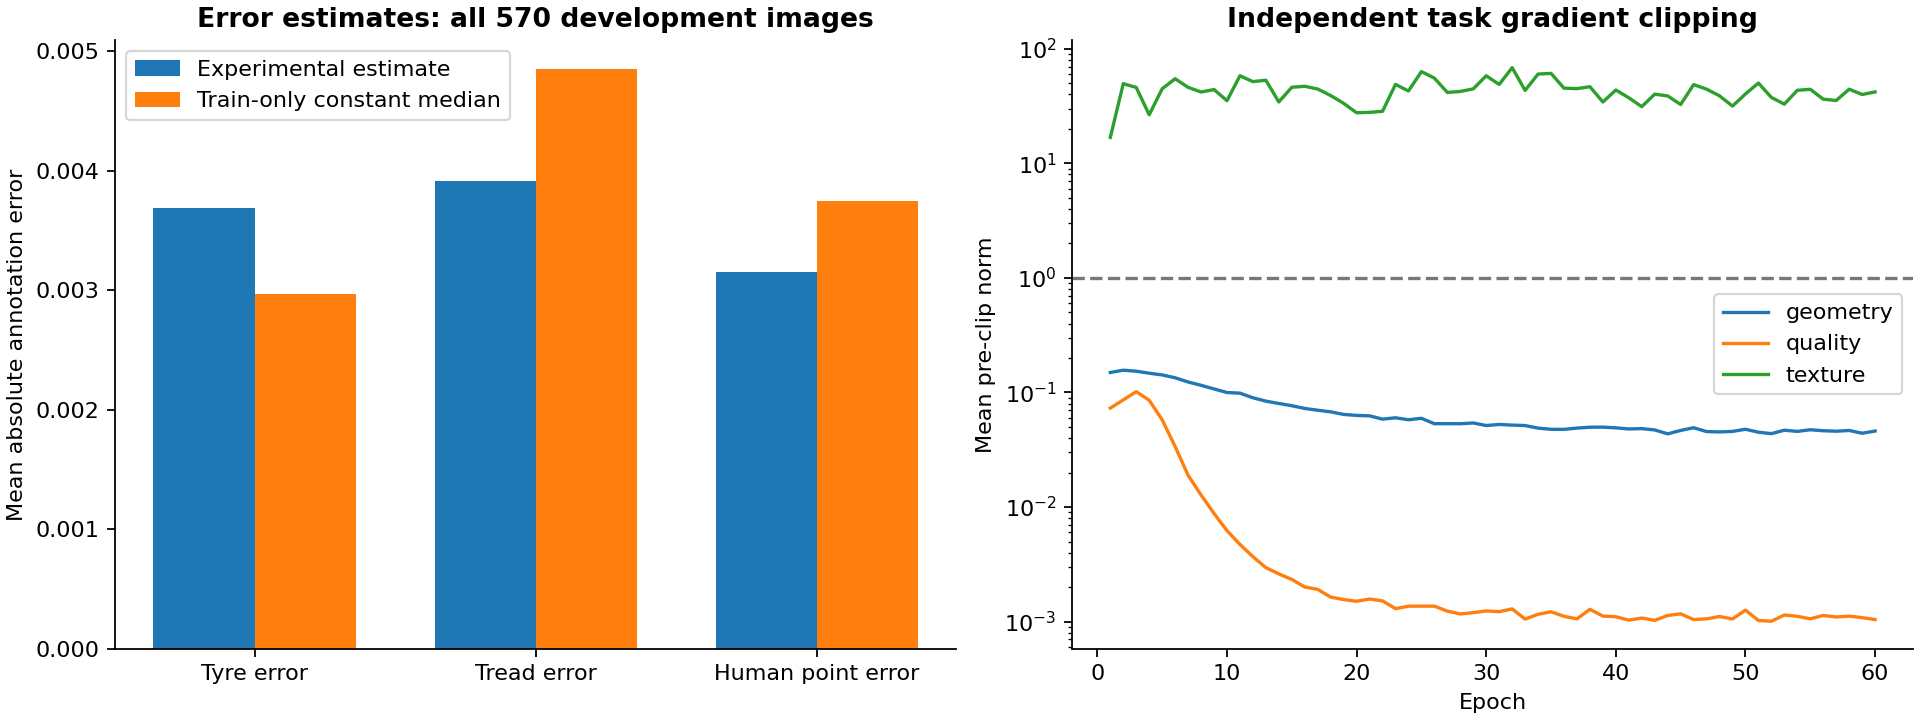

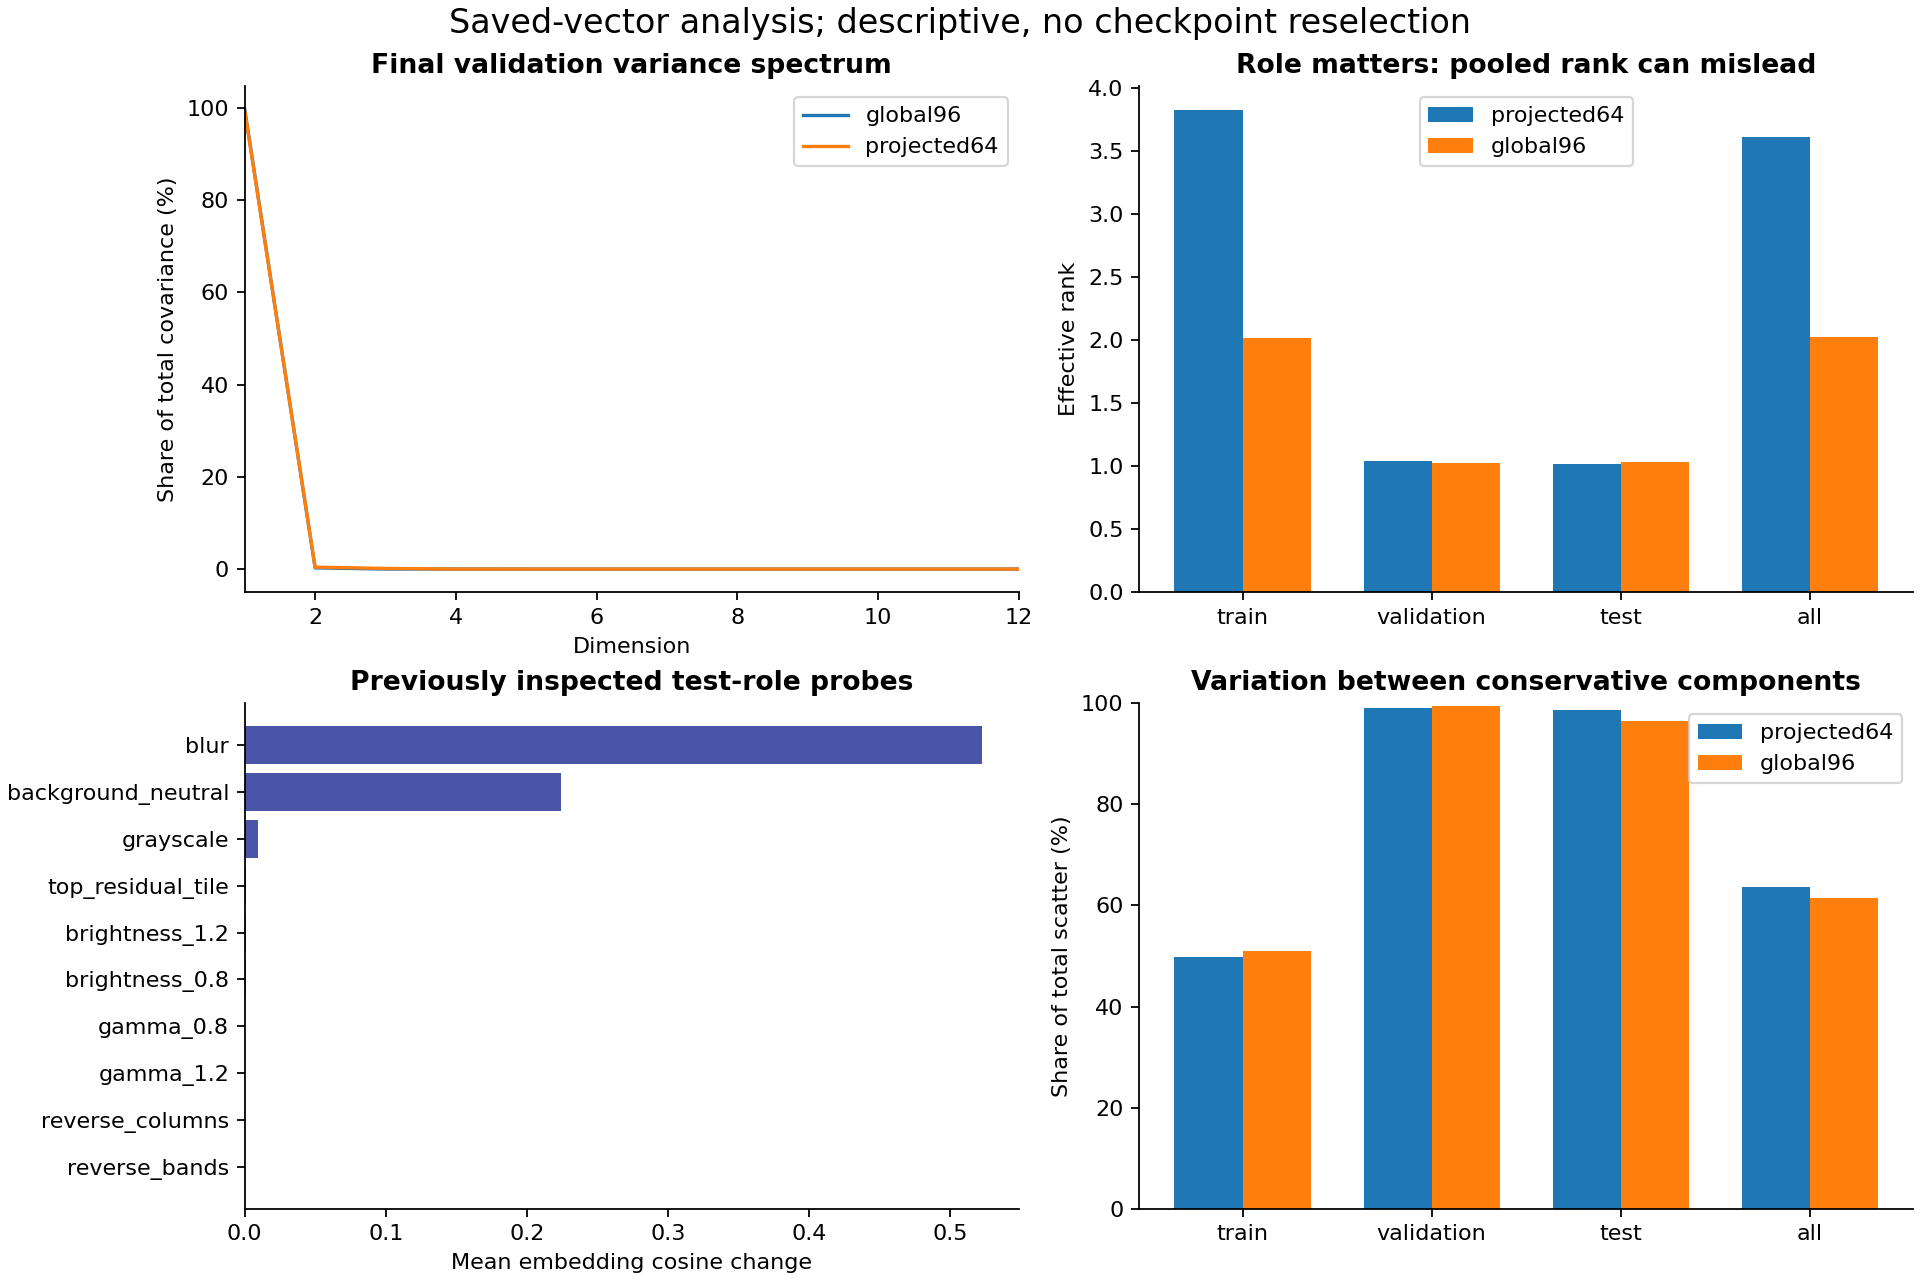

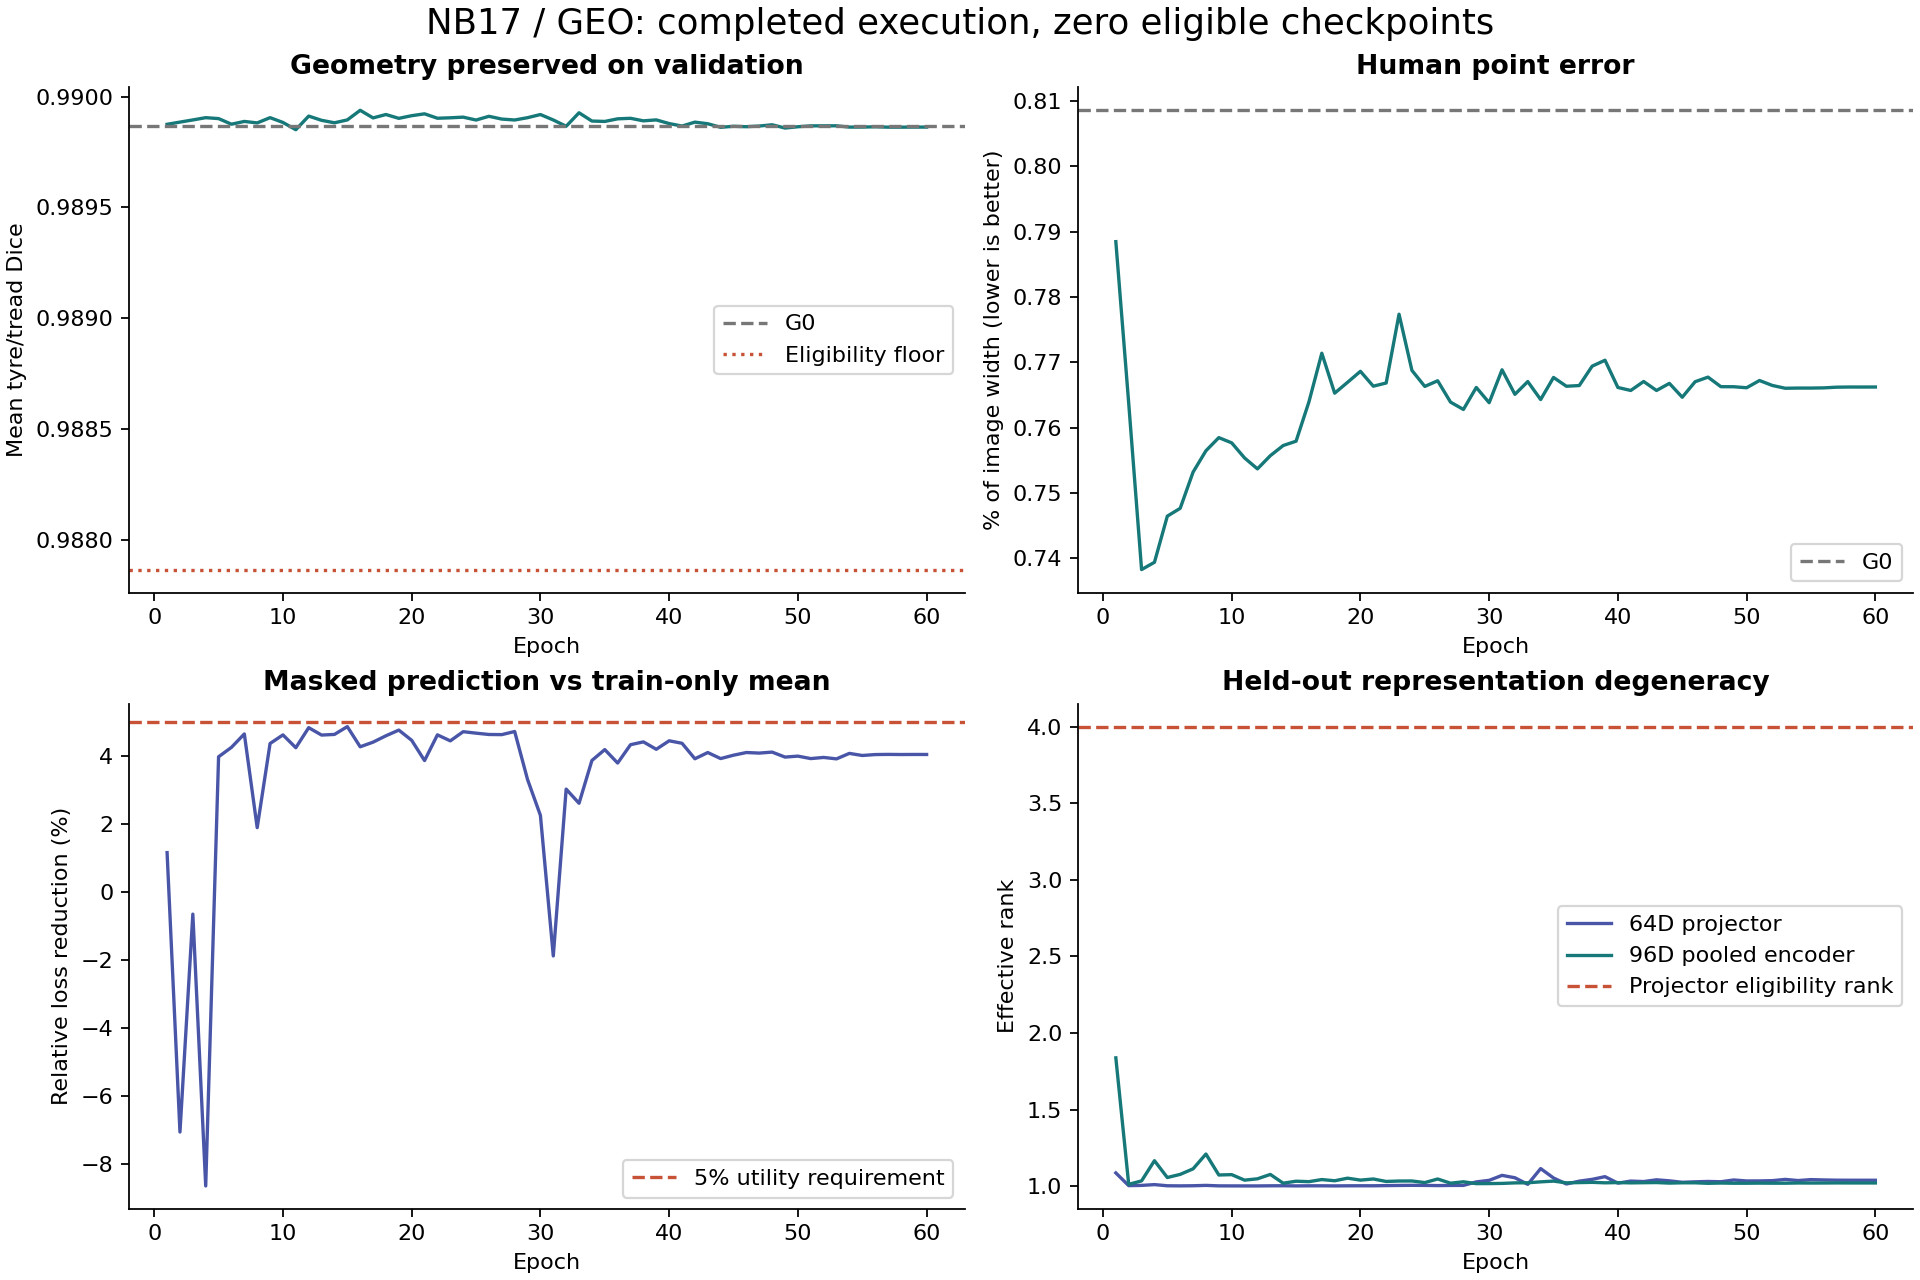

/kaggle/working/tread_two_geo_postrun/PUBLICATIONS.json

/kaggle/working/tread_two_geo_postrun/review/RESULT.json

/kaggle/working/tread_two_geo_postrun/passport/RESULT.json

Direct CSV files: 50
No new training or photo collection. GEO remains research-only and unselected.


In [3]:
# 3 · Inspect/download the durable interactive reports and direct tables.
from IPython.display import display,HTML,FileLink,Image
base=Path('/kaggle/working/tread_two_geo_postrun')
for folder,page in [('review','GEO_Review_Atlas.html'),('passport','GEO_Evidence_Passport.html')]:
    path=base/folder/page
    if path.exists():
        display(FileLink(str(path)))
        # Full 570-image atlas remains a standalone artifact; avoid duplicating
        # all its embedded images into saved notebook output.
        if folder=='passport':display(HTML(path.read_text(encoding='utf-8')))
for path in sorted((base/'review/figures').glob('*.png')):display(Image(filename=str(path)))
for path in [base/'PUBLICATIONS.json',base/'review/RESULT.json',base/'passport/RESULT.json']:
    if path.exists():display(FileLink(str(path)))
print('Direct CSV files:',sum(1 for f in ['review','passport'] for _ in (base/f).glob('*.csv')))
print('No new training or photo collection. GEO remains research-only and unselected.')


## Troubleshooting and evidence limits

| Situation | Action |
|---|---|
| Long download | The pinned input has 11,636 objects. Watch verified-file progress; keep the cache. |
| Rate-limit/backoff | Wait for the displayed server delay; do not restart a second writer. |
| Wrong/missing dataset | Attach the expanded prepared Phase 2 Kaggle input, keep files, rerun. |
| Another live owner | Stop the other notebook cleanly or wait for its 45-minute lease; never clear ownership manually. |
| CPU stage interrupted | Keep outputs and rerun Run All. Exact completed stages and verified downloads are skipped. |
| Technical audit mismatch | Stop at the gate, retain logs/cache, report the error; do not bypass hashes/tolerances. |
| No selected checkpoint | Expected completed scientific result. Final epoch remains an unselected research artifact. |

Outputs are direct CSV, JSON/Markdown, PNG/HTML and native NPY where appropriate.
There is no ZIP/NPZ envelope. All 60 epoch weights and detailed original telemetry
already remain on HF. This review adds mask-truth checks, objective reconstruction,
per-role latent spectra, calibration controls, probes, retrieval/source exclusions,
source exposure and capability limits. Richer telemetry does not create independent
tyres. The previously inspected test cohort cannot support a new blind evaluation.
